# Name: Vetcha Saketh
# Reg No: 23BDS0175
# Course Based Design Project EDA
**Course:** BCSE331L Exploratory Data Analysis  |  **Dataset:** `smoking.csv` 

In [1]:
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['figure.dpi'] = 90
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Module 1: Introduction to Exploratory Data Analysis

In [4]:
# Module 1.2 | EDA Step 1 - load the dataset and check its overall shape
df = pd.read_csv('smoking.csv')
print('Rows, columns:', df.shape)
print('Columns:', list(df.columns))

Rows, columns: (1691, 13)
Columns: ['rownames', 'gender', 'age', 'marital_status', 'highest_qualification', 'nationality', 'ethnicity', 'gross_income', 'region', 'smoke', 'amt_weekends', 'amt_weekdays', 'type']


In [5]:
# Module 1.2 | EDA Step 1 - first look at the data with head, tail and a random sample
display(df.head())
display(df.tail())
display(df.sample(5, random_state=RANDOM_STATE))

,rownames,gender,age,marital_status,highest_qualification,nationality,ethnicity,gross_income,region,smoke,amt_weekends,amt_weekdays,type
0,1,Male,38,Divorced,No Qualification,British,White,"2,600 to 5,200",The North,No,NaN,NaN,NaN
1,2,Female,42,Single,No Qualification,British,White,"Under 2,600",The North,Yes,12.0,12.0,Packets
2,3,Male,40,Married,Degree,English,White,"28,600 to 36,400",The North,No,NaN,NaN,NaN
3,4,Female,40,Married,Degree,English,White,"10,400 to 15,600",The North,No,NaN,NaN,NaN
4,5,Female,39,Married,GCSE/O Level,British,White,"2,600 to 5,200",The North,No,NaN,NaN,NaN


,rownames,gender,age,marital_status,highest_qualification,nationality,ethnicity,gross_income,region,smoke,amt_weekends,amt_weekdays,type
1686,1687,Male,22,Single,No Qualification,Scottish,White,"2,600 to 5,200",Scotland,No,NaN,NaN,NaN
1687,1688,Female,49,Divorced,Other/Sub Degree,English,White,"2,600 to 5,200",Scotland,Yes,20.0,20.0,Hand-Rolled
1688,1689,Male,45,Married,Other/Sub Degree,Scottish,White,"5,200 to 10,400",Scotland,No,NaN,NaN,NaN
1689,1690,Female,51,Married,No Qualification,English,White,"2,600 to 5,200",Scotland,Yes,20.0,20.0,Packets
1690,1691,Male,31,Married,Degree,Scottish,White,"10,400 to 15,600",Scotland,No,NaN,NaN,NaN


,rownames,gender,age,marital_status,highest_qualification,nationality,ethnicity,gross_income,region,smoke,amt_weekends,amt_weekdays,type
989,990,Female,25,Single,Degree,Other,Black,"2,600 to 5,200",London,No,NaN,NaN,NaN
1636,1637,Male,45,Married,GCSE/O Level,British,White,"15,600 to 20,800",Scotland,No,NaN,NaN,NaN
1216,1217,Male,57,Married,Degree,British,White,"Above 36,400",South East,Yes,35.0,35.0,Packets
1174,1175,Male,37,Single,ONC/BTEC,Other,White,"20,800 to 28,600",South East,No,NaN,NaN,NaN
1668,1669,Male,44,Separated,No Qualification,Scottish,White,"2,600 to 5,200",Scotland,No,NaN,NaN,NaN


In [6]:
# Module 1.2 | EDA Step 2 - structural information: dtypes, non-null counts and memory usage
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 1691 entries, 0 to 1690
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   rownames               1691 non-null   int64  
 1   gender                 1691 non-null   str    
 2   age                    1691 non-null   int64  
 3   marital_status         1691 non-null   str    
 4   highest_qualification  1691 non-null   str    
 5   nationality            1691 non-null   str    
 6   ethnicity              1691 non-null   str    
 7   gross_income           1691 non-null   str    
 8   region                 1691 non-null   str    
 9   smoke                  1691 non-null   str    
 10  amt_weekends           421 non-null    float64
 11  amt_weekdays           421 non-null    float64
 12  type                   421 non-null    str    
dtypes: float64(2), int64(2), str(9)
memory usage: 871.2 KB


In [7]:
# Module 1.2 | EDA Step 2 - descriptive statistics for numerical and categorical columns
display(df.describe().T)
cat_cols = ['gender', 'marital_status', 'highest_qualification', 'nationality', 'ethnicity',
            'gross_income', 'region', 'smoke', 'type']
display(df[cat_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
rownames,1691.0,846.000000,488.293969,1.0,423.5,846.0,1268.5,1691.0
age,1691.0,49.836192,18.736851,16.0,34.0,48.0,65.5,97.0
amt_weekends,421.0,16.410926,9.892988,0.0,10.0,15.0,20.0,60.0
amt_weekdays,421.0,13.750594,9.388292,0.0,7.0,12.0,20.0,55.0


,count,unique,top,freq
gender,1691,2,Female,965
marital_status,1691,5,Married,812
highest_qualification,1691,8,No Qualification,586
nationality,1691,8,English,833
ethnicity,1691,7,White,1560
gross_income,1691,10,"5,200 to 10,400",396
region,1691,7,Midlands & East Anglia,443
smoke,1691,2,No,1270
type,421,4,Packets,297


In [8]:
# Module 1.2 | EDA Step 2 - cardinality and frequency table of every categorical column
display(df[cat_cols].nunique().to_frame('unique_values'))
for col in cat_cols:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False).to_string())
    print()

,unique_values
gender,2
marital_status,5
highest_qualification,8
nationality,8
ethnicity,7
gross_income,10
region,7
smoke,2
type,4


--- gender ---
gender
Female    965
Male      726

--- marital_status ---
marital_status
Married      812
Single       427
Widowed      223
Divorced     161
Separated     68

--- highest_qualification ---
highest_qualification
No Qualification     586
GCSE/O Level         308
Degree               262
Other/Sub Degree     127
Higher/Sub Degree    125
A Levels             105
GCSE/CSE             102
ONC/BTEC              76

--- nationality ---
nationality
English     833
British     538
Scottish    142
Other        71
Welsh        66
Irish        23
Refused      17
Unknown       1

--- ethnicity ---
ethnicity
White      1560
Asian        41
Black        34
Chinese      27
Mixed        14
Refused      13
Unknown       2

--- gross_income ---
gross_income
5,200 to 10,400     396
10,400 to 15,600    268
2,600 to 5,200      257
15,600 to 20,800    188
20,800 to 28,600    155
Under 2,600         133
Refused             108
Above 36,400         89
28,600 to 36,400     79
Unknown             

## 1.3 Data types and measurement scales

In [9]:
# Module 1.3 | Data types - classify each column as numerical discrete, numerical continuous or categorical
def kind_of(s):
    if pd.api.types.is_numeric_dtype(s):
        vals = s.dropna()
        return 'Numerical - Discrete' if np.allclose(vals, np.round(vals)) else 'Numerical - Continuous'
    return 'Categorical'
dtype_table = pd.DataFrame({'pandas dtype': df.dtypes.astype(str), 'data type': [kind_of(df[c_]) for c_ in df.columns],
                            'unique values': df.nunique(), 'missing': df.isna().sum()})
dtype_table

,pandas dtype,data type,unique values,missing
rownames,int64,Numerical - Discrete,1691,0
gender,str,Categorical,2,0
age,int64,Numerical - Discrete,79,0
marital_status,str,Categorical,5,0
highest_qualification,str,Categorical,8,0
nationality,str,Categorical,8,0
ethnicity,str,Categorical,7,0
gross_income,str,Categorical,10,0
region,str,Categorical,7,0
smoke,str,Categorical,2,0


,column,scale,justification
0,rownames,Identifier,"Row id, carries no analytical meaning"
1,gender,Nominal,Two unordered labels
2,age,Ratio,"True zero, differences and ratios are meaningful"
3,marital_status,Nominal,Unordered labels
4,highest_qualification,Ordinal,"Ordered education levels, gaps not equal"
5,nationality,Nominal,Unordered labels
6,ethnicity,Nominal,Unordered labels
7,gross_income,Ordinal,"Ordered income bands (grouped interval, unequa..."
8,region,Nominal,Unordered labels
9,smoke,Nominal,Binary Yes/No


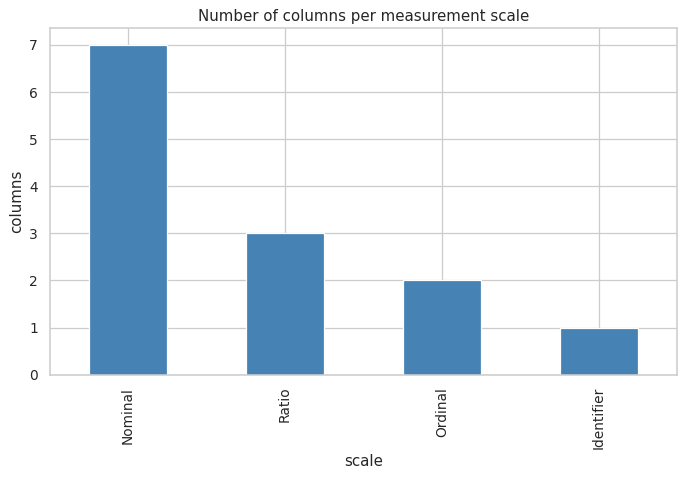

In [10]:
# Module 1.3 | Measurement scales - assign Nominal, Ordinal, Interval or Ratio to every column and justify it
scales = pd.DataFrame([
    ('rownames', 'Identifier', 'Row id, carries no analytical meaning'),
    ('gender', 'Nominal', 'Two unordered labels'),
    ('age', 'Ratio', 'True zero, differences and ratios are meaningful'),
    ('marital_status', 'Nominal', 'Unordered labels'),
    ('highest_qualification', 'Ordinal', 'Ordered education levels, gaps not equal'),
    ('nationality', 'Nominal', 'Unordered labels'),
    ('ethnicity', 'Nominal', 'Unordered labels'),
    ('gross_income', 'Ordinal', 'Ordered income bands (grouped interval, unequal widths)'),
    ('region', 'Nominal', 'Unordered labels'),
    ('smoke', 'Nominal', 'Binary Yes/No'),
    ('amt_weekends', 'Ratio', 'Cigarettes per day, true zero'),
    ('amt_weekdays', 'Ratio', 'Cigarettes per day, true zero'),
    ('type', 'Nominal', 'Unordered cigarette type')],
    columns=['column', 'scale', 'justification'])
display(scales)
scales['scale'].value_counts().plot(kind='bar', color='steelblue', title='Number of columns per measurement scale')
plt.ylabel('columns')
plt.show()

In [11]:
# Module 1.3 | Data types - show the ordering that makes qualification and income ordinal by sorting income bands numerically
income_bands = df['gross_income'].value_counts().rename_axis('gross_income').reset_index(name='count')
income_bands['lower_bound'] = income_bands['gross_income'].str.replace(',', '').str.extract(r'(\d+)')[0].astype(float)
income_bands.loc[income_bands['gross_income'] == 'Under 2,600', 'lower_bound'] = 0
income_bands.sort_values('lower_bound')

,gross_income,count,lower_bound
5,"Under 2,600",133,0.0
2,"2,600 to 5,200",257,2600.0
0,"5,200 to 10,400",396,5200.0
1,"10,400 to 15,600",268,10400.0
3,"15,600 to 20,800",188,15600.0
4,"20,800 to 28,600",155,20800.0
8,"28,600 to 36,400",79,28600.0
7,"Above 36,400",89,36400.0
6,Refused,108,NaN
9,Unknown,18,NaN


## 1.4 Comparing EDA with Classical and Bayesian analysis
The same question - *does smoking prevalence differ between men and women?* - is approached in three ways.

,No,Yes,smoking_rate
gender,,,
Female,731,234,0.242487
Male,539,187,0.257576


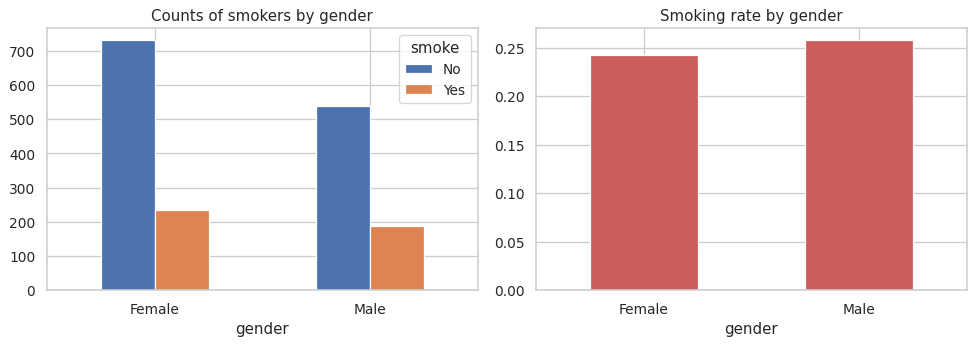

In [12]:
# Module 1.4 | EDA approach - visually explore smoking prevalence by gender without assuming a model
eda_tab = pd.crosstab(df['gender'], df['smoke'])
eda_rate = (eda_tab['Yes'] / eda_tab.sum(axis=1)).rename('smoking_rate')
display(eda_tab.join(eda_rate))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
eda_tab.plot(kind='bar', ax=ax[0], rot=0, title='Counts of smokers by gender')
eda_rate.plot(kind='bar', ax=ax[1], rot=0, color='indianred', title='Smoking rate by gender')
plt.tight_layout()
plt.show()

In [13]:
# Module 1.4 | Classical approach - chi-square test, two-proportion z-test and confidence interval for the difference
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
chi2, p_chi, dof, _ = stats.chi2_contingency(eda_tab)
counts = eda_tab['Yes'].values
nobs = eda_tab.sum(axis=1).values
z, p_z = proportions_ztest(counts, nobs)
ci_low, ci_high = confint_proportions_2indep(counts[0], nobs[0], counts[1], nobs[1])
print(f'Chi-square = {chi2:.4f}, dof = {dof}, p = {p_chi:.4f}')
print(f'Two-proportion z = {z:.4f}, p = {p_z:.4f}')
print(f'95% CI for rate({eda_tab.index[0]}) - rate({eda_tab.index[1]}): [{ci_low:.4f}, {ci_high:.4f}]')
print('Decision at 5%:', 'reject H0 (rates differ)' if p_chi < 0.05 else 'fail to reject H0 (no evidence of difference)')

Chi-square = 0.4270, dof = 1, p = 0.5135
Two-proportion z = -0.7103, p = 0.4775
95% CI for rate(Female) - rate(Male): [-0.0571, 0.0263]
Decision at 5%: fail to reject H0 (no evidence of difference)


Posterior mean rate Female: 0.2430  95% credible interval: [0.2164 0.2704]
Posterior mean rate Male: 0.2583  95% credible interval: [0.227  0.2908]
P(Female rate > Male rate) = 0.2365
95% credible interval of the difference: [-0.0572  0.0265]


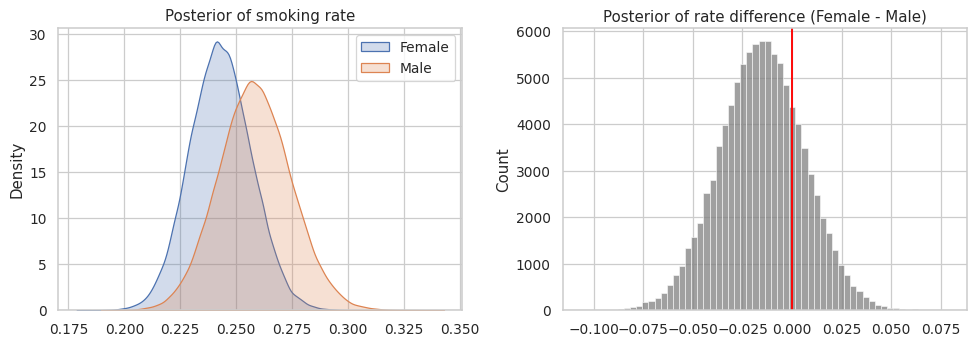

In [14]:
# Module 1.4 | Bayesian approach - Beta-Binomial posterior for each gender and probability that one rate exceeds the other
rng = np.random.default_rng(RANDOM_STATE)
posterior = {}
for g in eda_tab.index:
    a, b = 1 + eda_tab.loc[g, 'Yes'], 1 + eda_tab.loc[g, 'No']
    posterior[g] = rng.beta(a, b, 100000)
g1, g2 = eda_tab.index
diff = posterior[g1] - posterior[g2]
print(f'Posterior mean rate {g1}: {posterior[g1].mean():.4f}  95% credible interval: {np.percentile(posterior[g1], [2.5, 97.5]).round(4)}')
print(f'Posterior mean rate {g2}: {posterior[g2].mean():.4f}  95% credible interval: {np.percentile(posterior[g2], [2.5, 97.5]).round(4)}')
print(f'P({g1} rate > {g2} rate) = {(diff > 0).mean():.4f}')
print(f'95% credible interval of the difference: {np.percentile(diff, [2.5, 97.5]).round(4)}')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for g in eda_tab.index:
    sns.kdeplot(posterior[g], ax=ax[0], fill=True, label=g)
ax[0].set_title('Posterior of smoking rate')
ax[0].legend()
sns.histplot(diff, bins=60, ax=ax[1], color='gray')
ax[1].axvline(0, color='red')
ax[1].set_title(f'Posterior of rate difference ({g1} - {g2})')
plt.tight_layout()
plt.show()

In [15]:
# Module 1.4 | Comparison table - how EDA, classical and Bayesian analysis answer the same question
pd.DataFrame({
    'aspect': ['Starting point', 'Assumptions', 'Output', 'Uncertainty', 'Answer obtained here'],
    'EDA': ['Data first, no hypothesis', 'Minimal', 'Plots and summaries', 'Visual only',
            f'Rates {eda_rate.round(3).to_dict()}'],
    'Classical': ['Hypothesis first', 'Model and sampling distribution', 'p-value, confidence interval', 'Confidence interval',
                  f'p = {p_chi:.4f}'],
    'Bayesian': ['Prior plus data', 'Prior and likelihood', 'Posterior distribution', 'Credible interval',
                 f'P(rate difference > 0) = {(diff > 0).mean():.3f}']}).set_index('aspect')

,EDA,Classical,Bayesian
aspect,,,
Starting point,"Data first, no hypothesis",Hypothesis first,Prior plus data
Assumptions,Minimal,Model and sampling distribution,Prior and likelihood
Output,Plots and summaries,"p-value, confidence interval",Posterior distribution
Uncertainty,Visual only,Confidence interval,Credible interval
Answer obtained here,"Rates {'Female': 0.242, 'Male': 0.258}",p = 0.5135,P(rate difference > 0) = 0.237


# Module 2: Data Transformation

## 2.1 Data deduplication

In [16]:
# Module 2.1 | Deduplication - detect duplicate respondents, ignoring the row-id column
subset_cols = [col for col in df.columns if col != 'rownames']
print('Duplicates including rownames:', df.duplicated().sum())
print('Duplicates ignoring rownames :', df.duplicated(subset=subset_cols).sum())
display(df[df.duplicated(subset=subset_cols, keep=False)].sort_values(subset_cols).head(10))

Duplicates including rownames: 0
Duplicates ignoring rownames : 21


,rownames,gender,age,marital_status,highest_qualification,nationality,ethnicity,gross_income,region,smoke,amt_weekends,amt_weekdays,type
227,228,Female,33,Single,ONC/BTEC,British,White,"15,600 to 20,800",The North,No,NaN,NaN,NaN
299,300,Female,33,Single,ONC/BTEC,British,White,"15,600 to 20,800",The North,No,NaN,NaN,NaN
5,6,Female,37,Married,GCSE/O Level,British,White,"15,600 to 20,800",The North,No,NaN,NaN,NaN
190,191,Female,37,Married,GCSE/O Level,British,White,"15,600 to 20,800",The North,No,NaN,NaN,NaN
201,202,Female,38,Married,GCSE/O Level,English,White,"5,200 to 10,400",The North,No,NaN,NaN,NaN
281,282,Female,38,Married,GCSE/O Level,English,White,"5,200 to 10,400",The North,No,NaN,NaN,NaN
462,463,Female,55,Married,Higher/Sub Degree,English,White,"2,600 to 5,200",Midlands & East Anglia,No,NaN,NaN,NaN
643,644,Female,55,Married,Higher/Sub Degree,English,White,"2,600 to 5,200",Midlands & East Anglia,No,NaN,NaN,NaN
101,102,Female,64,Married,No Qualification,English,White,"Under 2,600",The North,No,NaN,NaN,NaN
338,339,Female,64,Married,No Qualification,English,White,"Under 2,600",The North,No,NaN,NaN,NaN


In [17]:
# Module 2.1 | Deduplication - drop duplicate records (keep first) and verify the result
data = df.drop_duplicates(subset=subset_cols, keep='first').reset_index(drop=True)
print('Shape before:', df.shape, '| after:', data.shape)
print('Remaining duplicates:', data.duplicated(subset=subset_cols).sum())
print('rownames unique:', data['rownames'].is_unique)

Shape before: (1691, 13) | after: (1670, 13)
Remaining duplicates: 0
rownames unique: True


## 2.2 Replacing values

In [18]:
# Module 2.2 | Replacing values - convert the placeholder labels 'Refused' and 'Unknown' into proper missing values
placeholder_cols = ['nationality', 'ethnicity', 'gross_income']
before = data[placeholder_cols].apply(lambda s: s.isin(['Refused', 'Unknown']).sum())
data[placeholder_cols] = data[placeholder_cols].replace({'Refused': np.nan, 'Unknown': np.nan})
after = data[placeholder_cols].isna().sum()
pd.DataFrame({'placeholders before': before, 'NaN after': after})

,placeholders before,NaN after
nationality,18,18
ethnicity,15,15
gross_income,124,124


In [19]:
# Module 2.2 | Replacing values - map nationality to broader groups and smoke to a binary flag using dictionaries
nat_map = {'English': 'UK', 'British': 'UK', 'Scottish': 'UK', 'Welsh': 'UK', 'Irish': 'Irish', 'Other': 'Other'}
data['nationality_group'] = data['nationality'].replace(nat_map)
data['smoke_flag'] = data['smoke'].map({'Yes': 1, 'No': 0})
display(pd.crosstab(data['nationality'], data['nationality_group'], dropna=False))
display(data['smoke_flag'].value_counts())

nationality_group,Irish,Other,UK,NaN
nationality,,,,
British,0,0,533,0
English,0,0,818,0
Irish,23,0,0,0
Other,0,70,0,0
Scottish,0,0,142,0
Welsh,0,0,66,0
NaN,0,0,0,18


smoke_flag
0    1249
1     421
Name: count, dtype: int64

## 2.3 Discretization and binning

,count
age_group,
16-24,144
25-34,280
35-44,322
45-54,250
55-64,238
65-74,232
75+,204


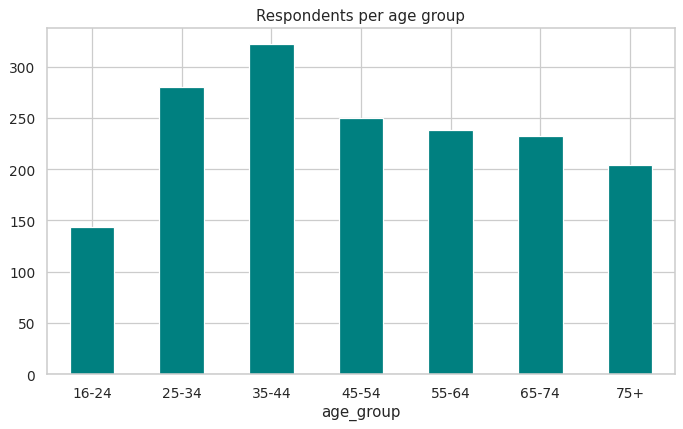

In [20]:
# Module 2.3 | Binning - equal-width bins with pd.cut using meaningful age-group edges
age_edges = [15, 24, 34, 44, 54, 64, 74, 100]
age_labels = ['16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75+']
data['age_group'] = pd.cut(data['age'], bins=age_edges, labels=age_labels)
display(data['age_group'].value_counts().sort_index().to_frame('count'))
data['age_group'].value_counts().sort_index().plot(kind='bar', color='teal', title='Respondents per age group', rot=0)
plt.show()

In [21]:
# Module 2.3 | Discretization - equal-frequency bins (quartiles and deciles) with pd.qcut on age
age_quartile = pd.qcut(data['age'], q=4, labels=['Q1 youngest', 'Q2', 'Q3', 'Q4 oldest'])
age_decile = pd.qcut(data['age'], q=10)
display(pd.DataFrame({'quartile count': age_quartile.value_counts().sort_index()}))
display(age_decile.value_counts().sort_index().to_frame('decile count'))

,quartile count
age,
Q1 youngest,424
Q2,421
Q3,413
Q4 oldest,412


,decile count
age,
"(15.999, 26.0]",181
"(26.0, 32.0]",168
"(32.0, 37.0]",170
"(37.0, 42.0]",174
"(42.0, 48.0]",152
"(48.0, 55.0]",181
"(55.0, 62.0]",160
"(62.0, 69.0]",171
"(69.0, 76.0]",153


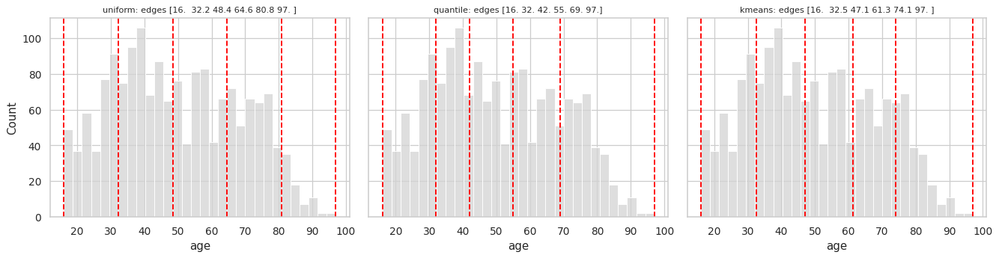

In [22]:
# Module 2.3 | Discretization - compare uniform, quantile and k-means strategies of KBinsDiscretizer on age
from sklearn.preprocessing import KBinsDiscretizer
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, strat in zip(axes, ['uniform', 'quantile', 'kmeans']):
    kb = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy=strat)
    kb.fit(data[['age']])
    edges = kb.bin_edges_[0]
    sns.histplot(data['age'], bins=30, ax=ax, color='lightgray')
    for e in edges:
        ax.axvline(e, color='red', linestyle='--')
    ax.set_title(f'{strat}: edges {np.round(edges, 1)}', fontsize=9)
plt.tight_layout()
plt.show()

,weekday,weekend
Light (<=5),84,61
Moderate (6-10),125,95
Heavy (11-20),161,188
Very heavy (>20),51,77


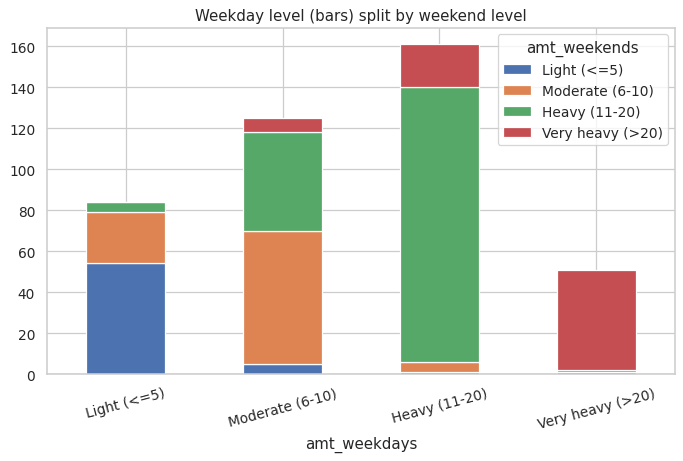

In [23]:
# Module 2.3 | Binning - discretise the daily cigarette consumption of smokers into Light, Moderate, Heavy and Very heavy
smokers_only = data[data['smoke'] == 'Yes']
amt_edges = [-1, 5, 10, 20, 100]
amt_labels = ['Light (<=5)', 'Moderate (6-10)', 'Heavy (11-20)', 'Very heavy (>20)']
weekday_level = pd.cut(smokers_only['amt_weekdays'], bins=amt_edges, labels=amt_labels)
weekend_level = pd.cut(smokers_only['amt_weekends'], bins=amt_edges, labels=amt_labels)
display(pd.concat([weekday_level.value_counts().sort_index().rename('weekday'),
                   weekend_level.value_counts().sort_index().rename('weekend')], axis=1))
pd.crosstab(weekday_level, weekend_level).plot(kind='bar', stacked=True, rot=15, title='Weekday level (bars) split by weekend level')
plt.show()

## 2.4 Missing data: diagnosis

In [24]:
# Module 2.4 | Missing data - count and percentage of missing values per column
missing_summary = pd.DataFrame({'missing': data.isna().sum(), 'percent': (data.isna().mean() * 100).round(2)})
missing_summary[missing_summary['missing'] > 0].sort_values('missing', ascending=False)

,missing,percent
type,1249,74.79
amt_weekdays,1249,74.79
amt_weekends,1249,74.79
gross_income,124,7.43
nationality,18,1.08
nationality_group,18,1.08
ethnicity,15,0.90


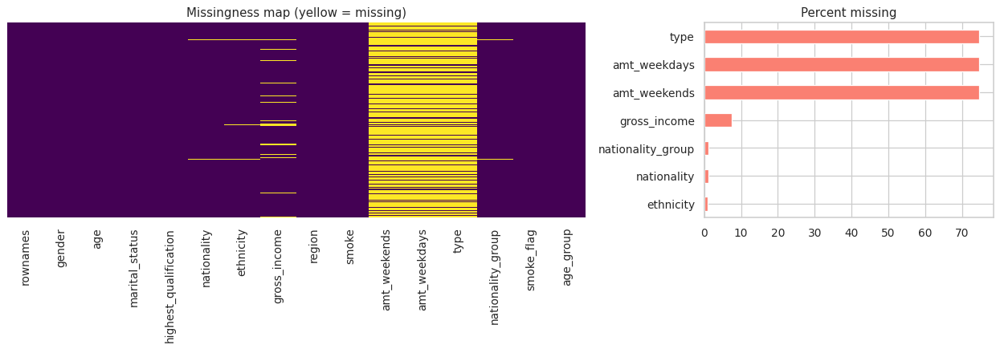

In [25]:
# Module 2.4 | Missing data - heatmap of missingness across all records and bar chart of missing percentage
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})
sns.heatmap(data.isna(), cbar=False, yticklabels=False, cmap='viridis', ax=ax[0])
ax[0].set_title('Missingness map (yellow = missing)')
missing_summary[missing_summary['missing'] > 0]['percent'].sort_values().plot(kind='barh', ax=ax[1], color='salmon')
ax[1].set_title('Percent missing')
plt.tight_layout()
plt.show()

In [26]:
# Module 2.4 | Missing data - distinct missingness patterns and how often each occurs
pattern = data.isna().value_counts().rename('records').reset_index()
pattern[[cn for cn in pattern.columns if cn == 'records' or pattern[cn].any()]]

,nationality,ethnicity,gross_income,amt_weekends,amt_weekdays,type,nationality_group,records
0,False,False,False,True,True,True,False,1147
1,False,False,False,False,False,False,False,395
2,False,False,True,True,True,True,False,87
3,False,False,True,False,False,False,False,20
4,True,True,True,True,True,True,True,8
5,True,False,True,True,True,True,True,5
6,True,True,True,False,False,False,True,3
7,True,False,False,False,False,False,True,1
8,False,True,True,False,False,False,False,1
9,False,True,False,True,True,True,False,1


In [27]:
# Module 2.4 | Missing data - show that missing consumption values are structural (they occur exactly for non-smokers)
display(pd.crosstab(data['smoke'], data['amt_weekdays'].isna(), rownames=['smoke'], colnames=['amt_weekdays missing']))
display(pd.crosstab(data['smoke'], data['type'].isna(), rownames=['smoke'], colnames=['type missing']))
print('Missing weekday and weekend amounts coincide:', (data['amt_weekdays'].isna() == data['amt_weekends'].isna()).all())

amt_weekdays missing,False,True
smoke,,
No,0,1249
Yes,421,0


type missing,False,True
smoke,,
No,0,1249
Yes,421,0


Missing weekday and weekend amounts coincide: True


In [28]:
# Module 2.4 | Missing data - test whether missing income, nationality and ethnicity depend on observed variables (MCAR vs MAR)
rows = []
for target in ['gross_income', 'nationality', 'ethnicity']:
    flag = data[target].isna()
    for pred in ['gender', 'region', 'marital_status', 'highest_qualification', 'smoke']:
        p = stats.chi2_contingency(pd.crosstab(data[pred], flag))[1]
        rows.append((target, pred, 'chi-square', p))
    p = stats.ttest_ind(data.loc[flag, 'age'], data.loc[~flag, 'age'], equal_var=False)[1]
    rows.append((target, 'age', 'Welch t-test', p))
mcar_tests = pd.DataFrame(rows, columns=['missing variable', 'compared with', 'test', 'p-value'])
mcar_tests['dependent at 5%'] = mcar_tests['p-value'] < 0.05
mcar_tests.pivot(index='missing variable', columns='compared with', values='p-value').round(4)

compared with,age,gender,highest_qualification,marital_status,region,smoke
missing variable,,,,,,
ethnicity,0.5629,0.9750,0.1251,0.5952,0.3771,0.6678
gross_income,0.0971,0.2792,0.0005,0.0938,0.0720,0.1462
nationality,0.5914,0.5565,0.4620,0.8566,0.0627,0.9836


## 2.5 Missing data: traditional methods
Consumption is missing structurally for non-smokers, so imputation methods are compared on a controlled experiment: 20% of the known weekday consumption of smokers is hidden, imputed by each method, and compared with the true values.

In [29]:
# Module 2.5 | Traditional methods - hide 20% of smokers' weekday consumption completely at random to create ground truth
rng = np.random.default_rng(RANDOM_STATE)
sm = data.loc[data['smoke'] == 'Yes', ['age', 'amt_weekends', 'amt_weekdays']].reset_index(drop=True)
hide_idx = rng.choice(sm.index, size=int(0.2 * len(sm)), replace=False)
truth = sm.loc[hide_idx, 'amt_weekdays'].copy()
sm_gap = sm.copy()
sm_gap.loc[hide_idx, 'amt_weekdays'] = np.nan
print('Smokers:', len(sm), '| hidden values:', len(hide_idx), '| missing now:', sm_gap['amt_weekdays'].isna().sum())

Smokers: 421 | hidden values: 84 | missing now: 84


In [30]:
# Module 2.5 | Traditional methods - listwise (complete-case) and pairwise deletion and their effect on sample size and statistics
complete = sm_gap.dropna()
print('Rows before:', len(sm_gap), '| after listwise deletion:', len(complete), f'({100 * (1 - len(complete) / len(sm_gap)):.1f}% lost)')
pd.DataFrame({'full data': sm.describe().loc[['mean', 'std']].T.stack(),
              'after listwise deletion': complete.describe().loc[['mean', 'std']].T.stack()})

Rows before: 421 | after listwise deletion: 337 (20.0% lost)


full data  after listwise deletion
age          mean  42.714964                42.697329
             std   16.179631                15.958757
amt_weekends mean  16.410926                16.780415
             std    9.892988                10.056944
amt_weekdays mean  13.750594                13.848665
             std    9.388292                 9.527729

In [31]:
# Module 2.5 | Traditional methods - single imputation: mean, median, mode, constant, forward fill, backward fill, interpolation
col = sm_gap['amt_weekdays']
imputed = {
    'Mean': col.fillna(col.mean()),
    'Median': col.fillna(col.median()),
    'Mode': col.fillna(col.mode()[0]),
    'Constant 0': col.fillna(0),
    'Forward fill': col.ffill().bfill(),
    'Backward fill': col.bfill().ffill(),
    'Linear interpolation': col.interpolate(limit_direction='both')}
{name: s.isna().sum() for name, s in imputed.items()}

{'Mean': np.int64(0),
 'Median': np.int64(0),
 'Mode': np.int64(0),
 'Constant 0': np.int64(0),
 'Forward fill': np.int64(0),
 'Backward fill': np.int64(0),
 'Linear interpolation': np.int64(0)}

In [32]:
# Module 2.5 | Traditional methods - model-based imputers: group mean, regression, k-nearest neighbours and iterative (chained equations)
from sklearn.linear_model import LinearRegression
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
age_bucket = pd.cut(sm_gap['age'], [15, 34, 54, 100])
imputed['Group mean (age bucket)'] = col.fillna(col.groupby(age_bucket).transform('mean'))
obs = sm_gap['amt_weekdays'].notna()
reg = LinearRegression().fit(sm_gap.loc[obs, ['age', 'amt_weekends']], sm_gap.loc[obs, 'amt_weekdays'])
reg_fill = col.copy()
reg_fill[~obs] = reg.predict(sm_gap.loc[~obs, ['age', 'amt_weekends']])
imputed['Regression'] = reg_fill
imputed['KNN (k=5)'] = pd.Series(KNNImputer(n_neighbors=5).fit_transform(sm_gap)[:, 2], index=sm_gap.index)
imputed['Iterative (MICE-style)'] = pd.Series(IterativeImputer(random_state=RANDOM_STATE, max_iter=20).fit_transform(sm_gap)[:, 2], index=sm_gap.index)
list(imputed.keys())

['Mean',
 'Median',
 'Mode',
 'Constant 0',
 'Forward fill',
 'Backward fill',
 'Linear interpolation',
 'Group mean (age bucket)',
 'Regression',
 'KNN (k=5)',
 'Iterative (MICE-style)']

## 2.6 Missing data: Maximum Likelihood Estimation (EM algorithm)

EM converged after 8 iterations


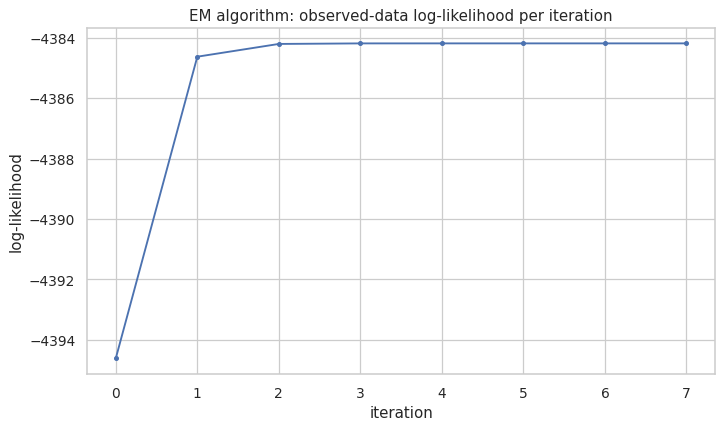

In [33]:
# Module 2.6 | Maximum likelihood estimation - implement the EM algorithm for a multivariate normal with missing values
def em_mvn(X, n_iter=200, tol=1e-7):
    X = np.asarray(X, dtype=float)
    n, p = X.shape
    miss = np.isnan(X)
    mu = np.nanmean(X, axis=0)
    sigma = np.cov(np.where(miss, mu, X), rowvar=False) + 1e-6 * np.eye(p)
    history = []
    for it in range(n_iter):
        T1 = np.zeros(p)
        T2 = np.zeros((p, p))
        loglik = 0.0
        filled = X.copy()
        for i in range(n):
            m, o = miss[i], ~miss[i]
            xi = X[i].copy()
            C = np.zeros((p, p))
            soo = sigma[np.ix_(o, o)]
            d = X[i, o] - mu[o]
            if m.any():
                smo = sigma[np.ix_(m, o)]
                gain = smo @ np.linalg.inv(soo)
                xi[m] = mu[m] + gain @ d
                C[np.ix_(m, m)] = sigma[np.ix_(m, m)] - gain @ smo.T
            filled[i] = xi
            T1 += xi
            T2 += np.outer(xi, xi) + C
            loglik += -0.5 * (o.sum() * np.log(2 * np.pi) + np.linalg.slogdet(soo)[1] + d @ np.linalg.solve(soo, d))
        mu = T1 / n
        sigma = T2 / n - np.outer(mu, mu)
        history.append(loglik)
        if it > 0 and abs(history[-1] - history[-2]) < tol:
            break
    return mu, sigma, filled, history

mu_em, sigma_em, filled_em, ll_history = em_mvn(sm_gap.values)
imputed['EM (maximum likelihood)'] = pd.Series(filled_em[:, 2], index=sm_gap.index)
print('EM converged after', len(ll_history), 'iterations')
plt.plot(ll_history, marker='o', markersize=3)
plt.title('EM algorithm: observed-data log-likelihood per iteration')
plt.xlabel('iteration')
plt.ylabel('log-likelihood')
plt.show()

In [34]:
# Module 2.6 | Maximum likelihood estimation - compare ML estimates of mean and covariance with available-case estimates and the full data
est = pd.DataFrame({'full data mean': sm.mean(), 'observed-only mean': sm_gap.mean(), 'EM (MLE) mean': mu_em}, index=sm.columns)
display(est.round(3))
cov_cmp = pd.concat({'full data': sm.cov(), 'EM (MLE)': pd.DataFrame(sigma_em, index=sm.columns, columns=sm.columns)}, axis=1)
display(cov_cmp.round(2))
mu_norm, sd_norm = stats.norm.fit(sm['amt_weekdays'])
print(f'Normal MLE of full weekday data: mean = {mu_norm:.3f}, sd (MLE, ddof=0) = {sd_norm:.3f}')

,full data mean,observed-only mean,EM (MLE) mean
age,42.715,42.715,42.715
amt_weekends,16.411,16.411,16.411
amt_weekdays,13.751,13.849,13.574


full data                           EM (MLE)                          
                   age amt_weekends amt_weekdays      age amt_weekends amt_weekdays
age             261.78         9.39        29.28   261.16         9.36        31.75
amt_weekends      9.39        97.87        74.49     9.36        97.64        73.95
amt_weekdays     29.28        74.49        88.14    31.75        73.95        88.89

Normal MLE of full weekday data: mean = 13.751, sd (MLE, ddof=0) = 9.377


,RMSE,MAE,bias,std ratio vs truth
method,,,,
EM (maximum likelihood),5.053,4.230,-0.886,0.970
Regression,5.053,4.230,-0.886,0.970
Iterative (MICE-style),5.053,4.234,-0.881,0.970
KNN (k=5),6.243,4.938,-0.581,0.976
Mean,8.811,6.962,0.492,0.908
Median,8.902,6.786,-1.357,0.911
Group mean (age bucket),8.942,7.066,0.461,0.917
Linear interpolation,10.960,8.714,0.357,0.965
Mode,11.024,9.143,6.643,0.945


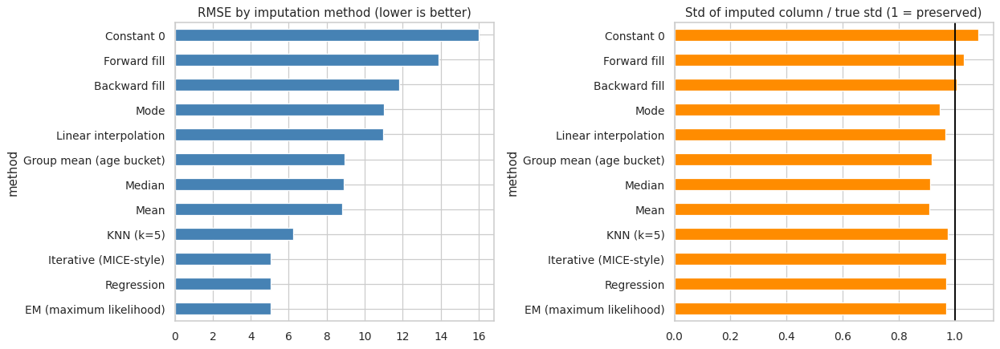

In [35]:
# Module 2.6 | Evaluate all imputation methods - RMSE, MAE, bias and variance preservation against the hidden true values
from sklearn.metrics import mean_squared_error, mean_absolute_error
rows = []
for name, s in imputed.items():
    pred = s.loc[hide_idx]
    rows.append((name, np.sqrt(mean_squared_error(truth, pred)), mean_absolute_error(truth, pred),
                 (pred - truth).mean(), s.std() / sm['amt_weekdays'].std()))
impute_eval = pd.DataFrame(rows, columns=['method', 'RMSE', 'MAE', 'bias', 'std ratio vs truth']).set_index('method').sort_values('RMSE')
display(impute_eval.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
impute_eval['RMSE'].plot(kind='barh', ax=ax[0], color='steelblue', title='RMSE by imputation method (lower is better)')
impute_eval['std ratio vs truth'].plot(kind='barh', ax=ax[1], color='darkorange', title='Std of imputed column / true std (1 = preserved)')
ax[1].axvline(1, color='black')
plt.tight_layout()
plt.show()

## 2.7 Handling missing data in the real dataset

In [36]:
# Module 2.7 | Handling missing data - impute categorical gaps (ethnicity, nationality) with the mode and income with the mode of its qualification group
clean = data.copy()
for col_name in ['ethnicity', 'nationality']:
    clean[col_name] = clean[col_name].fillna(clean[col_name].mode()[0])
clean['gross_income'] = clean.groupby('highest_qualification')['gross_income'].transform(lambda s: s.fillna(s.mode().iloc[0]))
clean['nationality_group'] = clean['nationality'].replace(nat_map)
print('Remaining missing in categorical columns:', clean[['ethnicity', 'nationality', 'gross_income', 'nationality_group']].isna().sum().sum())

Remaining missing in categorical columns: 0


In [37]:
# Module 2.7 | Handling missing data - resolve structural gaps: non-smokers consume 0 cigarettes and get type 'Non-smoker'
clean['amt_weekends'] = clean['amt_weekends'].fillna(0)
clean['amt_weekdays'] = clean['amt_weekdays'].fillna(0)
clean['type'] = clean['type'].fillna('Non-smoker')
clean['type_simple'] = clean['type'].replace({'Both/Mainly Packets': 'Packets', 'Both/Mainly Hand-Rolled': 'Hand-Rolled'})
print('Total missing values left:', clean.isna().sum().sum())
display(clean['type'].value_counts())
display(clean['type_simple'].value_counts())

Total missing values left: 0


type
Non-smoker                 1249
Packets                     297
Hand-Rolled                  72
Both/Mainly Packets          42
Both/Mainly Hand-Rolled      10
Name: count, dtype: int64

type_simple
Non-smoker     1249
Packets         339
Hand-Rolled      82
Name: count, dtype: int64

In [38]:
# Module 2.7 | Handling missing data - encode ordinal categories (qualification, income) and binary flags as numeric levels
qual_order = ['No Qualification', 'GCSE/CSE', 'GCSE/O Level', 'Other/Sub Degree', 'ONC/BTEC', 'Higher/Sub Degree', 'A Levels', 'Degree']
income_order = ['Under 2,600', '2,600 to 5,200', '5,200 to 10,400', '10,400 to 15,600',
                '15,600 to 20,800', '20,800 to 28,600', '28,600 to 36,400', 'Above 36,400']
clean['qual_level'] = clean['highest_qualification'].map({v: i for i, v in enumerate(qual_order)})
clean['income_level'] = clean['gross_income'].map({v: i for i, v in enumerate(income_order)})
clean['gender_flag'] = clean['gender'].map({'Male': 1, 'Female': 0})
clean['married_flag'] = (clean['marital_status'] == 'Married').astype(int)
clean['gross_income'] = pd.Categorical(clean['gross_income'], categories=income_order, ordered=True)
clean['highest_qualification'] = pd.Categorical(clean['highest_qualification'], categories=qual_order, ordered=True)
print('Unmapped values:', clean[['qual_level', 'income_level']].isna().sum().to_dict())
clean[['highest_qualification', 'qual_level', 'gross_income', 'income_level']].drop_duplicates().sort_values('income_level').head(10)

Unmapped values: {'qual_level': 0, 'income_level': 0}


,highest_qualification,qual_level,gross_income,income_level
1,No Qualification,0,"Under 2,600",0
31,GCSE/CSE,1,"Under 2,600",0
43,Degree,7,"Under 2,600",0
1206,ONC/BTEC,4,"Under 2,600",0
280,A Levels,6,"Under 2,600",0
790,Other/Sub Degree,3,"Under 2,600",0
137,GCSE/O Level,2,"Under 2,600",0
209,Higher/Sub Degree,5,"Under 2,600",0
99,Higher/Sub Degree,5,"2,600 to 5,200",1
87,A Levels,6,"2,600 to 5,200",1


In [39]:
# Module 2.7 | Handling missing data - one-hot encode the nominal columns (marital status, region, ethnicity, nationality group, type)
onehot_cols = ['marital_status', 'region', 'ethnicity', 'nationality_group', 'type_simple']
onehot = pd.get_dummies(clean[onehot_cols], dtype=int)
print('One-hot matrix shape:', onehot.shape)
onehot.head()

One-hot matrix shape: (1670, 23)


,marital_status_Divorced,marital_status_Married,marital_status_Separated,marital_status_Single,marital_status_Widowed,region_London,region_Midlands & East Anglia,region_Scotland,region_South East,region_South West,region_The North,region_Wales,ethnicity_Asian,ethnicity_Black,ethnicity_Chinese,ethnicity_Mixed,ethnicity_White,nationality_group_Irish,nationality_group_Other,nationality_group_UK,type_simple_Hand-Rolled,type_simple_Non-smoker,type_simple_Packets
0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,1,0
1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1
2,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,1,0
3,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,1,0
4,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,1,0


## 2.8 Further transformation techniques: scaling and skewness correction

original              min-max              z-score              robust             
          age amt_weekdays     age amt_weekdays     age amt_weekdays    age amt_weekdays
mean   49.707        3.466   0.416        0.063  -0.000       -0.000  0.055        3.466
std    18.687        7.606   0.231        0.138   1.000        1.000  0.603        7.606
min    16.000        0.000   0.000        0.000  -1.804       -0.456 -1.032        0.000
max    97.000       55.000   1.000        1.000   2.532        6.777  1.581       55.000

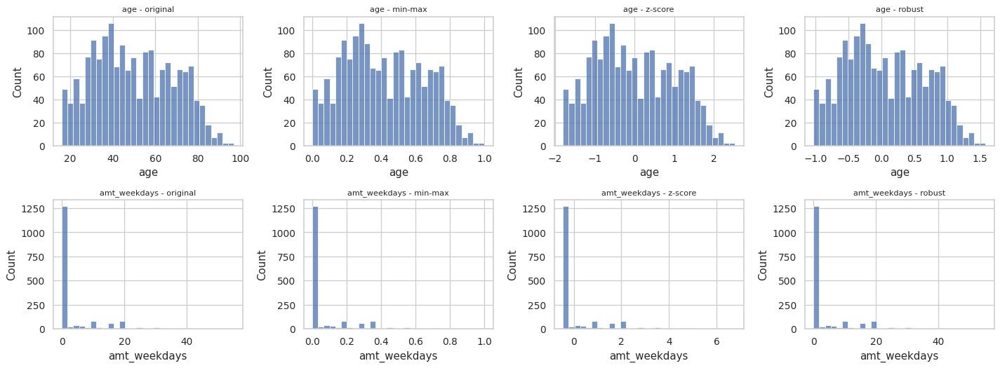

In [40]:
# Module 2.8 | Transformation - Min-Max, Z-score and Robust scaling of age and weekday consumption
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
scale_cols = ['age', 'amt_weekdays']
scaled = {'original': clean[scale_cols]}
for name, sc in [('min-max', MinMaxScaler()), ('z-score', StandardScaler()), ('robust', RobustScaler())]:
    scaled[name] = pd.DataFrame(sc.fit_transform(clean[scale_cols]), columns=scale_cols)
display(pd.concat({k: v.describe().loc[['mean', 'std', 'min', 'max']] for k, v in scaled.items()}, axis=1).round(3))
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, (name, frame) in enumerate(scaled.items()):
    for i, cn in enumerate(scale_cols):
        sns.histplot(frame[cn], ax=axes[i, j], bins=30)
        axes[i, j].set_title(f'{cn} - {name}', fontsize=9)
plt.tight_layout()
plt.show()

,skew,kurt
original,1.116,1.878
sqrt,-0.248,0.449
log1p,-1.133,1.515
box-cox (+1),-0.021,0.035
yeo-johnson,-0.021,0.035


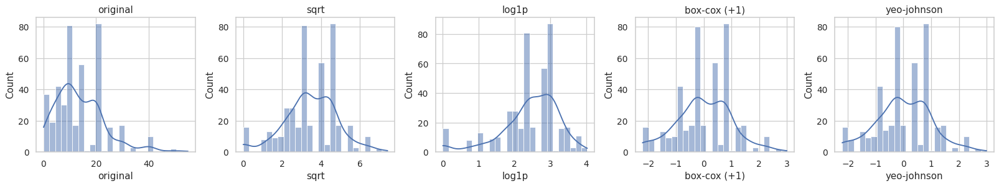

In [41]:
# Module 2.8 | Transformation - reduce right skew of smokers' consumption with log, square-root, Box-Cox and Yeo-Johnson transforms
from sklearn.preprocessing import PowerTransformer
amt = clean.loc[clean['smoke'] == 'Yes', 'amt_weekdays']
trans = pd.DataFrame({
    'original': amt,
    'sqrt': np.sqrt(amt),
    'log1p': np.log1p(amt),
    'box-cox (+1)': PowerTransformer(method='box-cox').fit_transform((amt + 1).to_frame()).ravel(),
    'yeo-johnson': PowerTransformer(method='yeo-johnson').fit_transform(amt.to_frame()).ravel()})
display(trans.agg(['skew', 'kurt']).T.round(3))
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, cn in zip(axes, trans.columns):
    sns.histplot(trans[cn], bins=25, kde=True, ax=ax)
    ax.set_title(cn)
plt.tight_layout()
plt.show()

# Module 3: Correlation Analysis and Time Series Analysis

## 3.1 Univariate analysis

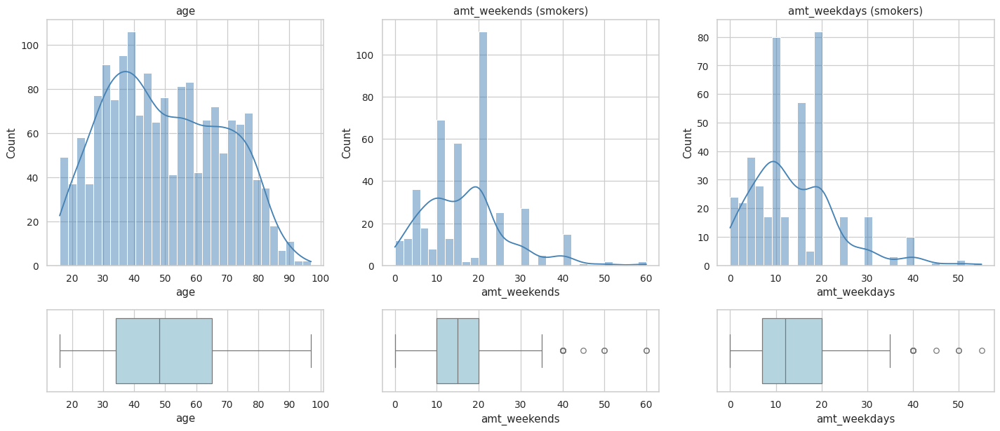

In [42]:
# Module 3.1 | Univariate analysis (numerical) - histogram with KDE and boxplot for age and smokers' weekend and weekday consumption
smokers = clean[clean['smoke'] == 'Yes']
uni = {'age': clean['age'], 'amt_weekends (smokers)': smokers['amt_weekends'], 'amt_weekdays (smokers)': smokers['amt_weekdays']}
fig, axes = plt.subplots(2, 3, figsize=(16, 7), gridspec_kw={'height_ratios': [3, 1]})
for j, (name, s) in enumerate(uni.items()):
    sns.histplot(s, bins=30, kde=True, ax=axes[0, j], color='steelblue')
    axes[0, j].set_title(name)
    sns.boxplot(x=s, ax=axes[1, j], color='lightblue')
plt.tight_layout()
plt.show()

In [43]:
# Module 3.1 | Univariate analysis (numerical) - central tendency, spread, shape and normality test for each variable
uni_stats = pd.DataFrame({
    n: {'n': s.count(), 'mean': s.mean(), 'median': s.median(), 'mode': s.mode()[0], 'std': s.std(), 'min': s.min(),
        'max': s.max(), 'skew': s.skew(), 'kurtosis': s.kurt(), 'shapiro p': stats.shapiro(s)[1]}
    for n, s in uni.items()}).T
uni_stats.round(4)

,n,mean,median,mode,std,min,max,skew,kurtosis,shapiro p
age,1670.0,49.7072,48.0,40.0,18.6873,16.0,97.0,0.1758,-0.9937,0.0
amt_weekends (smokers),421.0,16.4109,15.0,20.0,9.8930,0.0,60.0,0.9915,1.7680,0.0
amt_weekdays (smokers),421.0,13.7506,12.0,20.0,9.3883,0.0,55.0,1.1164,1.8782,0.0


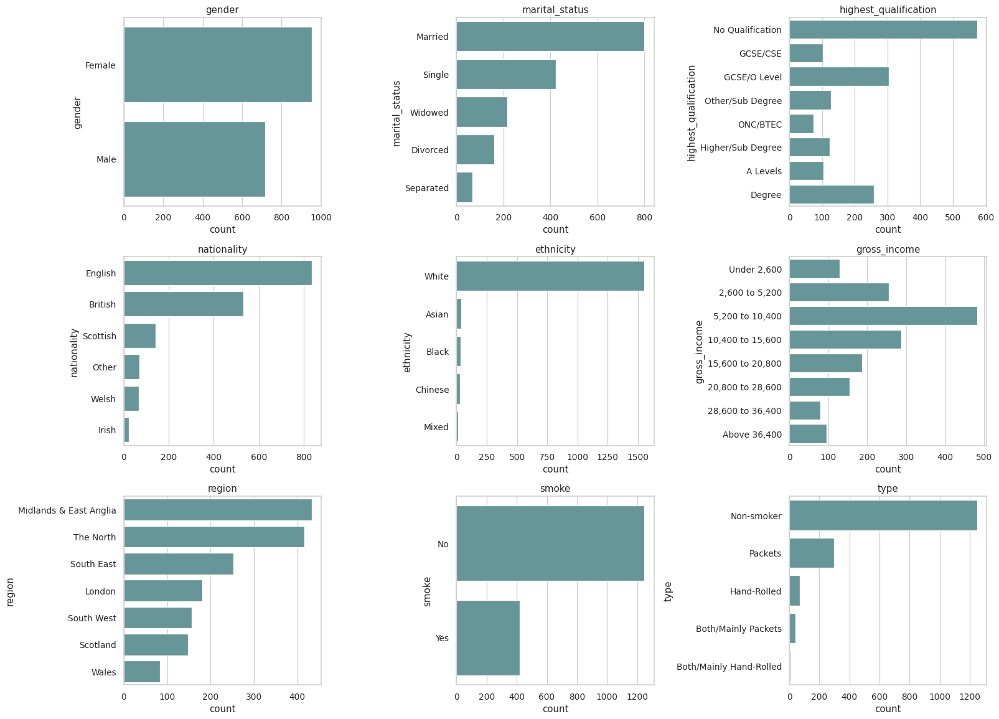

In [44]:
# Module 3.1 | Univariate analysis (categorical) - frequency bar charts of all nominal and ordinal variables
cat_plot_cols = ['gender', 'marital_status', 'highest_qualification', 'nationality', 'ethnicity', 'gross_income', 'region', 'smoke', 'type']
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, col_name in zip(axes.ravel(), cat_plot_cols):
    vc = clean[col_name].value_counts(sort=col_name not in ['gross_income', 'highest_qualification'])
    if col_name in ['gross_income', 'highest_qualification']:
        vc = vc.sort_index()
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color='cadetblue')
    ax.set_title(col_name)
    ax.set_xlabel('count')
plt.tight_layout()
plt.show()

In [45]:
# Module 3.1 | Univariate analysis (categorical) - proportions table and mode/entropy for each categorical variable
rows = []
for col_name in cat_plot_cols:
    p = clean[col_name].value_counts(normalize=True)
    rows.append((col_name, p.size, p.index[0], round(p.iloc[0], 3), round(stats.entropy(p, base=2), 3), round(stats.entropy(p, base=2) / np.log2(p.size), 3)))
pd.DataFrame(rows, columns=['variable', 'categories', 'mode', 'mode share', 'entropy (bits)', 'normalised entropy']).set_index('variable')

,categories,mode,mode share,entropy (bits),normalised entropy
variable,,,,,
gender,2,Female,0.571,0.986,0.986
marital_status,5,Married,0.480,1.906,0.821
highest_qualification,8,No Qualification,0.344,2.652,0.884
nationality,6,English,0.501,1.789,0.692
ethnicity,5,White,0.931,0.496,0.214
gross_income,8,"5,200 to 10,400",0.289,2.771,0.924
region,7,Midlands & East Anglia,0.259,2.609,0.929
smoke,2,No,0.748,0.815,0.815
type,5,Non-smoker,0.748,1.130,0.487


## 3.2 Bivariate analysis

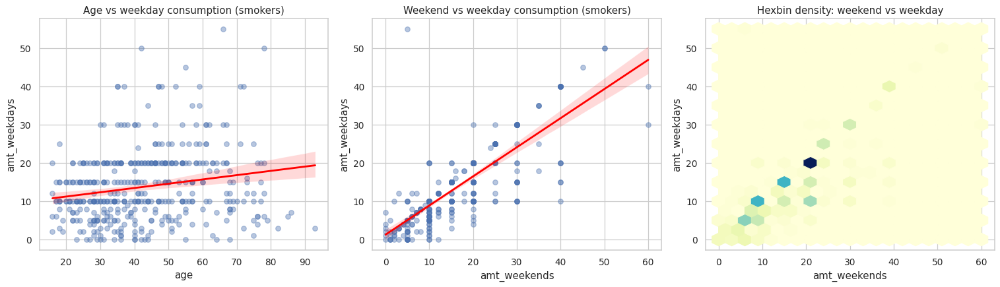

In [46]:
# Module 3.2 | Bivariate analysis (numerical vs numerical) - scatter plots with regression lines and hexbin density
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.regplot(data=smokers, x='age', y='amt_weekdays', ax=axes[0], scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
axes[0].set_title('Age vs weekday consumption (smokers)')
sns.regplot(data=smokers, x='amt_weekends', y='amt_weekdays', ax=axes[1], scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
axes[1].set_title('Weekend vs weekday consumption (smokers)')
axes[2].hexbin(smokers['amt_weekends'], smokers['amt_weekdays'], gridsize=20, cmap='YlGnBu')
axes[2].set_title('Hexbin density: weekend vs weekday')
axes[2].set_xlabel('amt_weekends')
axes[2].set_ylabel('amt_weekdays')
plt.tight_layout()
plt.show()

In [47]:
# Module 3.2 | Bivariate analysis (numerical vs numerical) - Pearson, Spearman and Kendall coefficients with p-values
pairs = [('age', 'amt_weekdays'), ('age', 'amt_weekends'), ('amt_weekends', 'amt_weekdays'), ('income_level', 'amt_weekdays'), ('qual_level', 'amt_weekdays')]
rows = []
for a, b in pairs:
    pr, pp = stats.pearsonr(smokers[a], smokers[b])
    sr, sp = stats.spearmanr(smokers[a], smokers[b])
    kr, kp = stats.kendalltau(smokers[a], smokers[b])
    rows.append((f'{a} ~ {b}', pr, pp, sr, sp, kr, kp))
pd.DataFrame(rows, columns=['pair (smokers)', 'Pearson r', 'p', 'Spearman rho', 'p ', 'Kendall tau', 'p  ']).set_index('pair (smokers)').round(4)

,Pearson r,p,Spearman rho,p,Kendall tau,p
pair (smokers),,,,,,
age ~ amt_weekdays,0.1928,0.0001,0.2043,0.0000,0.1436,0.0000
age ~ amt_weekends,0.0586,0.2299,0.1051,0.0311,0.0751,0.0311
amt_weekends ~ amt_weekdays,0.8021,0.0000,0.8223,0.0000,0.7126,0.0000
income_level ~ amt_weekdays,0.0396,0.4172,0.0407,0.4048,0.0317,0.3916
qual_level ~ amt_weekdays,-0.0782,0.1091,-0.1429,0.0033,-0.1099,0.0031


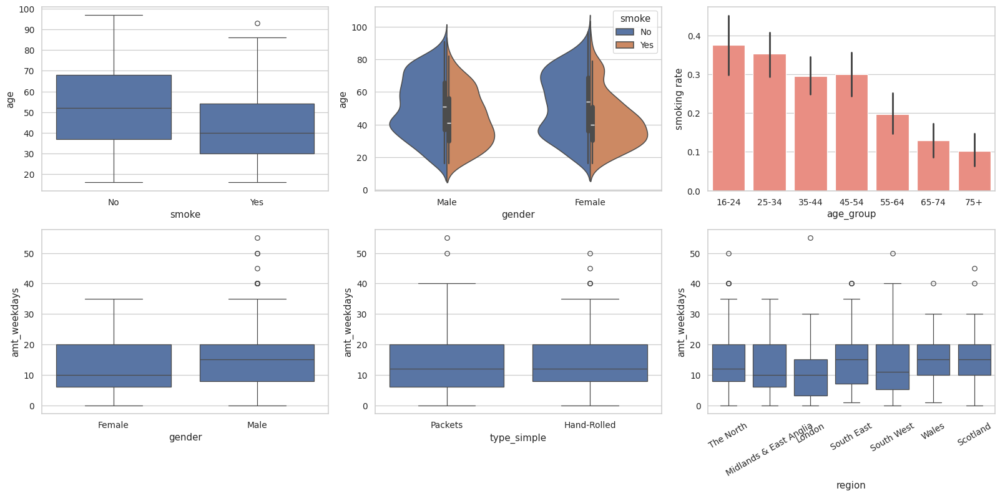

In [48]:
# Module 3.2 | Bivariate analysis (numerical vs categorical) - distributions of age and consumption across groups
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
sns.boxplot(data=clean, x='smoke', y='age', ax=axes[0, 0])
sns.violinplot(data=clean, x='gender', y='age', hue='smoke', split=True, ax=axes[0, 1])
sns.barplot(data=clean, x='age_group', y='smoke_flag', ax=axes[0, 2], color='salmon')
axes[0, 2].set_ylabel('smoking rate')
sns.boxplot(data=smokers, x='gender', y='amt_weekdays', ax=axes[1, 0])
sns.boxplot(data=smokers, x='type_simple', y='amt_weekdays', ax=axes[1, 1])
sns.boxplot(data=smokers, x='region', y='amt_weekdays', ax=axes[1, 2])
axes[1, 2].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [49]:
# Module 3.2 | Bivariate analysis (numerical vs categorical) - t-test, Mann-Whitney, ANOVA, Kruskal-Wallis and eta-squared
def eta_squared(values, groups):
    grand = values.mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for _, g in values.groupby(groups))
    return ssb / ((values - grand) ** 2).sum()

rows = []
a, b = [g['age'].values for _, g in clean.groupby('smoke')]
rows.append(('age by smoke', 'Welch t-test', stats.ttest_ind(a, b, equal_var=False)[1], 'Mann-Whitney', stats.mannwhitneyu(a, b)[1], eta_squared(clean['age'], clean['smoke'])))
a, b = [g['amt_weekdays'].values for _, g in smokers.groupby('gender')]
rows.append(('weekday amt by gender', 'Welch t-test', stats.ttest_ind(a, b, equal_var=False)[1], 'Mann-Whitney', stats.mannwhitneyu(a, b)[1], eta_squared(smokers['amt_weekdays'], smokers['gender'])))
for grp in ['region', 'type_simple', 'marital_status', 'highest_qualification']:
    samples = [g['amt_weekdays'].values for _, g in smokers.groupby(grp, observed=True)]
    rows.append((f'weekday amt by {grp}', 'ANOVA', stats.f_oneway(*samples)[1], 'Kruskal-Wallis', stats.kruskal(*samples)[1], eta_squared(smokers['amt_weekdays'], smokers[grp])))
pd.DataFrame(rows, columns=['comparison', 'parametric test', 'p (parametric)', 'non-parametric test', 'p (non-parametric)', 'eta-squared']).set_index('comparison').round(4)

,parametric test,p (parametric),non-parametric test,p (non-parametric),eta-squared
comparison,,,,,
age by smoke,Welch t-test,0.0000,Mann-Whitney,0.0000,0.0472
weekday amt by gender,Welch t-test,0.0001,Mann-Whitney,0.0018,0.0421
weekday amt by region,ANOVA,0.0850,Kruskal-Wallis,0.0324,0.0264
weekday amt by type_simple,ANOVA,0.0618,Kruskal-Wallis,0.1812,0.0083
weekday amt by marital_status,ANOVA,0.1331,Kruskal-Wallis,0.1720,0.0168
weekday amt by highest_qualification,ANOVA,0.0990,Kruskal-Wallis,0.0133,0.0286


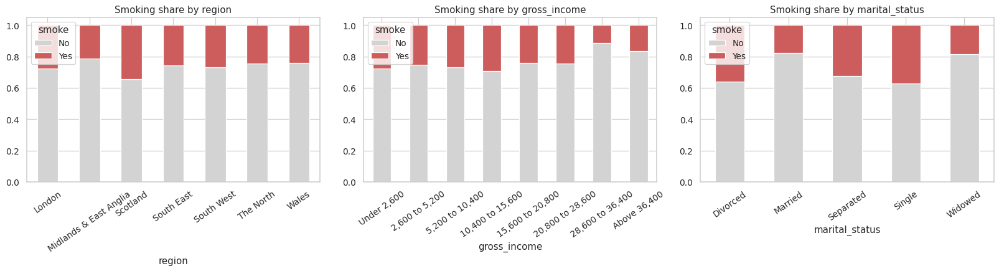

,chi2,dof,p-value,significant
variable vs smoke,,,,
gender,0.4282,1,0.5129,False
marital_status,72.6295,4,0.0000,True
highest_qualification,39.9795,7,0.0000,True
nationality_group,7.2555,2,0.0266,True
ethnicity,2.2532,4,0.6893,False
gross_income,15.4082,7,0.0311,True
region,11.3711,6,0.0776,False
age_group,79.4075,6,0.0000,True


In [50]:
# Module 3.2 | Bivariate analysis (categorical vs categorical) - stacked bars of smoking status and chi-square tests against every categorical variable
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col_name in zip(axes, ['region', 'gross_income', 'marital_status']):
    pd.crosstab(clean[col_name], clean['smoke'], normalize='index').plot(kind='bar', stacked=True, ax=ax, rot=35, color=['lightgray', 'indianred'])
    ax.set_title(f'Smoking share by {col_name}')
plt.tight_layout()
plt.show()
rows = []
for col_name in ['gender', 'marital_status', 'highest_qualification', 'nationality_group', 'ethnicity', 'gross_income', 'region', 'age_group']:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(clean[col_name], clean['smoke']))
    rows.append((col_name, chi2, dof, p, p < 0.05))
pd.DataFrame(rows, columns=['variable vs smoke', 'chi2', 'dof', 'p-value', 'significant']).set_index('variable vs smoke').round(4)

## 3.3 Correlation analysis

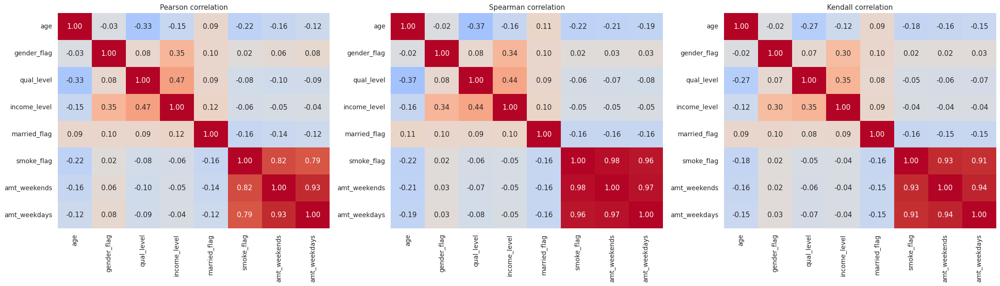

In [51]:
# Module 3.3 | Correlation analysis - Pearson, Spearman and Kendall correlation matrices of all numeric variables as heatmaps
num_cols = ['age', 'gender_flag', 'qual_level', 'income_level', 'married_flag', 'smoke_flag', 'amt_weekends', 'amt_weekdays']
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, method in zip(axes, ['pearson', 'spearman', 'kendall']):
    sns.heatmap(clean[num_cols].corr(method=method), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f'{method.title()} correlation')
plt.tight_layout()
plt.show()

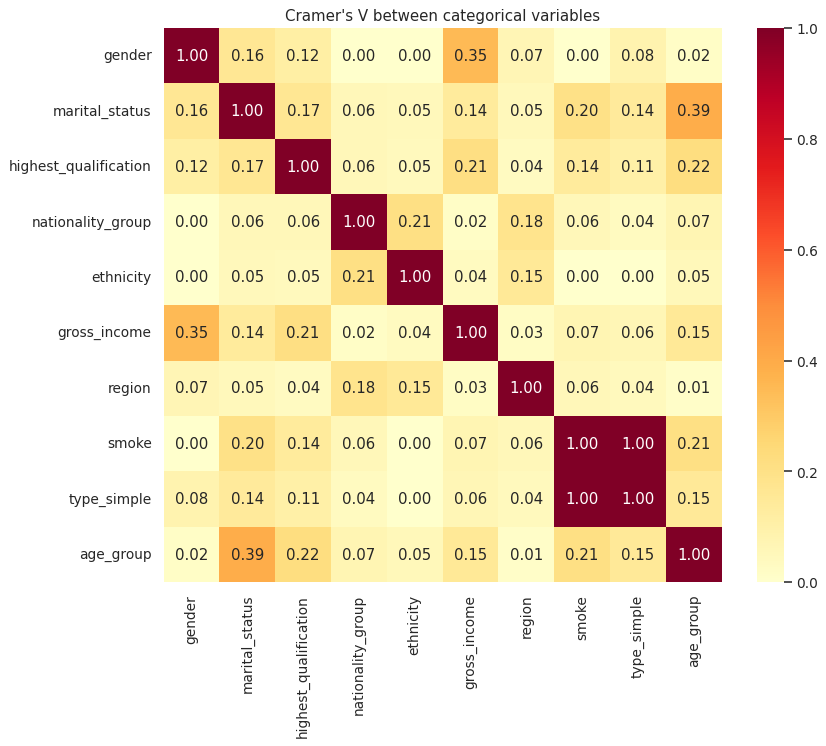

In [52]:
# Module 3.3 | Correlation analysis - Cramer's V association matrix between all categorical variables
def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    phi2 = chi2 / n
    r, k = tab.shape
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / min(kc - 1, rc - 1))

cv_cols = ['gender', 'marital_status', 'highest_qualification', 'nationality_group', 'ethnicity', 'gross_income', 'region', 'smoke', 'type_simple', 'age_group']
cv = pd.DataFrame([[cramers_v(clean[a], clean[b]) for b in cv_cols] for a in cv_cols], index=cv_cols, columns=cv_cols)
plt.figure(figsize=(10, 8))
sns.heatmap(cv, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1)
plt.title("Cramer's V between categorical variables")
plt.show()

In [53]:
# Module 3.3 | Correlation analysis - point-biserial correlation of smoking with numeric variables and top correlated pairs
pb = pd.DataFrame([(v, *stats.pointbiserialr(clean['smoke_flag'], clean[v])) for v in ['age', 'qual_level', 'income_level', 'gender_flag', 'married_flag']],
                  columns=['variable', 'point-biserial r', 'p-value']).set_index('variable')
display(pb.round(4))
corr_pairs = clean[num_cols].corr().abs().where(np.triu(np.ones((len(num_cols),) * 2), 1).astype(bool)).stack().sort_values(ascending=False)
corr_pairs.head(8).to_frame('|Pearson r|').round(3)

,point-biserial r,p-value
variable,,
age,-0.2173,0.0000
qual_level,-0.0822,0.0008
income_level,-0.0644,0.0084
gender_flag,0.0174,0.4772
married_flag,-0.1627,0.0000


|Pearson r|
amt_weekends amt_weekdays        0.928
smoke_flag   amt_weekends        0.821
             amt_weekdays        0.785
qual_level   income_level        0.465
gender_flag  income_level        0.351
age          qual_level          0.329
             smoke_flag          0.217
             amt_weekends        0.164

## 3.4 Multivariate analysis

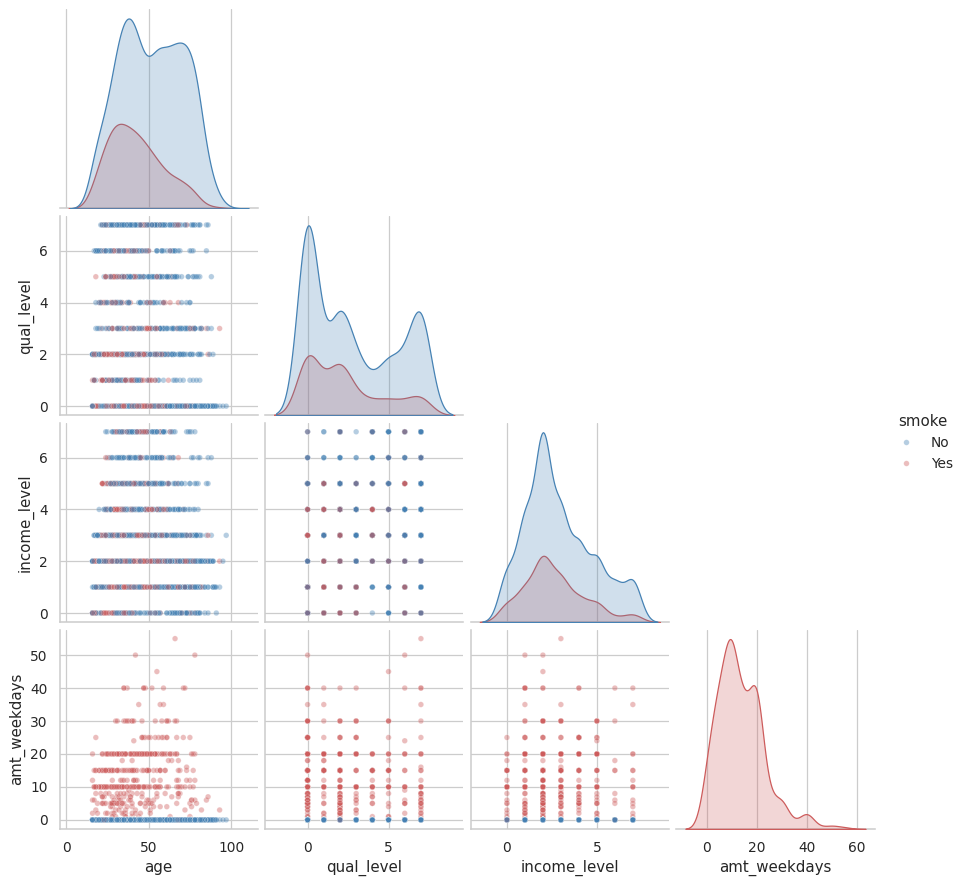

In [54]:
# Module 3.4 | Multivariate analysis - pair plot of age, qualification, income and weekday consumption coloured by smoking status
sns.pairplot(clean[['age', 'qual_level', 'income_level', 'amt_weekdays', 'smoke']], hue='smoke', corner=True, plot_kws={'alpha': 0.4, 's': 20},
             palette={'No': 'steelblue', 'Yes': 'indianred'})
plt.show()

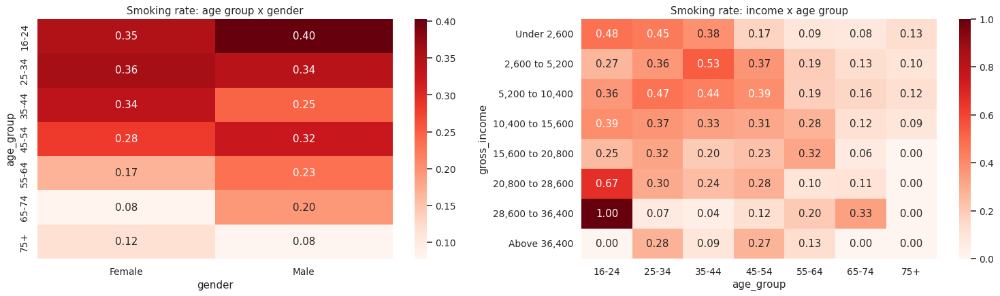

In [55]:
# Module 3.4 | Multivariate analysis - smoking rate across three variables at once (age group, gender, income) as heatmaps
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.heatmap(clean.pivot_table(index='age_group', columns='gender', values='smoke_flag', aggfunc='mean', observed=True), annot=True, fmt='.2f', cmap='Reds', ax=axes[0])
axes[0].set_title('Smoking rate: age group x gender')
sns.heatmap(clean.pivot_table(index='gross_income', columns='age_group', values='smoke_flag', aggfunc='mean', observed=True), annot=True, fmt='.2f', cmap='Reds', ax=axes[1])
axes[1].set_title('Smoking rate: income x age group')
plt.tight_layout()
plt.show()

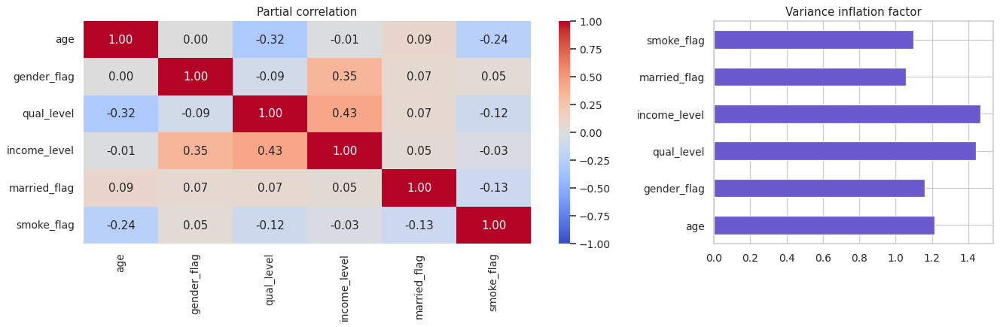

In [56]:
# Module 3.4 | Multivariate analysis - partial correlation matrix (controlling for all other variables) and variance inflation factors
from statsmodels.stats.outliers_influence import variance_inflation_factor
sub = clean[['age', 'gender_flag', 'qual_level', 'income_level', 'married_flag', 'smoke_flag']]
prec = np.linalg.inv(sub.corr().values)
partial_arr = -prec / np.sqrt(np.outer(np.diag(prec), np.diag(prec)))
np.fill_diagonal(partial_arr, 1)
partial = pd.DataFrame(partial_arr, index=sub.columns, columns=sub.columns)
vif = pd.Series([variance_inflation_factor(sub.assign(const=1).values, i) for i in range(sub.shape[1])], index=sub.columns, name='VIF')
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2, 1]})
sns.heatmap(partial, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title('Partial correlation')
vif.plot(kind='barh', ax=ax[1], color='slateblue', title='Variance inflation factor')
plt.tight_layout()
plt.show()

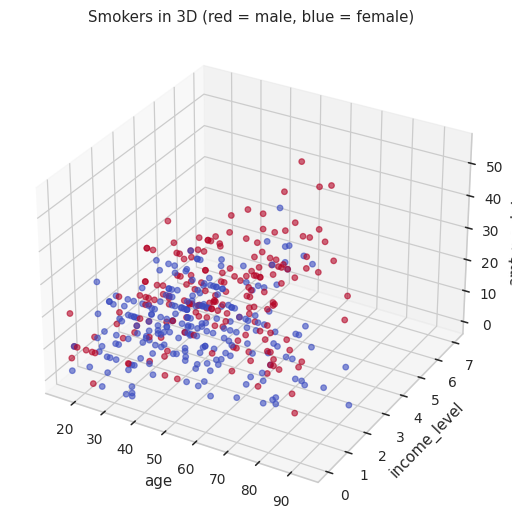

In [57]:
# Module 3.4 | Multivariate analysis - three-dimensional scatter of age, income level and weekday consumption coloured by gender
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(smokers['age'], smokers['income_level'], smokers['amt_weekdays'], c=smokers['gender_flag'], cmap='coolwarm', alpha=0.6)
ax.set_xlabel('age')
ax.set_ylabel('income_level')
ax.set_zlabel('amt_weekdays')
ax.set_title('Smokers in 3D (red = male, blue = female)')
plt.show()

## 3.5 Time series analysis
The dataset has **no date column**. To demonstrate every time series technique, respondents are assumed to be recorded in row order and a synthetic daily `DatetimeIndex` starting on 2015-01-01 is attached. Results on this index illustrate the methods; they are not real calendar findings.

In [58]:
# Module 3.5 | TSA fundamentals - attach a synthetic daily DatetimeIndex to the records in row order and set it as the index
ts_df = clean.sort_values('rownames').reset_index(drop=True).copy()
ts_df.index = pd.date_range(start='2015-01-01', periods=len(ts_df), freq='D', name='date')
print('Index type:', type(ts_df.index).__name__, '| frequency:', ts_df.index.freq, '| span:', ts_df.index.min().date(), 'to', ts_df.index.max().date())
ts_df[['age', 'smoke', 'amt_weekdays', 'amt_weekends']].head()

Index type: DatetimeIndex | frequency: <Day> | span: 2015-01-01 to 2019-07-28


,age,smoke,amt_weekdays,amt_weekends
date,,,,
2015-01-01,38,No,0.0,0.0
2015-01-02,42,Yes,12.0,12.0
2015-01-03,40,No,0.0,0.0
2015-01-04,40,No,0.0,0.0
2015-01-05,39,No,0.0,0.0


In [59]:
# Module 3.5 | Time based indexing - select by year, month range, exact date, slice and boolean date conditions; add calendar features
ts_df['year'] = ts_df.index.year
ts_df['month'] = ts_df.index.month
ts_df['quarter'] = ts_df.index.quarter
ts_df['dayofweek'] = ts_df.index.day_name()
ts_df['is_weekend'] = ts_df.index.dayofweek >= 5
print('Records in 2016:', len(ts_df.loc['2016']))
print('Records Mar-May 2017:', len(ts_df.loc['2017-03':'2017-05']))
print('Record on 2015-06-15:', ts_df.loc['2015-06-15', ['age', 'smoke']].to_dict())
print('First week:', ts_df.loc['2015-01-01':'2015-01-07', 'age'].tolist())
print('Records after 2018-06-01:', len(ts_df[ts_df.index > '2018-06-01']))
ts_df[['year', 'month', 'quarter', 'dayofweek', 'is_weekend']].head()

Records in 2016: 366
Records Mar-May 2017: 92
Record on 2015-06-15: {'age': 30, 'smoke': 'No'}
First week: [38, 42, 40, 40, 39, 37, 53]
Records after 2018-06-01: 422


,year,month,quarter,dayofweek,is_weekend
date,,,,,
2015-01-01,2015,1,1,Thursday,False
2015-01-02,2015,1,1,Friday,False
2015-01-03,2015,1,1,Saturday,True
2015-01-04,2015,1,1,Sunday,True
2015-01-05,2015,1,1,Monday,False


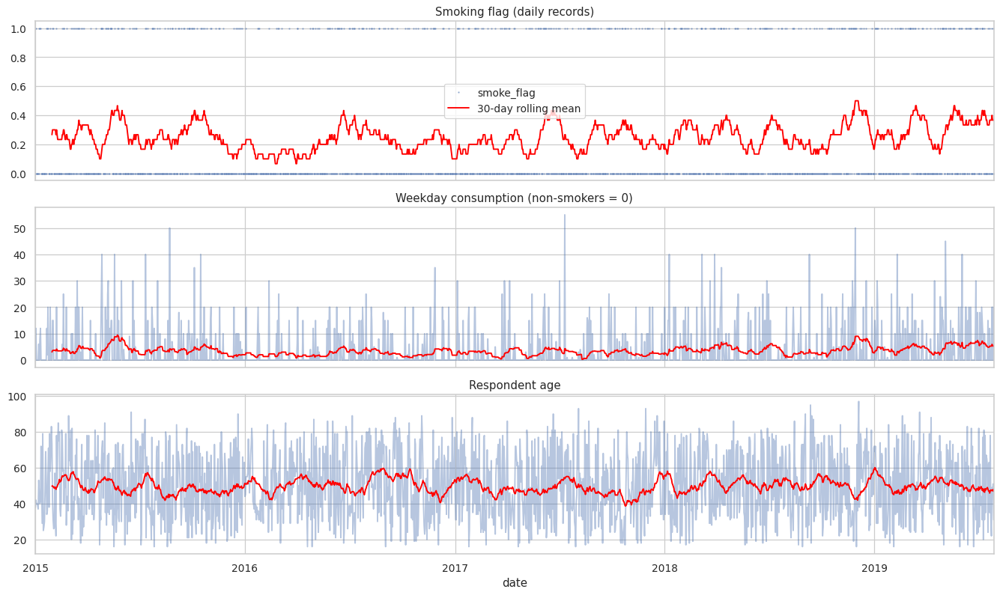

In [60]:
# Module 3.5 | Visualizing time series - daily series of smoking flag and weekday consumption with a 30-day rolling mean
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
ts_df['smoke_flag'].plot(ax=axes[0], style='.', markersize=2, alpha=0.4, title='Smoking flag (daily records)')
ts_df['smoke_flag'].rolling(30).mean().plot(ax=axes[0], color='red', label='30-day rolling mean')
axes[0].legend()
ts_df['amt_weekdays'].plot(ax=axes[1], alpha=0.4, title='Weekday consumption (non-smokers = 0)')
ts_df['amt_weekdays'].rolling(30).mean().plot(ax=axes[1], color='red')
ts_df['age'].plot(ax=axes[2], alpha=0.4, title='Respondent age')
ts_df['age'].rolling(30).mean().plot(ax=axes[2], color='red')
plt.tight_layout()
plt.show()

,mean,count
year,,
2015,0.2630,365
2016,0.1995,366
2017,0.2356,365
2018,0.2685,365
2019,0.3254,209


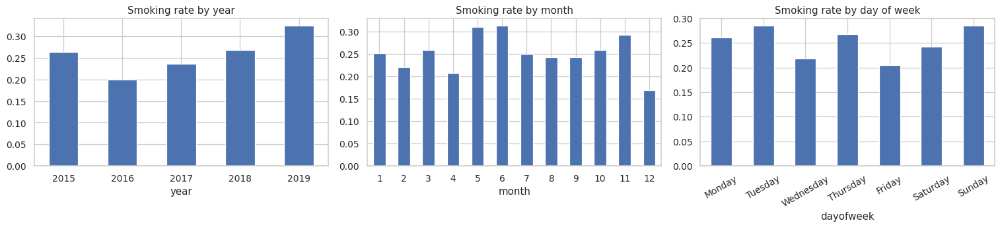

In [61]:
# Module 3.5 | Grouping time series data - aggregate by year, quarter, month and day of week and plot the groups
by_year = ts_df.groupby('year')['smoke_flag'].agg(['mean', 'count'])
by_month = ts_df.groupby('month')['smoke_flag'].mean()
by_dow = ts_df.groupby('dayofweek')['smoke_flag'].mean().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
display(by_year.round(4))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
by_year['mean'].plot(kind='bar', ax=axes[0], title='Smoking rate by year', rot=0)
by_month.plot(kind='bar', ax=axes[1], title='Smoking rate by month', rot=0)
by_dow.plot(kind='bar', ax=axes[2], title='Smoking rate by day of week', rot=30)
plt.tight_layout()
plt.show()

Daily 1670 -> weekly 239 -> monthly 55 -> quarterly 19 | monthly upsampled to daily: 1643


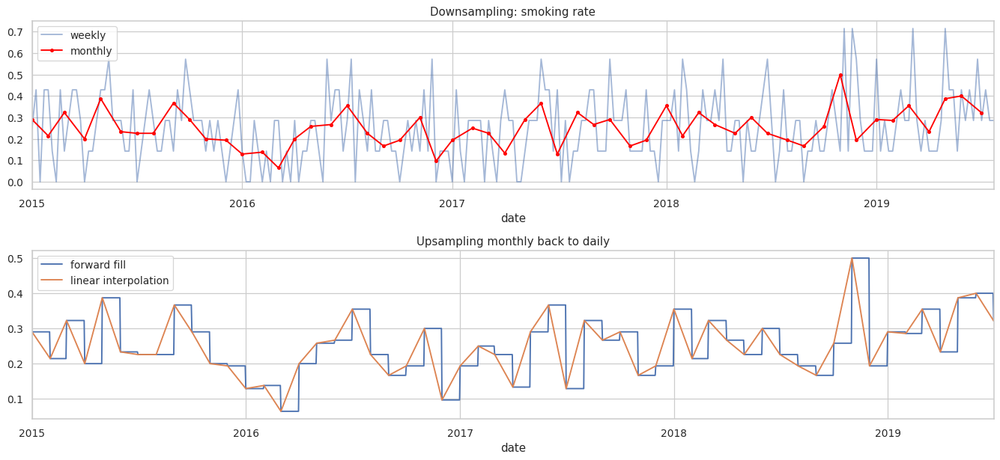

In [62]:
# Module 3.5 | Resampling time series data - downsample to weekly, monthly and quarterly means and upsample with fill methods
weekly = ts_df['smoke_flag'].resample('W').mean()
monthly = ts_df[['smoke_flag', 'amt_weekdays', 'age']].resample('MS').mean()
quarterly = ts_df['smoke_flag'].resample('QS').agg(['mean', 'sum', 'count'])
upsampled_ffill = monthly['smoke_flag'].resample('D').ffill()
upsampled_interp = monthly['smoke_flag'].resample('D').interpolate()
print('Daily', len(ts_df), '-> weekly', len(weekly), '-> monthly', len(monthly), '-> quarterly', len(quarterly), '| monthly upsampled to daily:', len(upsampled_ffill))
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
weekly.plot(ax=axes[0], alpha=0.5, label='weekly')
monthly['smoke_flag'].plot(ax=axes[0], color='red', marker='o', markersize=3, label='monthly')
axes[0].legend()
axes[0].set_title('Downsampling: smoking rate')
upsampled_ffill.plot(ax=axes[1], label='forward fill')
upsampled_interp.plot(ax=axes[1], label='linear interpolation')
axes[1].legend()
axes[1].set_title('Upsampling monthly back to daily')
plt.tight_layout()
plt.show()

,monthly rate,lag 1,diff,pct change,rolling 6,expanding mean,EWM (span 6)
date,,,,,,,
2015-01-01,0.2903,NaN,NaN,NaN,NaN,0.2903,0.2903
2015-02-01,0.2143,0.2903,-0.0760,-0.2619,NaN,0.2523,0.2460
2015-03-01,0.3226,0.2143,0.1083,0.5054,NaN,0.2757,0.2804
2015-04-01,0.2000,0.3226,-0.1226,-0.3800,NaN,0.2568,0.2493
2015-05-01,0.3871,0.2000,0.1871,0.9355,NaN,0.2829,0.2977
2015-06-01,0.2333,0.3871,-0.1538,-0.3972,0.2746,0.2746,0.2765
2015-07-01,0.2258,0.2333,-0.0075,-0.0323,0.2639,0.2676,0.2605
2015-08-01,0.2258,0.2258,0.0000,0.0000,0.2658,0.2624,0.2499


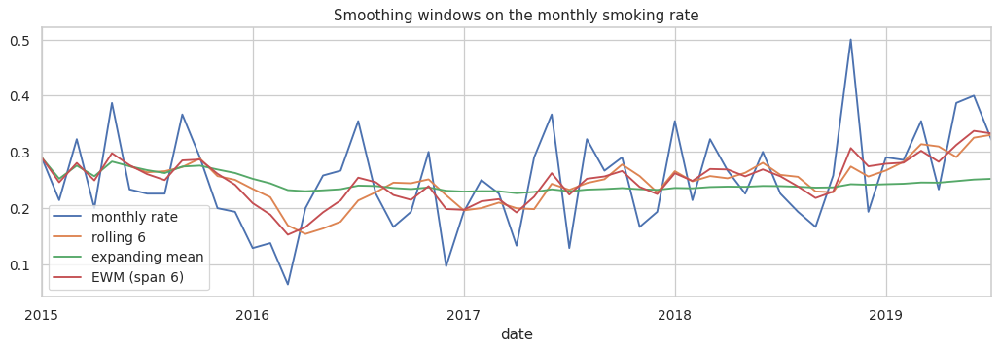

In [63]:
# Module 3.5 | Characteristics of TSA - shifting, differencing, percentage change, rolling, expanding and exponentially weighted windows
m = monthly['smoke_flag']
window_df = pd.DataFrame({'monthly rate': m, 'lag 1': m.shift(1), 'diff': m.diff(), 'pct change': m.pct_change(),
                          'rolling 6': m.rolling(6).mean(), 'expanding mean': m.expanding().mean(), 'EWM (span 6)': m.ewm(span=6).mean()})
display(window_df.head(8).round(4))
window_df[['monthly rate', 'rolling 6', 'expanding mean', 'EWM (span 6)']].plot(figsize=(14, 4), title='Smoothing windows on the monthly smoking rate')
plt.show()

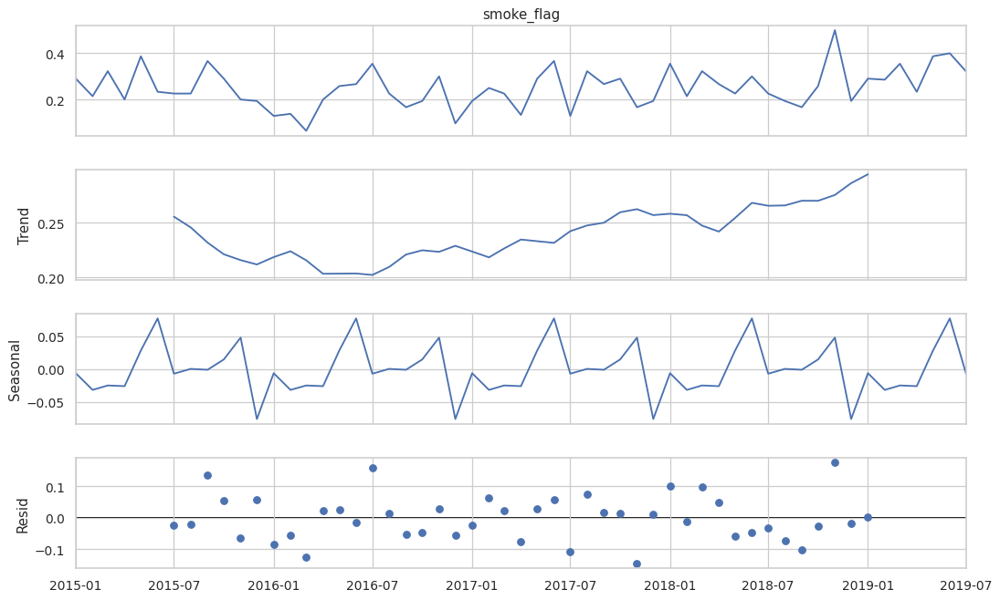

Seasonal strength: 0.2144
Trend strength   : 0.0418


In [64]:
# Module 3.5 | Characteristics of TSA - decompose the monthly series into trend, seasonal and residual (irregular) components
from statsmodels.tsa.seasonal import seasonal_decompose
decomp = seasonal_decompose(monthly['smoke_flag'], model='additive', period=12)
fig = decomp.plot()
fig.set_size_inches(13, 8)
plt.show()
print('Seasonal strength:', round(max(0, 1 - decomp.resid.var() / (decomp.resid + decomp.seasonal).var()), 4))
print('Trend strength   :', round(max(0, 1 - decomp.resid.var() / (decomp.resid + decomp.trend).var()), 4))

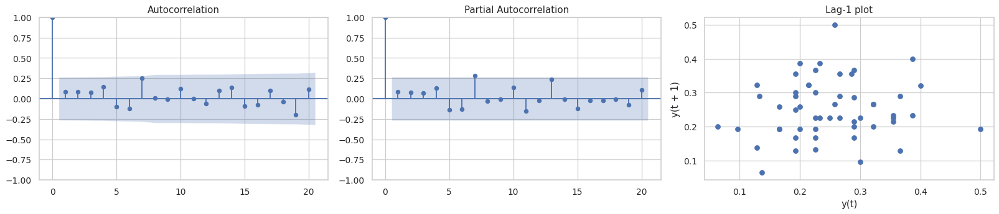

ADF p = 0.0000 -> stationary
KPSS p = 0.0592 -> stationary


In [65]:
# Module 3.5 | Characteristics of TSA - autocorrelation, partial autocorrelation, lag plot and stationarity tests (ADF and KPSS)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from pandas.plotting import lag_plot
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
plot_acf(monthly['smoke_flag'], lags=20, ax=axes[0])
plot_pacf(monthly['smoke_flag'], lags=20, ax=axes[1], method='ywm')
lag_plot(monthly['smoke_flag'], lag=1, ax=axes[2])
axes[2].set_title('Lag-1 plot')
plt.tight_layout()
plt.show()
adf_p = adfuller(monthly['smoke_flag'])[1]
kpss_p = kpss(monthly['smoke_flag'], regression='c', nlags='auto')[1]
print(f'ADF p = {adf_p:.4f} ->', 'stationary' if adf_p < 0.05 else 'non-stationary')
print(f'KPSS p = {kpss_p:.4f} ->', 'stationary' if kpss_p > 0.05 else 'non-stationary')

# Module 4: Data Summarization and Visualization

## 4.1 Statistical summary measures

In [66]:
# Module 4.1 | Statistical summary measures - location, spread, shape, percentiles and confidence interval for numeric variables
def full_summary(s):
    q1, q3 = s.quantile([0.25, 0.75])
    ci = stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))
    return pd.Series({'count': s.count(), 'mean': s.mean(), 'median': s.median(), 'mode': s.mode()[0],
                      'trimmed mean (10%)': stats.trim_mean(s, 0.1), 'std': s.std(), 'variance': s.var(), 'range': s.max() - s.min(),
                      'min': s.min(), 'Q1': q1, 'Q3': q3, 'IQR': q3 - q1, 'p5': s.quantile(0.05), 'p95': s.quantile(0.95), 'max': s.max(),
                      'MAD': stats.median_abs_deviation(s), 'CV %': 100 * s.std() / s.mean(), 'std error': stats.sem(s),
                      'CI95 low': ci[0], 'CI95 high': ci[1], 'skewness': s.skew(), 'kurtosis': s.kurt()})
summary_all = pd.DataFrame({'age': full_summary(clean['age']), 'amt_weekends (smokers)': full_summary(smokers['amt_weekends']),
                            'amt_weekdays (smokers)': full_summary(smokers['amt_weekdays']), 'income_level': full_summary(clean['income_level']),
                            'qual_level': full_summary(clean['qual_level'])})
summary_all.round(3)

,age,amt_weekends (smokers),amt_weekdays (smokers),income_level,qual_level
count,1670.000,421.000,421.000,1670.000,1670.000
mean,49.707,16.411,13.751,2.841,2.666
median,48.000,15.000,12.000,2.000,2.000
mode,40.000,20.000,20.000,2.000,0.000
trimmed mean (10%),49.356,15.549,12.834,2.702,2.457
std,18.687,9.893,9.388,1.845,2.608
variance,349.215,97.871,88.140,3.405,6.801
range,81.000,60.000,55.000,7.000,7.000
min,16.000,0.000,0.000,0.000,0.000
Q1,34.000,10.000,7.000,2.000,0.000


In [67]:
# Module 4.1 | Statistical summary measures - grouped summaries of age and consumption by smoking status and gender
display(clean.groupby('smoke')['age'].describe().round(2))
display(clean.groupby(['gender', 'smoke'])['age'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2))
smokers.groupby('gender')[['amt_weekends', 'amt_weekdays']].agg(['mean', 'median', 'std', 'max']).round(2)

,count,mean,std,min,25%,50%,75%,max
smoke,,,,,,,,
No,1249.0,52.06,18.89,16.0,37.0,52.0,68.0,97.0
Yes,421.0,42.71,16.18,16.0,30.0,40.0,54.0,93.0


count   mean  median    std  min  max
gender smoke                                       
Female No       719  52.78    54.0  19.19   16   97
       Yes      234  42.21    40.0  16.06   16   93
Male   No       530  51.10    51.0  18.45   16   91
       Yes      187  43.35    41.0  16.35   16   82

amt_weekends                     amt_weekdays                    
               mean median    std   max         mean median    std   max
gender                                                                  
Female        15.00   15.0   8.60  60.0        12.03   10.0   7.35  35.0
Male          18.17   20.0  11.08  60.0        15.90   15.0  11.09  55.0

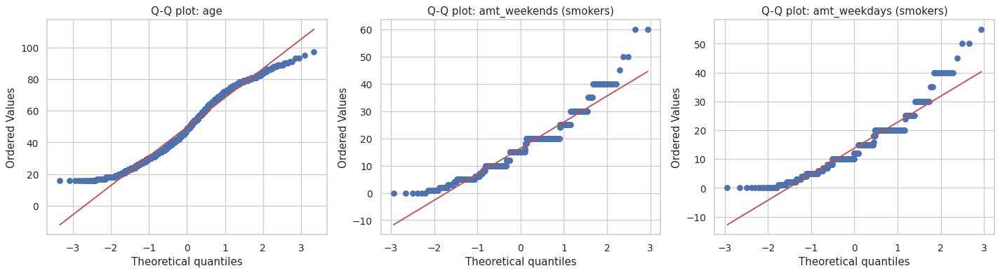

,Shapiro p,D'Agostino p,KS p,Anderson statistic
variable,,,,
age,0.0,0.0,0.0,14.18017
amt_weekends (smokers),0.0,0.0,0.0,8.21433
amt_weekdays (smokers),0.0,0.0,0.0,8.43227


In [68]:
# Module 4.1 | Statistical summary measures - normality assessment with Q-Q plots and Shapiro, D'Agostino and Kolmogorov-Smirnov tests
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
rows = []
for ax, (name, s) in zip(axes, uni.items()):
    stats.probplot(s, dist='norm', plot=ax)
    ax.set_title(f'Q-Q plot: {name}')
    rows.append((name, stats.shapiro(s)[1], stats.normaltest(s)[1], stats.kstest((s - s.mean()) / s.std(), 'norm')[1], stats.anderson(s).statistic))
plt.tight_layout()
plt.show()
pd.DataFrame(rows, columns=['variable', 'Shapiro p', "D'Agostino p", 'KS p', 'Anderson statistic']).set_index('variable').round(5)

## 4.2 Data elaboration

In [69]:
# Module 4.2 | Data elaboration - derive new variables: weekly and average daily cigarettes, weekend share and standardised age
clean['weekly_cigs'] = clean['amt_weekdays'] * 5 + clean['amt_weekends'] * 2
clean['avg_daily_cigs'] = clean['weekly_cigs'] / 7
clean['weekend_share'] = np.where(clean['weekly_cigs'] > 0, clean['amt_weekends'] * 2 / clean['weekly_cigs'].replace(0, np.nan), np.nan)
clean['weekend_minus_weekday'] = clean['amt_weekends'] - clean['amt_weekdays']
clean['age_z'] = (clean['age'] - clean['age'].mean()) / clean['age'].std()
smokers = clean[clean['smoke'] == 'Yes']
smokers[['age', 'amt_weekends', 'amt_weekdays', 'weekly_cigs', 'avg_daily_cigs', 'weekend_share', 'weekend_minus_weekday', 'age_z']].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,421.0,42.715,16.180,16.000,30.000,40.000,54.00,93.000
amt_weekends,421.0,16.411,9.893,0.000,10.000,15.000,20.00,60.000
amt_weekdays,421.0,13.751,9.388,0.000,7.000,12.000,20.00,55.000
weekly_cigs,421.0,101.575,63.913,0.000,55.000,90.000,140.00,350.000
avg_daily_cigs,421.0,14.511,9.130,0.000,7.857,12.857,20.00,50.000
weekend_share,420.0,0.356,0.162,0.000,0.286,0.286,0.40,1.000
weekend_minus_weekday,421.0,2.660,6.085,-50.000,0.000,0.000,5.00,30.000
age_z,421.0,-0.374,0.866,-1.804,-1.055,-0.519,0.23,2.317


In [70]:
# Module 4.2 | Data elaboration - ranking, percentile rank, cumulative sums and sorting of smokers by consumption
ranked = smokers[['age', 'gender', 'region', 'weekly_cigs']].copy()
ranked['rank (desc)'] = ranked['weekly_cigs'].rank(ascending=False, method='min')
ranked['percentile rank'] = ranked['weekly_cigs'].rank(pct=True).round(3)
ranked['cumulative share of consumption'] = ranked.sort_values('weekly_cigs', ascending=False)['weekly_cigs'].cumsum() / ranked['weekly_cigs'].sum()
ranked.sort_values('rank (desc)').head(10)

,age,gender,region,weekly_cigs,rank (desc),percentile rank,cumulative share of consumption
234,78,Male,The North,350.0,1.0,0.999,0.008185
1428,42,Male,South West,350.0,1.0,0.999,0.016369
1161,35,Male,South East,320.0,3.0,0.995,0.023852
1585,55,Male,Scotland,315.0,4.0,0.993,0.031219
922,66,Male,London,285.0,5.0,0.990,0.037883
288,48,Male,The North,280.0,6.0,0.979,0.090265
1501,35,Male,Wales,280.0,6.0,0.979,0.096813
138,37,Male,The North,280.0,6.0,0.979,0.083717
1183,52,Male,South East,280.0,6.0,0.979,0.077170
1104,47,Male,South East,280.0,6.0,0.979,0.057526


In [71]:
# Module 4.2 | Data elaboration - pivot tables, multi-level group aggregation and reshaping between wide and long formats
pt = clean.pivot_table(index='region', columns='gender', values='weekly_cigs', aggfunc=['mean', 'count'], observed=True).round(2)
display(pt)
display(clean.groupby(['region', 'smoke'], observed=True).agg(n=('age', 'size'), mean_age=('age', 'mean'), mean_weekly=('weekly_cigs', 'mean')).round(2).head(14))
long = smokers[['rownames', 'amt_weekdays', 'amt_weekends']].melt(id_vars='rownames', var_name='period', value_name='cigarettes')
display(long.head())
display(long.pivot_table(index='rownames', columns='period', values='cigarettes').head())

mean         count     
gender                 Female   Male Female Male
region                                          
London                  17.50  28.01    107   74
Midlands & East Anglia  18.07  22.35    248  185
Scotland                34.45  42.76     66   82
South East              24.10  32.63    141  111
South West              21.32  37.27     93   64
The North               23.19  29.82    254  162
Wales                   27.27  28.59     44   39

n  mean_age  mean_weekly
region                 smoke                            
London                 No     131     47.54         0.00
                       Yes     50     44.44        78.90
Midlands & East Anglia No     341     53.01         0.00
                       Yes     92     41.78        93.64
Scotland               No      97     52.56         0.00
                       Yes     51     43.84       113.33
South East             No     187     53.28         0.00
                       Yes     65     43.03       108.00
South West             No     115     53.52         0.00
                       Yes     42     42.17       104.00
The North              No     315     51.19         0.00
                       Yes    101     41.88       106.14
Wales                  No      63     53.67         0.00
                       Yes     20     44.15       115.75

,rownames,period,cigarettes
0,2,amt_weekdays,12.0
1,7,amt_weekdays,6.0
2,9,amt_weekdays,8.0
3,10,amt_weekdays,12.0
4,21,amt_weekdays,12.0


period,amt_weekdays,amt_weekends
rownames,,
2,12.0,12.0
7,6.0,6.0
9,8.0,8.0
10,12.0,15.0
21,12.0,6.0


In [72]:
# Module 4.2 | Data elaboration - frequency tables with absolute, relative and cumulative frequencies for age groups and regions
for col_name in ['age_group', 'region']:
    vc = clean[col_name].value_counts().sort_index() if col_name == 'age_group' else clean[col_name].value_counts()
    display(pd.DataFrame({'frequency': vc, 'relative %': (100 * vc / vc.sum()).round(2), 'cumulative %': (100 * vc.cumsum() / vc.sum()).round(2)}))

,frequency,relative %,cumulative %
age_group,,,
16-24,144,8.62,8.62
25-34,280,16.77,25.39
35-44,322,19.28,44.67
45-54,250,14.97,59.64
55-64,238,14.25,73.89
65-74,232,13.89,87.78
75+,204,12.22,100.00


,frequency,relative %,cumulative %
region,,,
Midlands & East Anglia,433,25.93,25.93
The North,416,24.91,50.84
South East,252,15.09,65.93
London,181,10.84,76.77
South West,157,9.40,86.17
Scotland,148,8.86,95.03
Wales,83,4.97,100.00


## 4.3 One-dimensional statistical data analysis

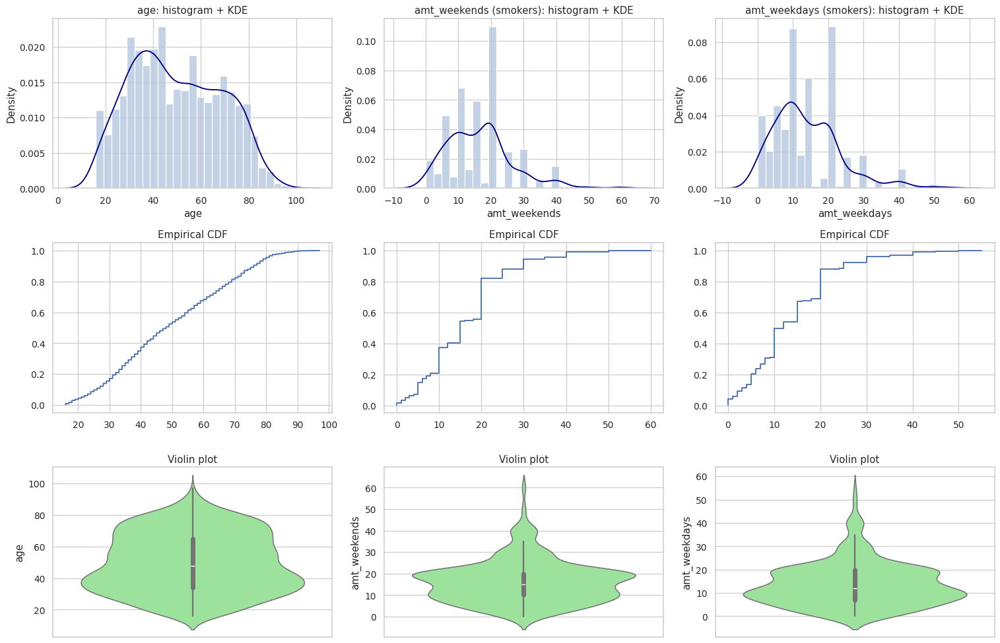

In [73]:
# Module 4.3 | 1-D analysis - histogram, KDE, empirical CDF and violin plot for each numeric variable
fig, axes = plt.subplots(3, 3, figsize=(17, 11))
for j, (name, s) in enumerate(uni.items()):
    sns.histplot(s, bins=25, stat='density', ax=axes[0, j], color='lightsteelblue')
    sns.kdeplot(s, ax=axes[0, j], color='navy')
    axes[0, j].set_title(f'{name}: histogram + KDE')
    xs = np.sort(s)
    axes[1, j].step(xs, np.arange(1, len(xs) + 1) / len(xs))
    axes[1, j].set_title('Empirical CDF')
    sns.violinplot(y=s, ax=axes[2, j], color='lightgreen')
    axes[2, j].set_title('Violin plot')
plt.tight_layout()
plt.show()

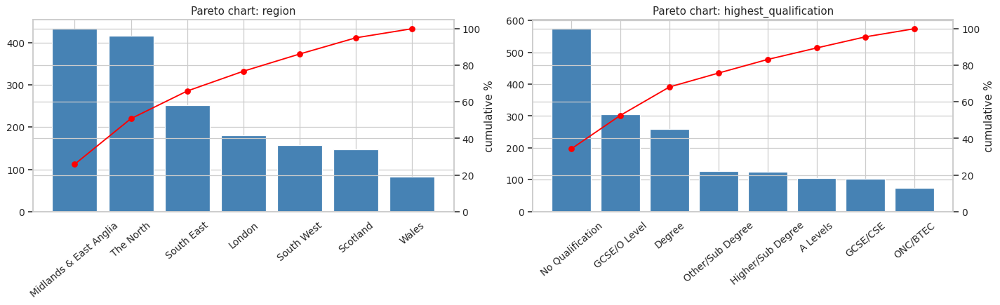

In [74]:
# Module 4.3 | 1-D analysis - Pareto chart (bars plus cumulative line) for region and for qualification
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col_name in zip(axes, ['region', 'highest_qualification']):
    vc = clean[col_name].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color='steelblue')
    ax.tick_params(axis='x', rotation=40)
    ax2 = ax.twinx()
    ax2.plot(vc.index.astype(str), 100 * vc.cumsum() / vc.sum(), color='red', marker='o')
    ax2.set_ylim(0, 105)
    ax2.set_ylabel('cumulative %')
    ax.set_title(f'Pareto chart: {col_name}')
plt.tight_layout()
plt.show()

,log-likelihood,AIC,KS p-value
gamma,-1418.548,2843.095,0.0
lognorm,-1421.537,2849.075,0.0
norm,-1471.040,2946.080,0.0
weibull_min,-inf,inf,0.0


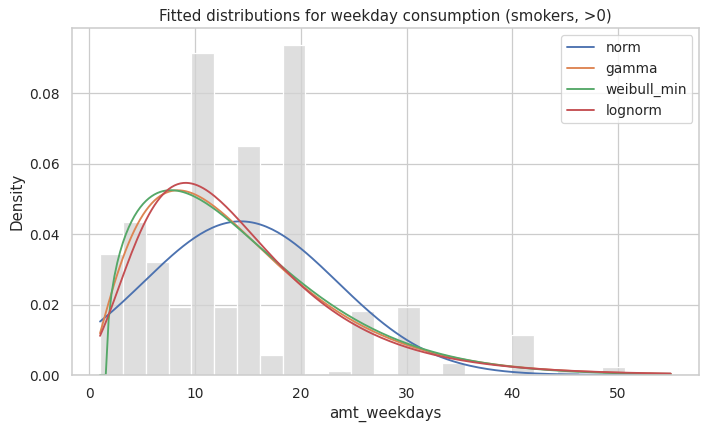

In [75]:
# Module 4.3 | 1-D analysis - distribution fitting of smokers' weekday consumption with maximum likelihood (normal, gamma, Weibull, log-normal)
x = smokers.loc[smokers['amt_weekdays'] > 0, 'amt_weekdays']
fits = {}
for dist in [stats.norm, stats.gamma, stats.weibull_min, stats.lognorm]:
    params = dist.fit(x)
    ll = dist.logpdf(x, *params).sum()
    fits[dist.name] = (params, ll, 2 * len(params) - 2 * ll, stats.kstest(x, dist.name, args=params)[1])
fit_table = pd.DataFrame({k: {'log-likelihood': v[1], 'AIC': v[2], 'KS p-value': v[3]} for k, v in fits.items()}).T.sort_values('AIC')
display(fit_table.round(3))
grid = np.linspace(x.min(), x.max(), 200)
sns.histplot(x, stat='density', bins=25, color='lightgray')
for k, v in fits.items():
    plt.plot(grid, getattr(stats, k).pdf(grid, *v[0]), label=k)
plt.legend()
plt.title('Fitted distributions for weekday consumption (smokers, >0)')
plt.show()

## 4.4 Two-dimensional statistical data analysis

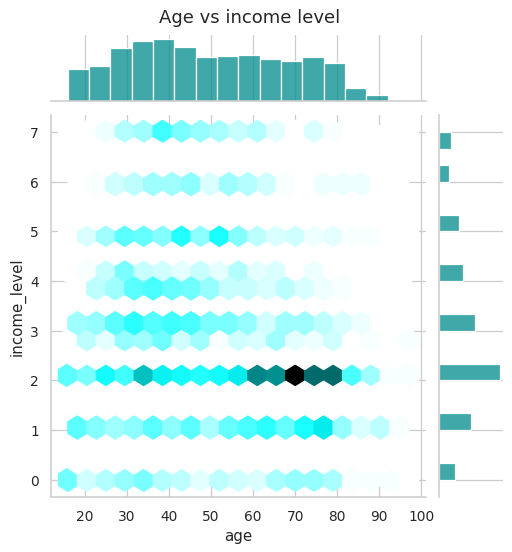

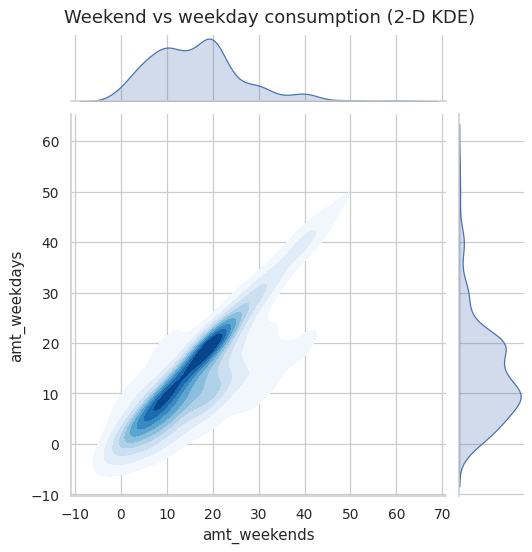

In [76]:
# Module 4.4 | 2-D analysis - joint distribution of age and income level and of weekend vs weekday consumption (joint plots with marginals)
g1 = sns.jointplot(data=clean, x='age', y='income_level', kind='hex', color='darkcyan', height=6)
g1.fig.suptitle('Age vs income level', y=1.02)
g2 = sns.jointplot(data=smokers, x='amt_weekends', y='amt_weekdays', kind='kde', fill=True, cmap='Blues', height=6)
g2.fig.suptitle('Weekend vs weekday consumption (2-D KDE)', y=1.02)
plt.show()

In [77]:
# Module 4.4 | 2-D analysis - covariance, correlation and simple linear fit with R-squared for selected variable pairs
pairs = [('age', 'income_level', clean), ('age', 'amt_weekdays', smokers), ('amt_weekends', 'amt_weekdays', smokers), ('qual_level', 'income_level', clean)]
rows = []
for a, b, frame in pairs:
    lr = stats.linregress(frame[a], frame[b])
    rows.append((f'{a} -> {b}', frame[[a, b]].cov().iloc[0, 1], lr.rvalue, lr.slope, lr.intercept, lr.rvalue ** 2, lr.pvalue))
pd.DataFrame(rows, columns=['pair', 'covariance', 'correlation', 'slope', 'intercept', 'R squared', 'p-value']).set_index('pair').round(4)

,covariance,correlation,slope,intercept,R squared,p-value
pair,,,,,,
age -> income_level,-5.2508,-0.1523,-0.0150,3.5887,0.0232,0.0000
age -> amt_weekdays,29.2835,0.1928,0.1119,8.9724,0.0372,0.0001
amt_weekends -> amt_weekdays,74.4932,0.8021,0.7611,1.2597,0.6433,0.0000
qual_level -> income_level,2.2387,0.4652,0.3292,1.9638,0.2164,0.0000


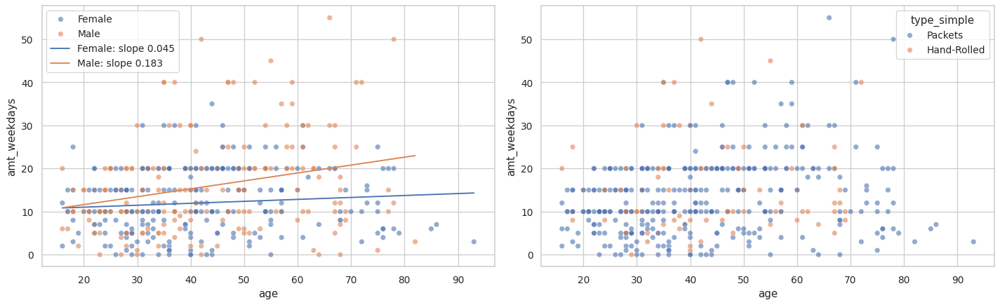

In [78]:
# Module 4.4 | 2-D analysis - group-wise relationship: age vs weekday consumption with a separate fit for each gender and cigarette type
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=smokers, x='age', y='amt_weekdays', hue='gender', alpha=0.6, ax=axes[0])
for gname, grp in smokers.groupby('gender'):
    lr = stats.linregress(grp['age'], grp['amt_weekdays'])
    xs = np.array([grp['age'].min(), grp['age'].max()])
    axes[0].plot(xs, lr.intercept + lr.slope * xs, label=f'{gname}: slope {lr.slope:.3f}')
axes[0].legend()
sns.scatterplot(data=smokers, x='age', y='amt_weekdays', hue='type_simple', alpha=0.6, ax=axes[1])
plt.tight_layout()
plt.show()

## 4.5 Contingency tables

In [79]:
# Module 4.5 | Contingency tables - smoking status by gender with margins and row, column and overall proportions
ct = pd.crosstab(clean['gender'], clean['smoke'], margins=True, margins_name='Total')
display(ct)
display(pd.crosstab(clean['gender'], clean['smoke'], normalize='index').round(3))
display(pd.crosstab(clean['gender'], clean['smoke'], normalize='columns').round(3))
display(pd.crosstab(clean['gender'], clean['smoke'], normalize='all').round(3))

smoke,No,Yes,Total
gender,,,
Female,719,234,953
Male,530,187,717
Total,1249,421,1670


smoke,No,Yes
gender,,
Female,0.754,0.246
Male,0.739,0.261


smoke,No,Yes
gender,,
Female,0.576,0.556
Male,0.424,0.444


smoke,No,Yes
gender,,
Female,0.431,0.140
Male,0.317,0.112


In [80]:
# Module 4.5 | Contingency tables - chi-square test, expected counts, Pearson residuals, G-test, Fisher exact test and effect sizes
tab = pd.crosstab(clean['gender'], clean['smoke'])
chi2, p, dof, expected = stats.chi2_contingency(tab, correction=False)
g_stat, g_p, _, _ = stats.chi2_contingency(tab, correction=False, lambda_='log-likelihood')
odds, fisher_p = stats.fisher_exact(tab)
n = tab.values.sum()
print(f'Chi-square = {chi2:.4f}, dof = {dof}, p = {p:.4f}')
print(f'G-test = {g_stat:.4f}, p = {g_p:.4f}')
print(f'Fisher exact: odds ratio = {odds:.4f}, p = {fisher_p:.4f}')
print(f'phi / Cramers V = {np.sqrt(chi2 / n):.4f}')
display(pd.DataFrame(expected, index=tab.index, columns=tab.columns).round(2).rename_axis('expected counts'))
display(((tab - expected) / np.sqrt(expected)).round(3).rename_axis('Pearson residuals'))

Chi-square = 0.5059, dof = 1, p = 0.4769
G-test = 0.5050, p = 0.4773
Fisher exact: odds ratio = 1.0841, p = 0.4947
phi / Cramers V = 0.0174


smoke,No,Yes
expected counts,,
Female,712.75,240.25
Male,536.25,180.75


smoke,No,Yes
Pearson residuals,,
Female,0.234,-0.403
Male,-0.270,0.465


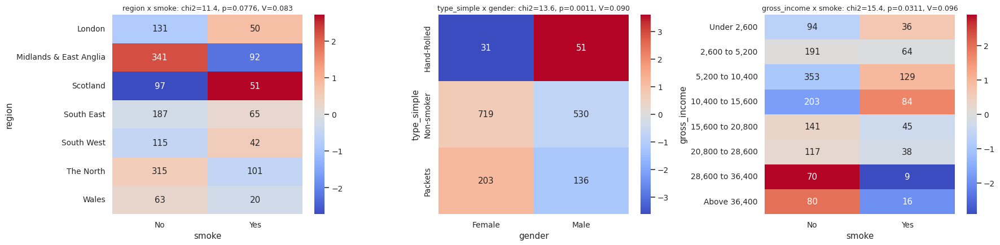

In [81]:
# Module 4.5 | Contingency tables - larger tables (smoke x region, cigarette type x gender, smoke x income): tests and standardised-residual heatmaps
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (r, cc) in zip(axes, [('region', 'smoke'), ('type_simple', 'gender'), ('gross_income', 'smoke')]):
    t = pd.crosstab(clean[r], clean[cc])
    chi2, p, dof, exp = stats.chi2_contingency(t)
    resid = (t - exp) / np.sqrt(exp * (1 - t.sum(axis=1).values[:, None] / t.values.sum()) * (1 - t.sum(axis=0).values[None, :] / t.values.sum()))
    sns.heatmap(resid, annot=t, fmt='d', cmap='coolwarm', center=0, ax=ax, cbar=True)
    ax.set_title(f'{r} x {cc}: chi2={chi2:.1f}, p={p:.4f}, V={np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))):.3f}', fontsize=10)
plt.tight_layout()
plt.show()

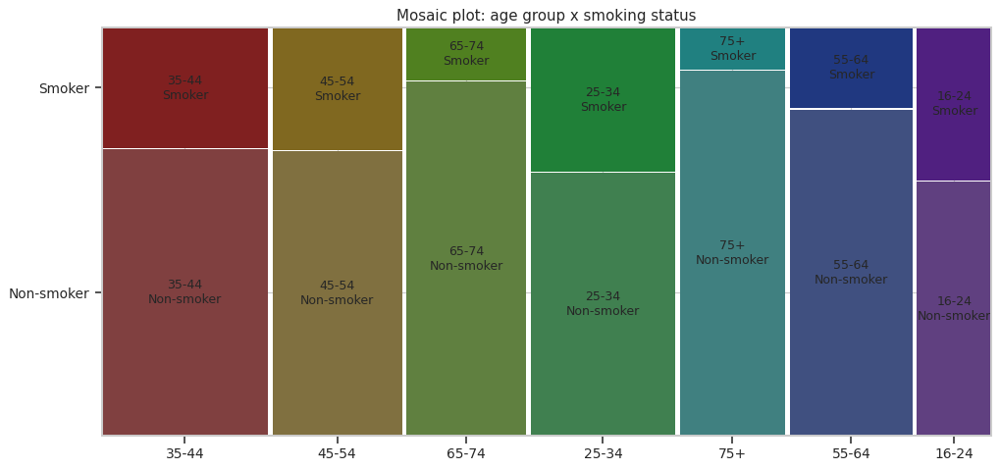

In [82]:
# Module 4.5 | Contingency tables - mosaic plot of smoking status by age group and gender
from statsmodels.graphics.mosaicplot import mosaic
fig, ax = plt.subplots(figsize=(13, 6))
mosaic(clean.assign(smoke_label=clean['smoke'].map({'Yes': 'Smoker', 'No': 'Non-smoker'})), ['age_group', 'smoke_label'], ax=ax, title='Mosaic plot: age group x smoking status')
plt.show()

## 4.6 n-Dimensional statistical data analysis

In [83]:
# Module 4.6 | n-D analysis - three-way and four-way contingency tables and a multi-level pivot of smoking rate
display(pd.crosstab([clean['gender'], clean['age_group']], clean['smoke']).head(14))
display(clean.pivot_table(index=['gender', 'age_group'], columns='marital_status', values='smoke_flag', aggfunc='mean', observed=True).round(2))

smoke              No  Yes
gender age_group          
Female 16-24       50   27
       25-34      108   61
       35-44      114   58
       45-54      102   40
       55-64      109   22
       65-74      124   11
       75+        112   15
Male   16-24       40   27
       25-34       73   38
       35-44      113   37
       45-54       73   35
       55-64       82   25
       65-74       78   19
       75+         71    6

marital_status    Divorced  Married  Separated  Single  Widowed
gender age_group                                               
Female 16-24           NaN     0.29        NaN    0.36      NaN
       25-34          0.56     0.18       0.36    0.49     0.33
       35-44          0.47     0.29       0.46    0.30     0.00
       45-54          0.46     0.20       0.12    0.35     0.50
       55-64          0.30     0.13       0.40    0.20     0.09
       65-74          0.15     0.05       0.00    0.00     0.12
       75+            0.00     0.05       0.00    0.00     0.16
Male   16-24           NaN     0.25       1.00    0.40      NaN
       25-34          0.33     0.23        NaN    0.42      NaN
       35-44          0.36     0.18       0.22    0.42     0.00
       45-54          0.36     0.27       0.20    0.45     0.67
       55-64          0.50     0.20       0.60    0.14     0.17
       65-74          0.00     0.14       0.50    0.12     0.41
       75+            0.20     0.05        NaN    0.00     0.12

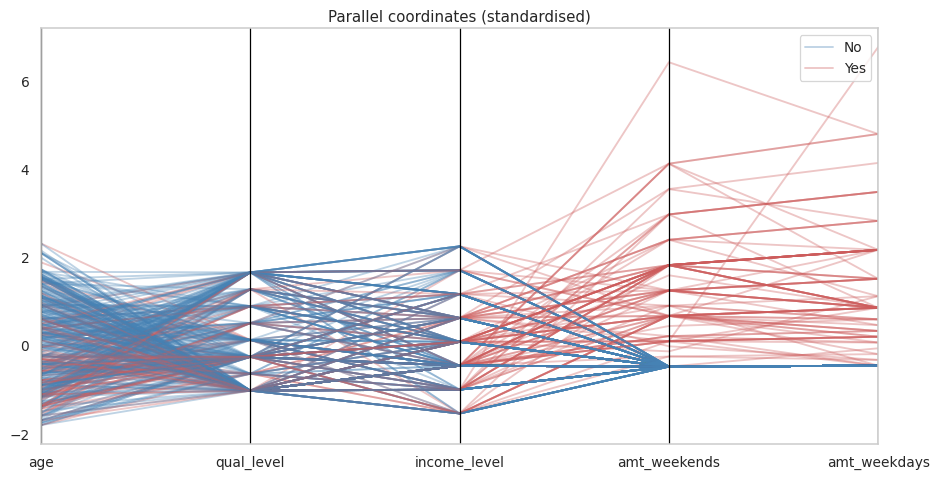

In [84]:
# Module 4.6 | n-D analysis - parallel coordinates of standardised variables for a random sample of respondents split by smoking status
from pandas.plotting import parallel_coordinates
pc_cols = ['age', 'qual_level', 'income_level', 'amt_weekends', 'amt_weekdays']
pc = clean[pc_cols].copy()
pc = (pc - pc.mean()) / pc.std()
pc['smoke'] = clean['smoke']
plt.figure(figsize=(12, 6))
parallel_coordinates(pc.sample(400, random_state=RANDOM_STATE), 'smoke', color=['steelblue', 'indianred'], alpha=0.35)
plt.title('Parallel coordinates (standardised)')
plt.show()

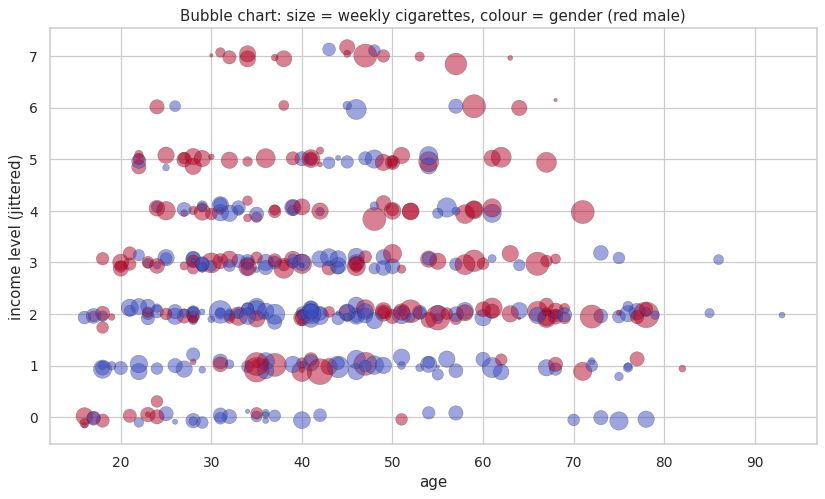

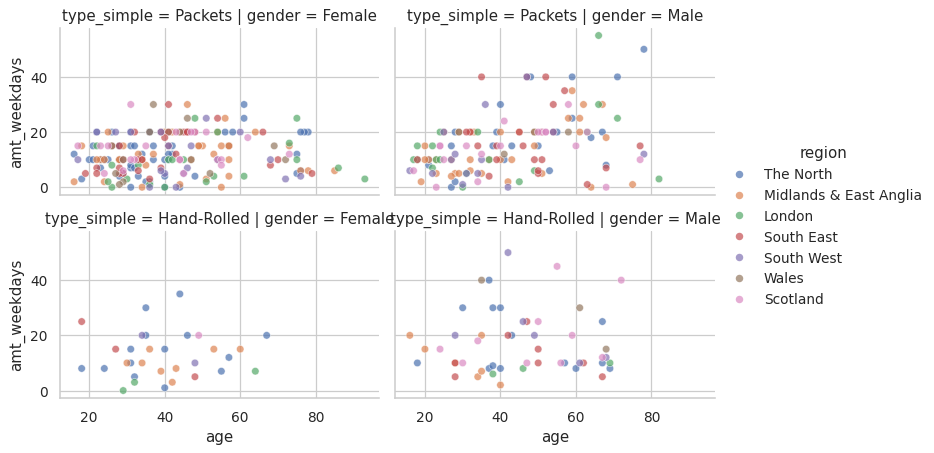

In [85]:
# Module 4.6 | n-D analysis - bubble chart (age, income, consumption, gender, cigarette type) and faceted scatter plots
fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(smokers['age'], smokers['income_level'] + np.random.normal(0, 0.08, len(smokers)), s=smokers['weekly_cigs'] * 1.2 + 5,
                c=smokers['gender_flag'], cmap='coolwarm', alpha=0.5, edgecolor='k', linewidth=0.3)
ax.set_xlabel('age')
ax.set_ylabel('income level (jittered)')
ax.set_title('Bubble chart: size = weekly cigarettes, colour = gender (red male)')
plt.show()
sns.relplot(data=smokers, x='age', y='amt_weekdays', col='gender', row='type_simple', hue='region', height=2.6, aspect=1.6, alpha=0.7)
plt.show()

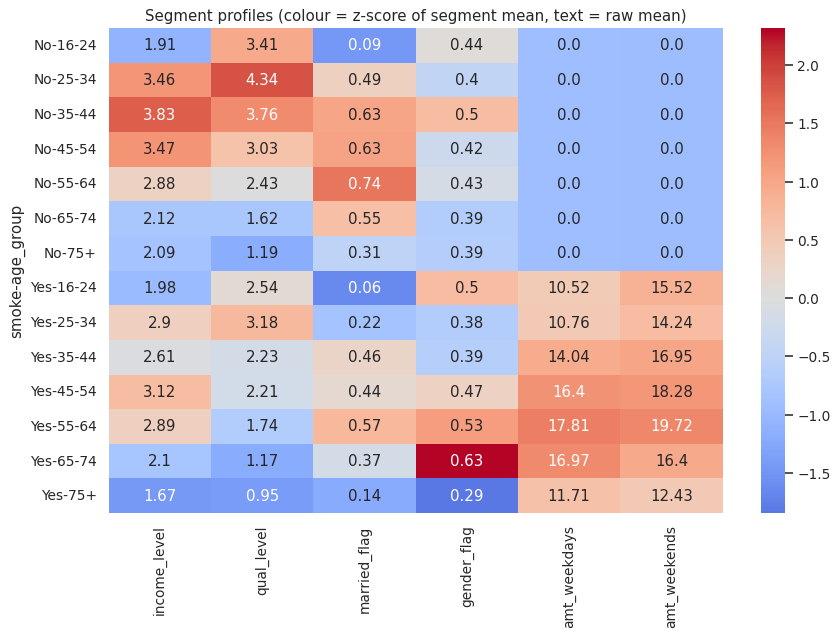

In [86]:
# Module 4.6 | n-D analysis - group profile heatmap: mean of every standardised variable per age group and smoking-type segment
profile = clean.groupby(['smoke', 'age_group'], observed=True)[['income_level', 'qual_level', 'married_flag', 'gender_flag', 'amt_weekdays', 'amt_weekends']].mean()
profile_z = (profile - profile.mean()) / profile.std()
plt.figure(figsize=(11, 7))
sns.heatmap(profile_z, annot=profile.round(2), fmt='', cmap='coolwarm', center=0)
plt.title('Segment profiles (colour = z-score of segment mean, text = raw mean)')
plt.show()

## 4.7 Visualization: scatter plots, dot charts and bar plots

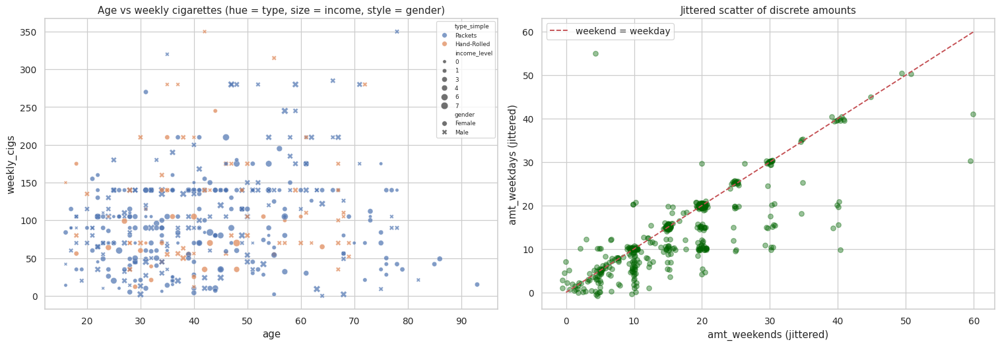

In [87]:
# Module 4.7 | Scatter plots - scatter with colour, size and marker encodings and a jittered scatter for discrete variables
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.scatterplot(data=smokers, x='age', y='weekly_cigs', hue='type_simple', size='income_level', style='gender', alpha=0.7, ax=axes[0])
axes[0].set_title('Age vs weekly cigarettes (hue = type, size = income, style = gender)')
axes[0].legend(fontsize=7, loc='upper right')
jx = smokers['amt_weekends'] + np.random.normal(0, 0.4, len(smokers))
jy = smokers['amt_weekdays'] + np.random.normal(0, 0.4, len(smokers))
axes[1].scatter(jx, jy, alpha=0.4, color='darkgreen')
axes[1].plot([0, 60], [0, 60], 'r--', label='weekend = weekday')
axes[1].set_xlabel('amt_weekends (jittered)')
axes[1].set_ylabel('amt_weekdays (jittered)')
axes[1].legend()
axes[1].set_title('Jittered scatter of discrete amounts')
plt.tight_layout()
plt.show()

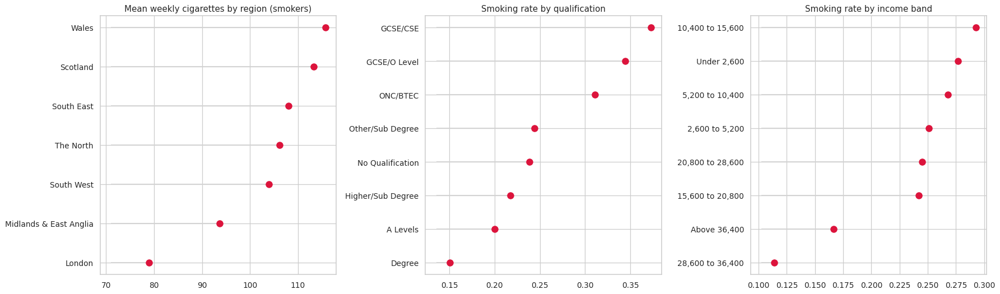

In [88]:
# Module 4.7 | Dot charts - Cleveland dot plots of mean weekly consumption by region and smoking rate by qualification and income
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
d1 = smokers.groupby('region')['weekly_cigs'].mean().sort_values()
d2 = clean.groupby('highest_qualification', observed=True)['smoke_flag'].mean().sort_values()
d3 = clean.groupby('gross_income', observed=True)['smoke_flag'].mean().sort_values()
for ax, d, title in zip(axes, [d1, d2, d3], ['Mean weekly cigarettes by region (smokers)', 'Smoking rate by qualification', 'Smoking rate by income band']):
    ax.hlines(y=range(len(d)), xmin=d.min() * 0.9, xmax=d.values, color='lightgray')
    ax.plot(d.values, range(len(d)), 'o', color='crimson', markersize=9)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels(d.index.astype(str))
    ax.set_title(title)
plt.tight_layout()
plt.show()

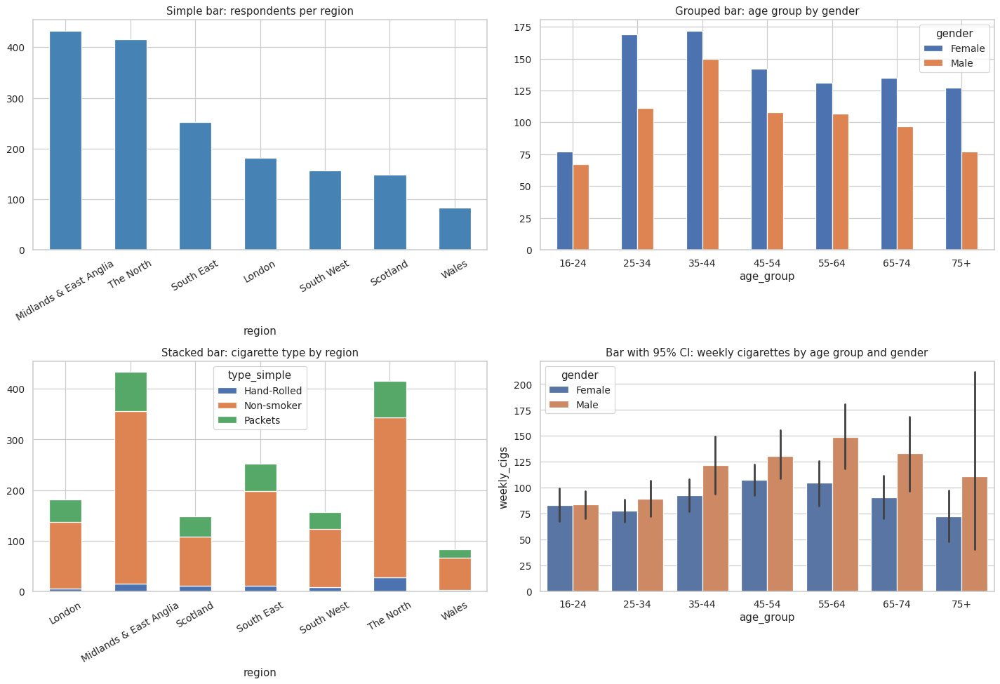

In [89]:
# Module 4.7 | Bar plots - simple, grouped, stacked and error-bar bar charts of smoking by categories
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
clean['region'].value_counts().plot(kind='bar', ax=axes[0, 0], color='steelblue', title='Simple bar: respondents per region', rot=30)
pd.crosstab(clean['age_group'], clean['gender']).plot(kind='bar', ax=axes[0, 1], title='Grouped bar: age group by gender', rot=0)
pd.crosstab(clean['region'], clean['type_simple']).plot(kind='bar', stacked=True, ax=axes[1, 0], title='Stacked bar: cigarette type by region', rot=30)
sns.barplot(data=smokers, x='age_group', y='weekly_cigs', hue='gender', errorbar=('ci', 95), ax=axes[1, 1])
axes[1, 1].set_title('Bar with 95% CI: weekly cigarettes by age group and gender')
plt.tight_layout()
plt.show()

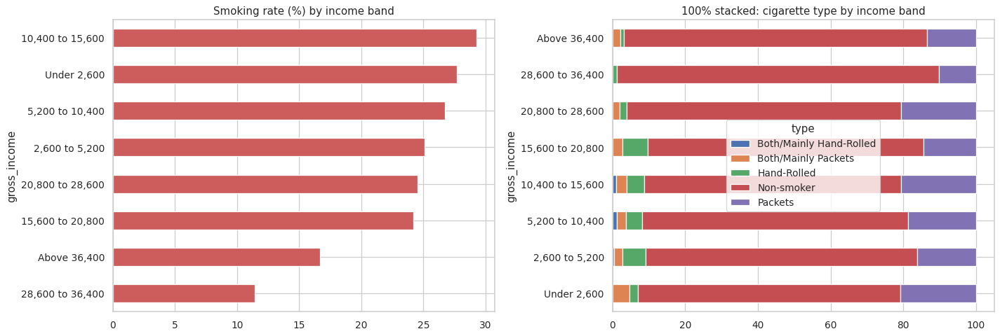

In [90]:
# Module 4.7 | Bar plots - horizontal sorted bar chart and 100% stacked bar of smoking rate by income band
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
(clean.groupby('gross_income', observed=True)['smoke_flag'].mean() * 100).sort_values().plot(kind='barh', ax=axes[0], color='indianred', title='Smoking rate (%) by income band')
(pd.crosstab(clean['gross_income'], clean['type'], normalize='index') * 100).plot(kind='barh', stacked=True, ax=axes[1], title='100% stacked: cigarette type by income band')
plt.tight_layout()
plt.show()

## 4.8 Outlier detection

,lower fence,upper fence,IQR outliers,z>3 outliers,modified z>3.5 outliers
variable,,,,,
age,-12.5,111.5,0,0,0
amt_weekends (smokers),-5.0,35.0,20,4,5
amt_weekdays (smokers),-12.5,39.5,14,4,3


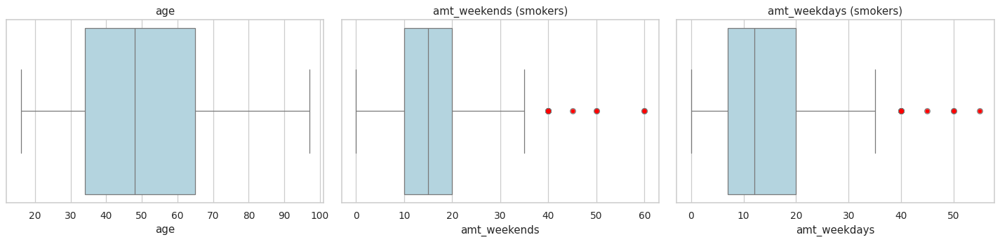

In [91]:
# Module 4.8 | Outlier detection (univariate) - Tukey IQR fences, z-score and modified z-score rules on age and consumption
def outlier_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    mad = stats.median_abs_deviation(s)
    mz = 0.6745 * (s - s.median()) / mad if mad > 0 else pd.Series(0, index=s.index)
    return pd.DataFrame({'iqr': (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr), 'z>3': z.abs() > 3, 'modified z>3.5': mz.abs() > 3.5}), (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

rows = []
flags = {}
for name, s in uni.items():
    f, (lo, hi) = outlier_flags(s)
    flags[name] = f
    rows.append((name, round(lo, 2), round(hi, 2), *f.sum().tolist()))
display(pd.DataFrame(rows, columns=['variable', 'lower fence', 'upper fence', 'IQR outliers', 'z>3 outliers', 'modified z>3.5 outliers']).set_index('variable'))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, s) in zip(axes, uni.items()):
    sns.boxplot(x=s, ax=ax, color='lightblue')
    ax.scatter(s[flags[name]['iqr']], np.zeros(flags[name]['iqr'].sum()), color='red', s=15, zorder=3)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [92]:
# Module 4.8 | Outlier detection (multivariate) - Mahalanobis distance, Isolation Forest and Local Outlier Factor on the numeric feature set
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
out_cols = ['age', 'qual_level', 'income_level', 'amt_weekends', 'amt_weekdays']
Xo = StandardScaler().fit_transform(clean[out_cols])
cov_inv = np.linalg.inv(np.cov(Xo, rowvar=False))
md_sq = np.einsum('ij,jk,ik->i', Xo - Xo.mean(axis=0), cov_inv, Xo - Xo.mean(axis=0))
mahal_out = md_sq > stats.chi2.ppf(0.999, df=len(out_cols))
iso = IsolationForest(contamination=0.02, random_state=RANDOM_STATE).fit(Xo)
iso_out = iso.predict(Xo) == -1
lof_out = LocalOutlierFactor(n_neighbors=20, contamination=0.02).fit_predict(Xo) == -1
outlier_table = pd.DataFrame({'Mahalanobis (chi2 99.9%)': mahal_out, 'Isolation Forest': iso_out, 'LOF': lof_out}, index=clean.index)
display(outlier_table.sum().to_frame('outliers flagged'))
display(outlier_table.sum(axis=1).value_counts().sort_index().to_frame('records').rename_axis('methods agreeing'))

,outliers flagged
Mahalanobis (chi2 99.9%),37
Isolation Forest,34
LOF,34


,records
methods agreeing,
0,1589
1,58
2,22
3,1


,age,gender,highest_qualification,gross_income,smoke,amt_weekends,amt_weekdays
116,71,Male,No Qualification,"15,600 to 20,800",Yes,40.0,40.0
138,37,Male,No Qualification,"2,600 to 5,200",Yes,40.0,40.0
192,59,Male,Degree,"28,600 to 36,400",Yes,40.0,40.0
196,38,Male,GCSE/O Level,"Above 36,400",Yes,30.0,15.0
234,78,Male,No Qualification,"5,200 to 10,400",Yes,50.0,50.0
288,48,Male,Other/Sub Degree,"15,600 to 20,800",Yes,40.0,40.0
548,33,Male,Other/Sub Degree,"5,200 to 10,400",Yes,40.0,20.0
576,56,Female,Degree,"15,600 to 20,800",Yes,35.0,25.0
678,23,Male,GCSE/CSE,"Under 2,600",Yes,30.0,10.0
735,67,Male,Degree,"20,800 to 28,600",Yes,30.0,30.0


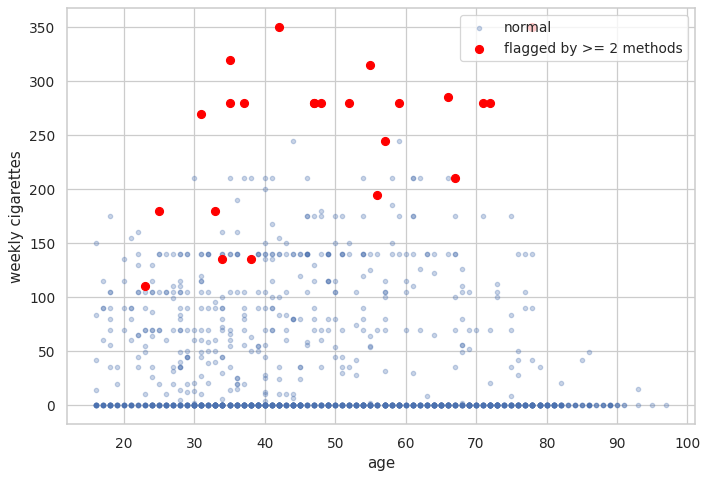

In [93]:
# Module 4.8 | Outlier detection (multivariate) - inspect records flagged by at least two methods and visualise them on age vs consumption
agreed = outlier_table.sum(axis=1) >= 2
display(clean.loc[agreed, ['age', 'gender', 'highest_qualification', 'gross_income', 'smoke', 'amt_weekends', 'amt_weekdays']].head(15))
plt.figure(figsize=(9, 6))
plt.scatter(clean['age'], clean['weekly_cigs'], s=12, alpha=0.3, label='normal')
plt.scatter(clean.loc[agreed, 'age'], clean.loc[agreed, 'weekly_cigs'], color='red', s=40, label='flagged by >= 2 methods')
plt.xlabel('age')
plt.ylabel('weekly cigarettes')
plt.legend()
plt.show()

In [94]:
# Module 4.8 | Outlier treatment - winsorisation (capping at the IQR fences) and its effect on summary statistics of weekday consumption
s = smokers['amt_weekdays']
q1, q3 = s.quantile([0.25, 0.75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
capped = s.clip(lower=lo, upper=hi)
removed = s[(s >= lo) & (s <= hi)]
treat = pd.DataFrame({'original': s, 'capped (winsorised)': capped, 'outliers removed': removed}).agg(['count', 'mean', 'std', 'skew', 'max']).T
display(treat.round(3))

,count,mean,std,skew,max
original,421.0,13.751,9.388,1.116,55.0
capped (winsorised),421.0,13.639,9.011,0.849,39.5
outliers removed,407.0,12.749,7.755,0.441,35.0


# Module 5: Clustering Algorithms

## 5.1 Feature matrix and number of clusters

In [95]:
# Module 5.1 | Clustering preparation - build the standardised feature matrix, its 2-D PCA projection and a cluster plotting helper
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
feat_cols = ['age', 'gender_flag', 'qual_level', 'income_level', 'married_flag', 'smoke_flag', 'amt_weekends', 'amt_weekdays']
X = StandardScaler().fit_transform(clean[feat_cols])
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
labels = {}

def show_clusters(lab, title, ax=None):
    ax = ax or plt.gca()
    sc = ax.scatter(pca2[:, 0], pca2[:, 1], c=lab, cmap='tab10', s=14, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    return sc
print('Feature matrix:', X.shape)

Feature matrix: (1670, 8)


,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,9366.100,0.344,1.312,711.270
3,7600.567,0.246,1.471,631.610
4,6737.745,0.231,1.471,545.814
5,6084.573,0.250,1.297,497.717
6,5504.623,0.241,1.451,474.922
7,5013.314,0.256,1.345,461.456
8,4717.732,0.273,1.345,434.938


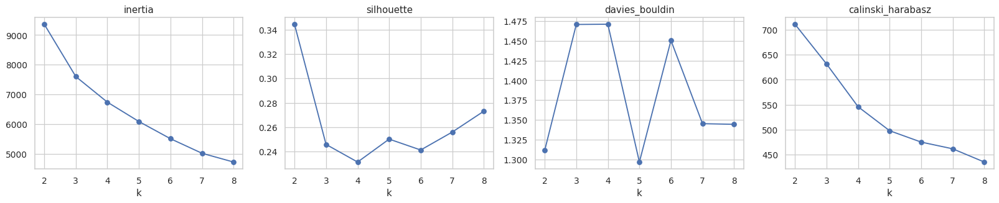

Chosen K = 5


In [96]:
# Module 5.1 | Choosing k - elbow (inertia) and silhouette, Davies-Bouldin and Calinski-Harabasz scores of k-means for k = 2..8 (K chosen as the best silhouette among k = 3..6 to avoid the trivial smoker/non-smoker split and over-fragmentation)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append((k, km.inertia_, silhouette_score(X, km.labels_), davies_bouldin_score(X, km.labels_), calinski_harabasz_score(X, km.labels_)))
kscan = pd.DataFrame(rows, columns=['k', 'inertia', 'silhouette', 'davies_bouldin', 'calinski_harabasz']).set_index('k')
display(kscan.round(3))
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, cn in zip(axes, kscan.columns):
    kscan[cn].plot(marker='o', ax=ax, title=cn)
plt.tight_layout()
plt.show()
K = int(kscan.loc[3:6, 'silhouette'].idxmax())
labels['K-means'] = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
print('Chosen K =', K)

## 5.2 Spectral clustering

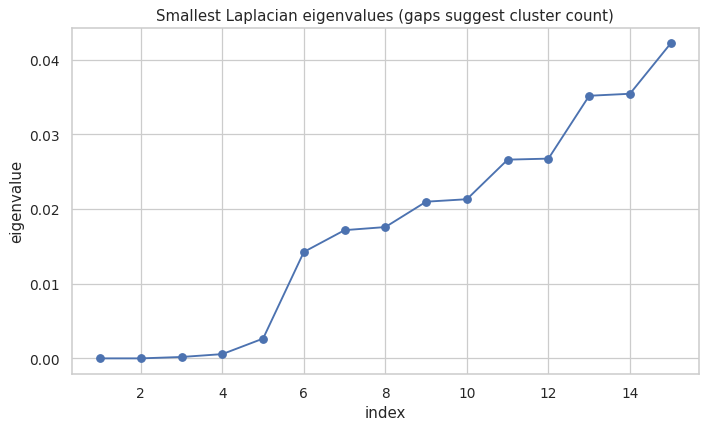

Cluster sizes: [217 418 374 345 316]


In [97]:
# Module 5.2 | Spectral clustering from scratch - k-NN similarity graph, normalised Laplacian, eigenvalue gap and k-means in the spectral embedding
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import laplacian
W = kneighbors_graph(X, n_neighbors=15, mode='connectivity', include_self=False)
W = 0.5 * (W + W.T)
L = laplacian(W, normed=True).toarray()
eigvals, eigvecs = np.linalg.eigh(L)
plt.plot(range(1, 16), eigvals[:15], marker='o')
plt.title('Smallest Laplacian eigenvalues (gaps suggest cluster count)')
plt.xlabel('index')
plt.ylabel('eigenvalue')
plt.show()
emb = eigvecs[:, :K]
emb = emb / np.linalg.norm(emb, axis=1, keepdims=True).clip(min=1e-12)
labels['Spectral (manual)'] = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(emb)
print('Cluster sizes:', np.bincount(labels['Spectral (manual)']))

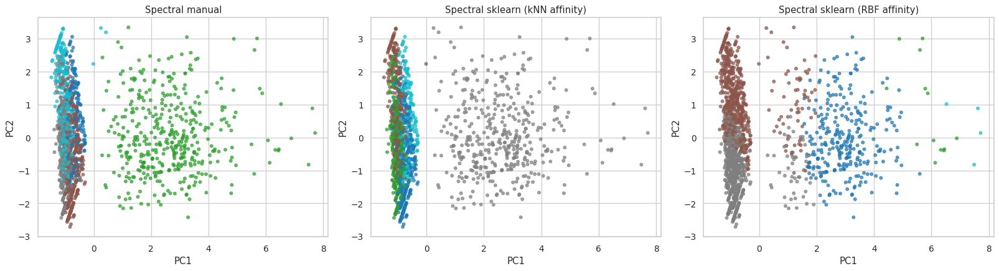

ARI manual vs sklearn kNN: 0.997


In [98]:
# Module 5.2 | Spectral clustering with scikit-learn - nearest-neighbour and RBF affinities compared with the manual version
sp_nn = SpectralClustering(n_clusters=K, affinity='nearest_neighbors', n_neighbors=15, assign_labels='kmeans', random_state=RANDOM_STATE).fit_predict(X)
sp_rbf = SpectralClustering(n_clusters=K, affinity='rbf', gamma=0.1, assign_labels='kmeans', random_state=RANDOM_STATE).fit_predict(X)
labels['Spectral (kNN)'] = sp_nn
labels['Spectral (RBF)'] = sp_rbf
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
show_clusters(labels['Spectral (manual)'], 'Spectral manual', axes[0])
show_clusters(sp_nn, 'Spectral sklearn (kNN affinity)', axes[1])
show_clusters(sp_rbf, 'Spectral sklearn (RBF affinity)', axes[2])
plt.tight_layout()
plt.show()
print('ARI manual vs sklearn kNN:', round(adjusted_rand_score(labels['Spectral (manual)'], sp_nn), 3))

## 5.3 Document clustering

In [99]:
# Module 5.3 | Document clustering - turn each respondent's categorical attributes into a text document and build the TF-IDF matrix
from sklearn.feature_extraction.text import TfidfVectorizer
doc_cols = ['gender', 'marital_status', 'highest_qualification', 'nationality', 'ethnicity', 'gross_income', 'region', 'age_group', 'type']
def tidy(v):
    return str(v).replace(' ', '').replace('/', '').replace(',', '').replace('&', 'and').replace('-', '')
docs = clean[doc_cols].astype(str).apply(lambda r: ' '.join(f'{cn}_{tidy(r[cn])}' for cn in doc_cols), axis=1)
print(docs.iloc[0])
tfidf = TfidfVectorizer()
T = tfidf.fit_transform(docs)
print('Documents x vocabulary:', T.shape, '| sparsity:', round(1 - T.nnz / (T.shape[0] * T.shape[1]), 3))

gender_Male marital_status_Divorced highest_qualification_NoQualification nationality_British ethnicity_White gross_income_2600to5200 region_TheNorth age_group_3544 type_Nonsmoker
Documents x vocabulary: (1670, 53) | sparsity: 0.83


In [100]:
# Module 5.3 | Document clustering - latent semantic analysis (TruncatedSVD), cosine k-means and the highest-weight terms of each cluster
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
lsa = normalize(TruncatedSVD(n_components=30, random_state=RANDOM_STATE).fit_transform(T))
doc_km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(lsa)
labels['Document (TF-IDF + LSA)'] = doc_km.labels_
terms = np.array(tfidf.get_feature_names_out())
for cid in range(K):
    centroid = np.asarray(T[doc_km.labels_ == cid].mean(axis=0)).ravel()
    print(f'Cluster {cid} (n={np.sum(doc_km.labels_ == cid)}):', ', '.join(terms[np.argsort(-centroid)[:6]]))
print('Cosine silhouette:', round(silhouette_score(lsa, doc_km.labels_, metric='cosine'), 3))

Cluster 0 (n=321): age_group_3544, marital_status_married, ethnicity_white, type_nonsmoker, gender_female, gender_male
Cluster 1 (n=230): age_group_6574, highest_qualification_noqualification, type_nonsmoker, ethnicity_white, nationality_english, gross_income_5200to10400
Cluster 2 (n=438): age_group_2534, marital_status_single, age_group_1624, ethnicity_white, gender_female, type_nonsmoker
Cluster 3 (n=217): age_group_75, marital_status_widowed, highest_qualification_noqualification, type_nonsmoker, gross_income_5200to10400, nationality_english
Cluster 4 (n=464): age_group_5564, age_group_4554, marital_status_married, ethnicity_white, type_nonsmoker, gender_female
Cosine silhouette: 0.158


Most similar pair of the first 300 documents: 19 108 similarity 1.0
gender_Male marital_status_Married highest_qualification_NoQualification nationality_English ethnicity_White gross_income_20800to28600 region_TheNorth age_group_5564 type_Nonsmoker
gender_Male marital_status_Married highest_qualification_NoQualification nationality_English ethnicity_White gross_income_20800to28600 region_TheNorth age_group_5564 type_Nonsmoker


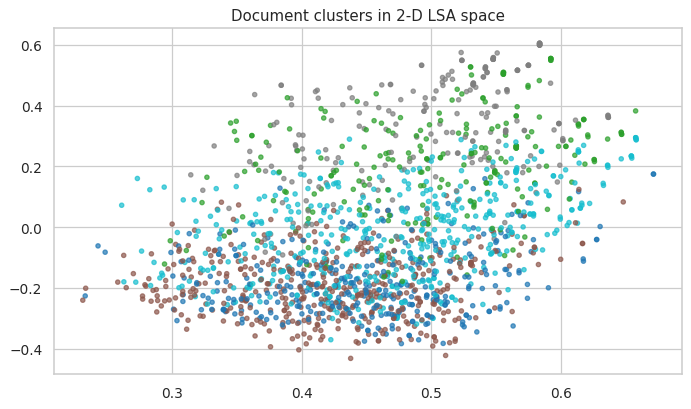

In [101]:
# Module 5.3 | Document clustering - cosine similarity between documents, most similar record pairs and a 2-D view of the LSA space
from sklearn.metrics.pairwise import cosine_similarity
sim = cosine_similarity(T[:300])
np.fill_diagonal(sim, 0)
i, j = np.unravel_index(sim.argmax(), sim.shape)
print('Most similar pair of the first 300 documents:', i, j, 'similarity', round(sim[i, j], 3))
print(docs.iloc[i])
print(docs.iloc[j])
lsa2 = TruncatedSVD(n_components=2, random_state=RANDOM_STATE).fit_transform(T)
plt.scatter(lsa2[:, 0], lsa2[:, 1], c=labels['Document (TF-IDF + LSA)'], cmap='tab10', s=12, alpha=0.7)
plt.title('Document clusters in 2-D LSA space')
plt.show()

## 5.4 Minimum spanning tree clustering

MST edges: 1669 | total weight: 696.25 | max edge: 4.582


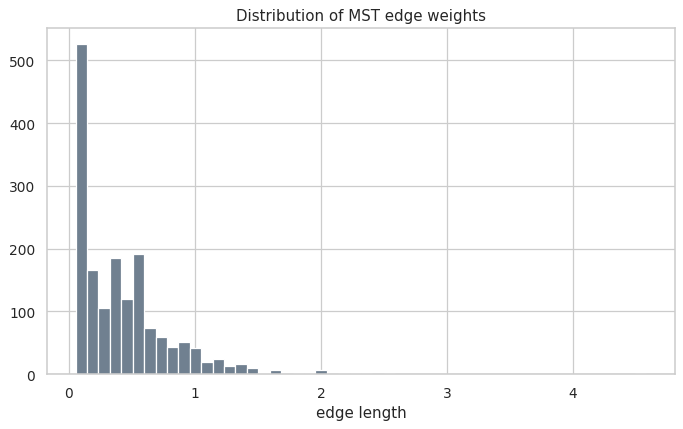

In [102]:
# Module 5.4 | MST clustering - compute pairwise distances and the minimum spanning tree of all respondents
from scipy.spatial.distance import pdist, squareform
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
D = squareform(pdist(X)) + 1e-9
np.fill_diagonal(D, 0)
mst = minimum_spanning_tree(D).tocoo()
edges = np.column_stack([mst.row, mst.col, mst.data])
print('MST edges:', len(edges), '| total weight:', round(edges[:, 2].sum(), 2), '| max edge:', round(edges[:, 2].max(), 3))
plt.hist(edges[:, 2], bins=50, color='slategray')
plt.title('Distribution of MST edge weights')
plt.xlabel('edge length')
plt.show()

In [103]:
# Module 5.4 | MST clustering - cut the longest edges (each cut must leave every cluster with at least 30 members) to obtain K clusters
n_pts = len(X)
order = np.argsort(-edges[:, 2])
keep = np.ones(len(edges), dtype=bool)
n_comp = 1
for idx in order:
    if n_comp >= K:
        break
    keep[idx] = False
    g = csr_matrix((edges[keep, 2], (edges[keep, 0].astype(int), edges[keep, 1].astype(int))), shape=(n_pts, n_pts))
    nc, lab = connected_components(g, directed=False)
    if np.bincount(lab).min() >= 30:
        n_comp = nc
    else:
        keep[idx] = True
labels['MST'] = lab
print('Clusters:', n_comp, '| sizes:', np.bincount(lab), '| cut edge lengths:', np.round(np.sort(edges[~keep, 2])[::-1], 3))

Clusters: 5 | sizes: [530 161 719 188  72] | cut edge lengths: [2.304 2.02  2.02  2.002]


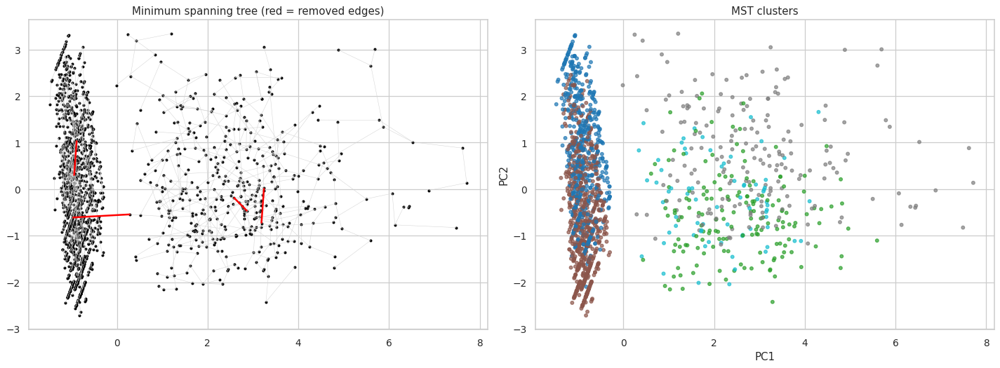

In [104]:
# Module 5.4 | MST clustering - draw the minimum spanning tree on the PCA plane with the cut edges highlighted and the resulting clusters
from matplotlib.collections import LineCollection
segs_keep = [[pca2[int(a)], pca2[int(b)]] for a, b, _ in edges[keep]]
segs_cut = [[pca2[int(a)], pca2[int(b)]] for a, b, _ in edges[~keep]]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].add_collection(LineCollection(segs_keep, colors='lightgray', linewidths=0.4))
axes[0].add_collection(LineCollection(segs_cut, colors='red', linewidths=2))
axes[0].scatter(pca2[:, 0], pca2[:, 1], s=5, color='black')
axes[0].set_title('Minimum spanning tree (red = removed edges)')
show_clusters(labels['MST'], 'MST clusters', axes[1])
plt.tight_layout()
plt.show()

## 5.5 Model-based clustering and the EM algorithm

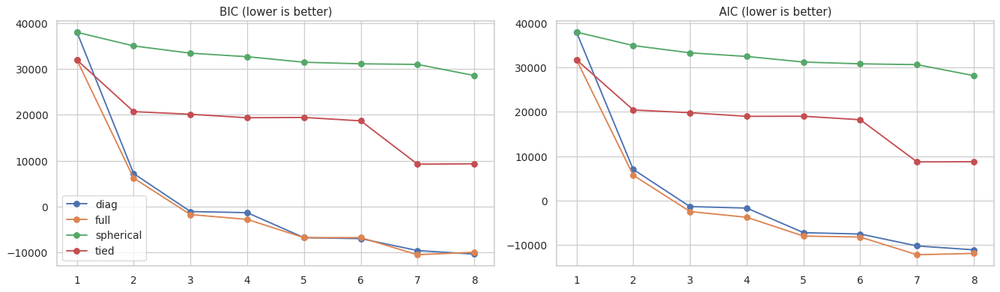

Best model by BIC: full with 7 components


In [105]:
# Module 5.5 | Model-based clustering - Gaussian mixture models: BIC and AIC over covariance structures and number of components
from sklearn.mixture import GaussianMixture
rows = []
for cov_type in ['spherical', 'diag', 'tied', 'full']:
    for k in range(1, 9):
        gm = GaussianMixture(n_components=k, covariance_type=cov_type, n_init=2, reg_covar=1e-3, random_state=RANDOM_STATE).fit(X)
        rows.append((cov_type, k, gm.bic(X), gm.aic(X)))
gm_scan = pd.DataFrame(rows, columns=['covariance', 'k', 'BIC', 'AIC'])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for cov_type, grp in gm_scan.groupby('covariance'):
    axes[0].plot(grp['k'], grp['BIC'], marker='o', label=cov_type)
    axes[1].plot(grp['k'], grp['AIC'], marker='o', label=cov_type)
axes[0].set_title('BIC (lower is better)')
axes[1].set_title('AIC (lower is better)')
axes[0].legend()
plt.tight_layout()
plt.show()
best = gm_scan.loc[gm_scan['BIC'].idxmin()]
print('Best model by BIC:', best['covariance'], 'with', int(best['k']), 'components')

Mixing weights: [0.132 0.222 0.112 0.097 0.207 0.187 0.043]
Mean assignment uncertainty: 0.0032 | records with uncertainty > 0.2: 8


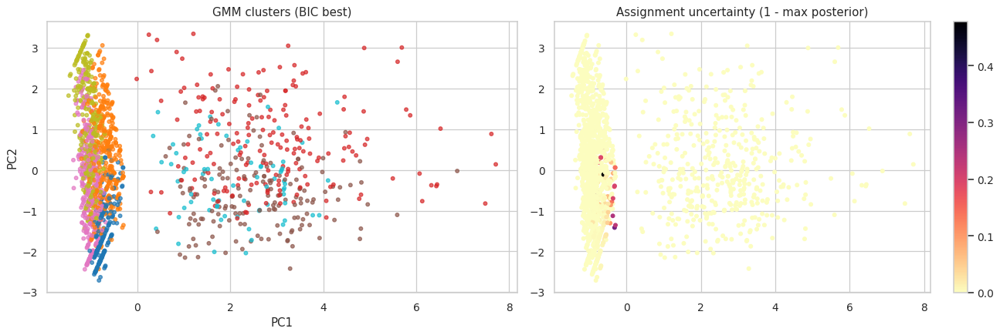

In [106]:
# Module 5.5 | Model-based clustering - fit the BIC-best mixture, inspect mixing weights and posterior uncertainty of the assignments
gm_best = GaussianMixture(n_components=int(best['k']), covariance_type=best['covariance'], n_init=5, reg_covar=1e-3, random_state=RANDOM_STATE).fit(X)
labels['GMM (BIC best)'] = gm_best.predict(X)
post = gm_best.predict_proba(X)
uncertainty = 1 - post.max(axis=1)
print('Mixing weights:', gm_best.weights_.round(3))
print('Mean assignment uncertainty:', uncertainty.mean().round(4), '| records with uncertainty > 0.2:', (uncertainty > 0.2).sum())
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
show_clusters(labels['GMM (BIC best)'], 'GMM clusters (BIC best)', axes[0])
sc = axes[1].scatter(pca2[:, 0], pca2[:, 1], c=uncertainty, cmap='magma_r', s=14)
axes[1].set_title('Assignment uncertainty (1 - max posterior)')
plt.colorbar(sc, ax=axes[1])
plt.tight_layout()
plt.show()

In [107]:
# Module 5.5 | Expectation-Maximization algorithm - implement EM for a Gaussian mixture from scratch (E-step responsibilities, M-step parameter updates)
def em_gmm(Z, K_, n_iter=300, tol=1e-7, seed=RANDOM_STATE):
    n, d = Z.shape
    rng = np.random.default_rng(seed)
    mu = Z[rng.choice(n, K_, replace=False)]
    cov = np.array([np.cov(Z.T) for _ in range(K_)])
    pi = np.full(K_, 1 / K_)
    history = []
    for it in range(n_iter):
        logp = np.column_stack([np.log(pi[k]) + stats.multivariate_normal(mu[k], cov[k], allow_singular=True).logpdf(Z) for k in range(K_)])
        mx = logp.max(axis=1, keepdims=True)
        loglik = (mx.ravel() + np.log(np.exp(logp - mx).sum(axis=1))).sum()
        resp = np.exp(logp - mx)
        resp /= resp.sum(axis=1, keepdims=True)
        Nk = resp.sum(axis=0)
        pi = Nk / n
        mu = (resp.T @ Z) / Nk[:, None]
        for k in range(K_):
            diff = Z - mu[k]
            cov[k] = (resp[:, k, None] * diff).T @ diff / Nk[k] + 1e-4 * np.eye(d)
        history.append(loglik)
        if it > 0 and abs(history[-1] - history[-2]) < tol * abs(history[-1]):
            break
    return pi, mu, cov, resp, history

pi_em, mu_gm, cov_gm, resp_em, hist_gm = em_gmm(pca2, K)
labels['GMM (manual EM, 2-D)'] = resp_em.argmax(axis=1)
print('Converged in', len(hist_gm), 'iterations | final log-likelihood:', round(hist_gm[-1], 2))
print('Mixing weights:', pi_em.round(3))
print('Means:\n', mu_gm.round(3))

Converged in 215 iterations | final log-likelihood: -4113.58
Mixing weights: [0.067 0.163 0.256 0.335 0.179]
Means:
 [[-1.173  2.354]
 [-0.636  0.672]
 [ 2.581  0.062]
 [-1.002 -0.046]
 [-0.797 -1.505]]


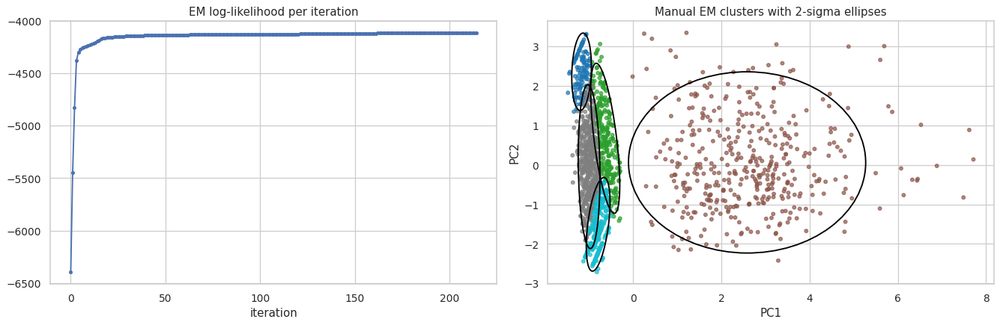

Manual EM avg log-likelihood: -2.4632 | sklearn avg log-likelihood: -2.4839
ARI manual EM vs sklearn GMM: 0.414


In [108]:
# Module 5.5 | Expectation-Maximization algorithm - convergence curve, cluster ellipses and agreement with scikit-learn's EM implementation
from matplotlib.patches import Ellipse
sk_gm = GaussianMixture(n_components=K, covariance_type='full', n_init=5, random_state=RANDOM_STATE).fit(pca2)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(hist_gm, marker='o', markersize=3)
axes[0].set_title('EM log-likelihood per iteration')
axes[0].set_xlabel('iteration')
show_clusters(labels['GMM (manual EM, 2-D)'], 'Manual EM clusters with 2-sigma ellipses', axes[1])
for k in range(K):
    vals, vecs = np.linalg.eigh(cov_gm[k])
    ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    axes[1].add_patch(Ellipse(mu_gm[k], 4 * np.sqrt(vals[1]), 4 * np.sqrt(vals[0]), angle=ang, fill=False, color='black', linewidth=1.5))
plt.tight_layout()
plt.show()
print('Manual EM avg log-likelihood:', round(hist_gm[-1] / len(pca2), 4), '| sklearn avg log-likelihood:', round(sk_gm.score(pca2), 4))
print('ARI manual EM vs sklearn GMM:', round(adjusted_rand_score(labels['GMM (manual EM, 2-D)'], sk_gm.predict(pca2)), 3))

## 5.6 Hierarchical agglomerative model-based clustering

,cophenetic correlation
linkage,
ward,0.6884
complete,0.7455
average,0.7955
single,0.6048


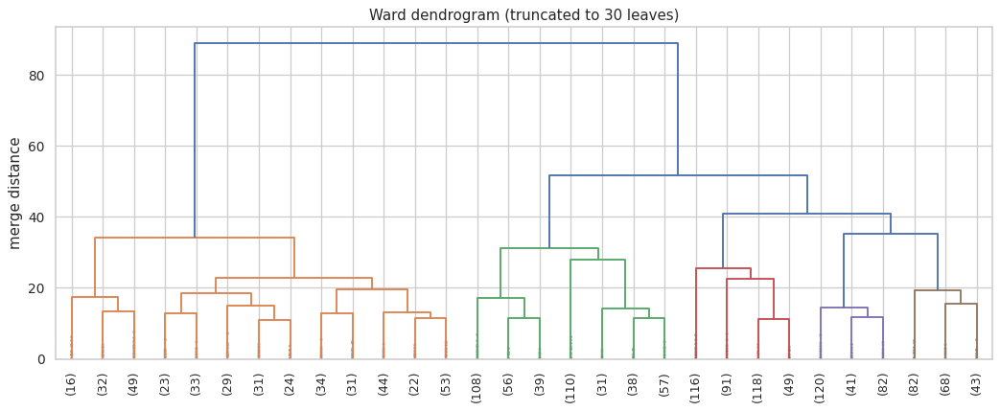

Cluster sizes: [421 439 374 243 193]


In [109]:
# Module 5.6 | Hierarchical agglomerative clustering - Ward linkage dendrogram, cophenetic correlation and linkage method comparison
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
rows = []
for method in ['ward', 'complete', 'average', 'single']:
    Zm = linkage(X, method=method)
    rows.append((method, cophenet(Zm, pdist(X))[0]))
display(pd.DataFrame(rows, columns=['linkage', 'cophenetic correlation']).set_index('linkage').round(4))
Z = linkage(X, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, show_contracted=True, color_threshold=Z[-(K - 1), 2])
plt.title('Ward dendrogram (truncated to 30 leaves)')
plt.ylabel('merge distance')
plt.show()
labels['Hierarchical (Ward)'] = fcluster(Z, t=K, criterion='maxclust') - 1
print('Cluster sizes:', np.bincount(labels['Hierarchical (Ward)']))

,BIC,AIC,avg log-likelihood
k,,,
1,31943.69,31705.18,-9.47
2,6189.26,5706.83,-1.66
3,-1746.79,-2473.15,0.82
4,5834.66,4864.38,-1.35
5,2681.13,1466.92,-0.31
6,-3819.18,-5277.31,1.74
7,-7813.08,-9515.14,3.04
8,-8075.32,-10021.31,3.22


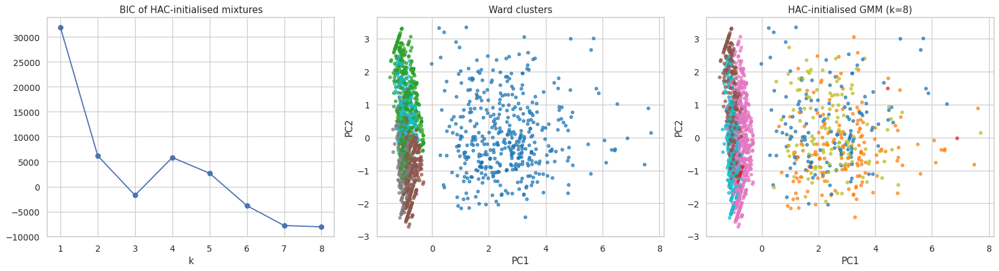

In [110]:
# Module 5.6 | Hierarchical model-based clustering - initialise a Gaussian mixture from agglomerative partitions for k = 1..8 and choose k by BIC
rows = []
hac_gmms = {}
for k in range(1, 9):
    part = fcluster(Z, t=k, criterion='maxclust') - 1 if k > 1 else np.zeros(len(X), dtype=int)
    means0 = np.vstack([X[part == c_].mean(axis=0) for c_ in np.unique(part)])
    gm = GaussianMixture(n_components=len(means0), covariance_type='full', means_init=means0, reg_covar=1e-3, random_state=RANDOM_STATE).fit(X)
    hac_gmms[k] = gm
    rows.append((k, gm.bic(X), gm.aic(X), gm.score(X)))
hac_scan = pd.DataFrame(rows, columns=['k', 'BIC', 'AIC', 'avg log-likelihood']).set_index('k')
display(hac_scan.round(2))
best_k_hac = int(hac_scan['BIC'].idxmin())
labels['HAC-initialised GMM'] = hac_gmms[best_k_hac].predict(X)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
hac_scan['BIC'].plot(marker='o', ax=axes[0], title='BIC of HAC-initialised mixtures')
show_clusters(labels['Hierarchical (Ward)'], 'Ward clusters', axes[1])
show_clusters(labels['HAC-initialised GMM'], f'HAC-initialised GMM (k={best_k_hac})', axes[2])
plt.tight_layout()
plt.show()

## 5.7 Outlier detection using clustering

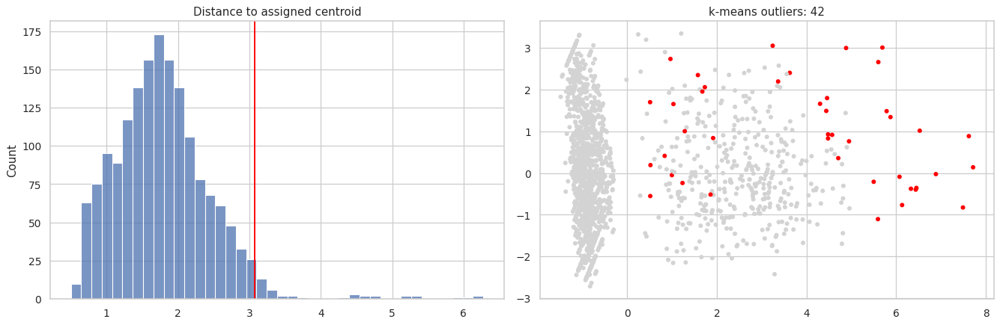

In [111]:
# Module 5.7 | Outlier detection using clustering - distance to the k-means centroid, flagged beyond the 97.5th percentile
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
dist_centroid = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
thr = np.percentile(dist_centroid, 97.5)
out_km = dist_centroid > thr
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(dist_centroid, bins=40, ax=axes[0])
axes[0].axvline(thr, color='red')
axes[0].set_title('Distance to assigned centroid')
axes[1].scatter(pca2[:, 0], pca2[:, 1], c=np.where(out_km, 'red', 'lightgray'), s=14)
axes[1].set_title(f'k-means outliers: {out_km.sum()}')
plt.tight_layout()
plt.show()

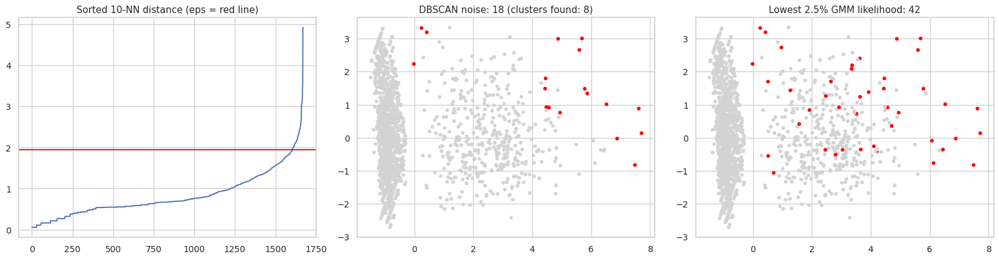

In [112]:
# Module 5.7 | Outlier detection using clustering - DBSCAN noise points with eps chosen from the k-distance curve, and low-likelihood GMM points
from sklearn.neighbors import NearestNeighbors
kdist = np.sort(NearestNeighbors(n_neighbors=10).fit(X).kneighbors(X)[0][:, -1])
eps = float(np.percentile(kdist, 96))
db = DBSCAN(eps=eps, min_samples=10).fit(X)
out_db = db.labels_ == -1
out_gm = gm_best.score_samples(X) < np.percentile(gm_best.score_samples(X), 2.5)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(kdist)
axes[0].axhline(eps, color='red')
axes[0].set_title('Sorted 10-NN distance (eps = red line)')
axes[1].scatter(pca2[:, 0], pca2[:, 1], c=np.where(out_db, 'red', 'lightgray'), s=14)
axes[1].set_title(f'DBSCAN noise: {out_db.sum()} (clusters found: {len(set(db.labels_)) - 1})')
axes[2].scatter(pca2[:, 0], pca2[:, 1], c=np.where(out_gm, 'red', 'lightgray'), s=14)
axes[2].set_title(f'Lowest 2.5% GMM likelihood: {out_gm.sum()}')
plt.tight_layout()
plt.show()

In [113]:
# Module 5.7 | Outlier detection using clustering - agreement between the three cluster-based detectors and profile of the consensus outliers
cluster_out = pd.DataFrame({'kmeans distance': out_km, 'DBSCAN noise': out_db, 'GMM low likelihood': out_gm})
display(cluster_out.sum().to_frame('flagged'))
display(cluster_out.sum(axis=1).value_counts().sort_index().to_frame('records').rename_axis('detectors agreeing'))
display(clean.loc[cluster_out.sum(axis=1) >= 2, ['age', 'gender', 'smoke', 'amt_weekends', 'amt_weekdays', 'highest_qualification', 'gross_income']].head(12))

,flagged
kmeans distance,42
DBSCAN noise,18
GMM low likelihood,42


,records
detectors agreeing,
0,1609
1,33
2,15
3,13


,age,gender,smoke,amt_weekends,amt_weekdays,highest_qualification,gross_income
116,71,Male,Yes,40.0,40.0,No Qualification,"15,600 to 20,800"
192,59,Male,Yes,40.0,40.0,Degree,"28,600 to 36,400"
196,38,Male,Yes,30.0,15.0,GCSE/O Level,"Above 36,400"
234,78,Male,Yes,50.0,50.0,No Qualification,"5,200 to 10,400"
288,48,Male,Yes,40.0,40.0,Other/Sub Degree,"15,600 to 20,800"
548,33,Male,Yes,40.0,20.0,Other/Sub Degree,"5,200 to 10,400"
576,56,Female,Yes,35.0,25.0,Degree,"15,600 to 20,800"
735,67,Male,Yes,30.0,30.0,Degree,"20,800 to 28,600"
817,62,Male,Yes,30.0,30.0,No Qualification,"20,800 to 28,600"
871,30,Male,Yes,1.0,0.0,Degree,"Above 36,400"


## 5.8 Cluster validation and profiling

In [114]:
# Module 5.8 | Cluster validation - silhouette, Davies-Bouldin and Calinski-Harabasz scores for every clustering method
rows = []
for name, lab in labels.items():
    if len(np.unique(lab)) > 1 and name != 'GMM (manual EM, 2-D)':
        rows.append((name, len(np.unique(lab)), silhouette_score(X, lab), davies_bouldin_score(X, lab), calinski_harabasz_score(X, lab)))
validation = pd.DataFrame(rows, columns=['method', 'clusters', 'silhouette', 'davies_bouldin', 'calinski_harabasz']).set_index('method')
validation.sort_values('silhouette', ascending=False).round(3)

,clusters,silhouette,davies_bouldin,calinski_harabasz
method,,,,
K-means,5,0.250,1.297,497.717
Spectral (manual),5,0.247,1.516,423.479
Spectral (kNN),5,0.246,1.517,421.683
Spectral (RBF),5,0.223,1.741,327.990
GMM (BIC best),7,0.217,1.627,353.098
MST,5,0.214,1.831,352.345
Hierarchical (Ward),5,0.208,1.341,426.215
HAC-initialised GMM,7,0.162,2.449,274.327
Document (TF-IDF + LSA),5,0.003,5.500,82.464


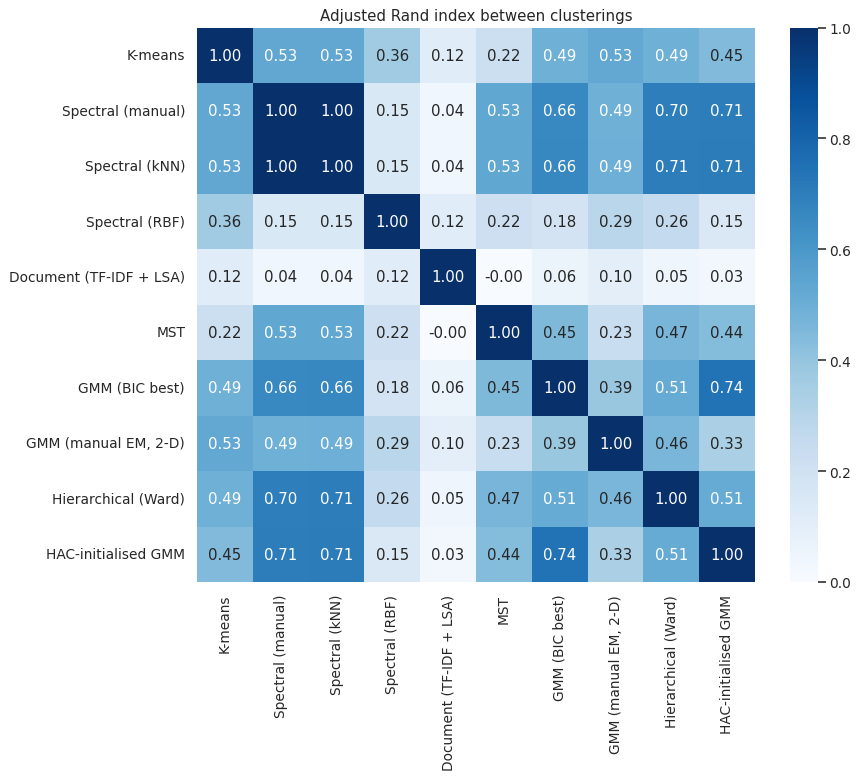

In [115]:
# Module 5.8 | Cluster validation - agreement matrix (adjusted Rand index) between all clustering methods
names = list(labels.keys())
ari = pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in names] for a in names], index=names, columns=names)
plt.figure(figsize=(10, 8))
sns.heatmap(ari, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Adjusted Rand index between clusterings')
plt.show()

Profiled method: K-means


,age,gender_flag,qual_level,income_level,married_flag,smoke_flag,amt_weekends,amt_weekdays,weekly_cigs,size
0,31.84,0.37,3.82,2.88,0.00,0.09,0.36,0.21,1.78,298
1,42.28,0.46,2.12,2.62,0.33,1.00,18.59,15.78,116.10,356
2,47.00,0.85,4.99,5.45,0.85,0.04,0.16,0.09,0.75,286
3,71.23,0.28,0.81,1.99,0.00,0.04,0.20,0.19,1.35,290
4,55.39,0.27,2.05,1.86,1.00,0.04,0.18,0.06,0.67,440


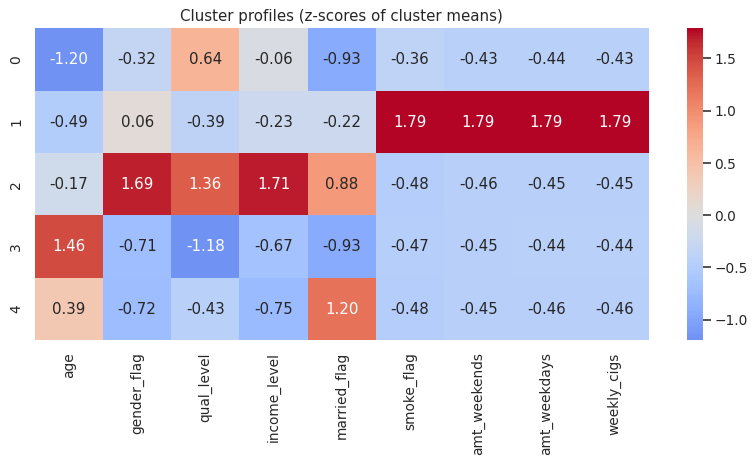

In [116]:
# Module 5.8 | Cluster profiling - mean of every feature and share of smokers in each cluster of the highest-silhouette method
best_method = validation['silhouette'].idxmax()
profile = clean[feat_cols + ['weekly_cigs']].groupby(labels[best_method]).mean()
profile['size'] = np.bincount(labels[best_method])
print('Profiled method:', best_method)
display(profile.round(2))
prof_z = (profile.drop(columns='size') - profile.drop(columns='size').mean()) / profile.drop(columns='size').std()
plt.figure(figsize=(11, 4.5))
sns.heatmap(prof_z, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Cluster profiles (z-scores of cluster means)')
plt.show()

# Module 6: Dimensionality Reduction

## 6.1 Feature selection

In [117]:
# Module 6.1 | Feature selection - build the candidate demographic feature set for predicting smoking status and apply a variance threshold
from sklearn.feature_selection import VarianceThreshold, SelectKBest, chi2, f_classif, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
Xfs = pd.concat([clean[['age', 'gender_flag', 'qual_level', 'income_level']], onehot.drop(columns=[c_ for c_ in onehot.columns if c_.startswith('type_simple')])], axis=1)
yfs = clean['smoke_flag']
Xfs_mm = pd.DataFrame(MinMaxScaler().fit_transform(Xfs), columns=Xfs.columns)
vt = VarianceThreshold(threshold=0.01).fit(Xfs_mm)
variances = pd.Series(vt.variances_, index=Xfs.columns).sort_values()
print('Candidate features:', Xfs.shape[1], '| kept by variance threshold 0.01:', int(vt.get_support().sum()))
variances.head(8).to_frame('min-max variance')

Candidate features: 24 | kept by variance threshold 0.01: 23


,min-max variance
ethnicity_Mixed,0.008313
nationality_group_Irish,0.013583
ethnicity_Chinese,0.015906
ethnicity_Black,0.019945
ethnicity_Asian,0.023948
marital_status_Separated,0.039061
nationality_group_Other,0.040159
region_Wales,0.047230


In [118]:
# Module 6.1 | Feature selection - correlation filter: list feature pairs above |r| = 0.8 and the features to drop
cm = Xfs.corr().abs()
upper = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool))
high = upper.stack()[upper.stack() > 0.8].sort_values(ascending=False)
display(high.to_frame('|r|'))
print('Features to drop:', [col for col in upper.columns if (upper[col] > 0.8).any()])

,,|r|
nationality_group_Other,nationality_group_UK,0.861318


Features to drop:

 ['nationality_group_UK']


In [119]:
# Module 6.1 | Feature selection - filter methods: mutual information, chi-square and ANOVA F-score against smoking status
mi = pd.Series(mutual_info_classif(Xfs, yfs, random_state=RANDOM_STATE, discrete_features=[c_ != 'age' for c_ in Xfs.columns]), index=Xfs.columns)
chi_scores = pd.Series(SelectKBest(chi2, k='all').fit(Xfs_mm, yfs).scores_, index=Xfs.columns)
f_scores = pd.Series(SelectKBest(f_classif, k='all').fit(Xfs, yfs).scores_, index=Xfs.columns)
filters = pd.DataFrame({'mutual information': mi, 'chi-square': chi_scores, 'ANOVA F': f_scores})
filters.sort_values('mutual information', ascending=False).round(4)

,mutual information,chi-square,ANOVA F
age,0.0278,10.0800,82.6647
marital_status_Married,0.0134,22.9938,45.3349
marital_status_Single,0.0124,32.6782,44.9239
qual_level,0.0120,4.1063,11.3362
income_level,0.0051,1.1864,6.9544
marital_status_Divorced,0.0031,9.9882,11.1142
region_Scotland,0.0021,6.7162,7.3931
marital_status_Widowed,0.0019,5.1290,5.9047
nationality_group_Irish,0.0017,6.2398,6.3433
region_Midlands & East Anglia,0.0015,3.6059,4.8764


In [120]:
# Module 6.1 | Feature selection - wrapper and embedded methods: RFE with logistic regression, L1 logistic regression and random-forest importance
Xs = StandardScaler().fit_transform(Xfs)
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=6).fit(Xs, yfs)
l1 = LogisticRegression(penalty='l1', solver='liblinear', C=0.05).fit(Xs, yfs)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xfs, yfs)
embedded = pd.DataFrame({'RFE rank (1 = selected)': rfe.ranking_, '|L1 coefficient|': np.abs(l1.coef_[0]), 'RF importance': rf.feature_importances_}, index=Xfs.columns)
embedded.sort_values('RF importance', ascending=False).round(4)

,RFE rank (1 = selected),|L1 coefficient|,RF importance
age,1,0.5199,0.3963
income_level,3,0.0079,0.1648
qual_level,1,0.2782,0.1489
gender_flag,2,0.0000,0.0441
marital_status_Married,1,0.2091,0.0226
region_Midlands & East Anglia,7,0.0168,0.0216
region_The North,8,0.0000,0.0215
marital_status_Single,13,0.0000,0.0205
region_London,15,0.0000,0.0199
region_South East,16,0.0000,0.0188


,MI,chi2,F,RFE,L1,RF,permutation,mean rank
age,1.0,3.0,1.0,1,1.0,1.0,1.0,1.3
qual_level,4.0,8.0,4.0,1,2.0,3.0,2.0,3.4
marital_status_Married,2.0,2.0,2.0,1,3.0,5.0,23.0,5.4
region_Scotland,7.0,5.0,6.0,1,5.0,12.0,15.5,7.4
income_level,5.0,11.0,7.0,3,9.0,2.0,15.5,7.5
marital_status_Divorced,6.0,4.0,5.0,1,6.0,13.0,21.0,8.0
nationality_group_Irish,9.0,6.0,8.0,1,4.0,20.0,12.0,8.6
marital_status_Single,3.0,1.0,3.0,13,17.5,8.0,18.0,9.1
region_Midlands & East Anglia,10.0,9.0,10.0,7,8.0,6.0,22.0,10.3
nationality_group_Other,12.0,12.0,12.0,6,7.0,19.0,9.0,11.0


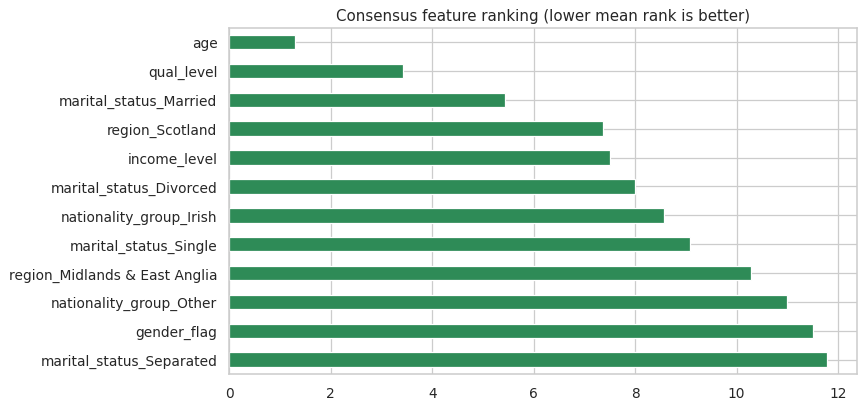

In [121]:
# Module 6.1 | Feature selection - permutation importance on a held-out split and a consensus ranking across all methods
from sklearn.inspection import permutation_importance
Xtr, Xte, ytr, yte = train_test_split(Xfs, yfs, test_size=0.25, stratify=yfs, random_state=RANDOM_STATE)
rf_tr = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
perm = permutation_importance(rf_tr, Xte, yte, n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=Xfs.columns)
ranks = pd.DataFrame({'MI': mi.rank(ascending=False), 'chi2': chi_scores.rank(ascending=False), 'F': f_scores.rank(ascending=False),
                      'RFE': embedded['RFE rank (1 = selected)'], 'L1': embedded['|L1 coefficient|'].rank(ascending=False),
                      'RF': embedded['RF importance'].rank(ascending=False), 'permutation': perm_s.rank(ascending=False)})
ranks['mean rank'] = ranks.mean(axis=1)
ranks = ranks.sort_values('mean rank')
display(ranks.head(10).round(1))
ranks['mean rank'].head(12)[::-1].plot(kind='barh', color='seagreen', title='Consensus feature ranking (lower mean rank is better)')
plt.show()

## 6.2 Principal Component Analysis

In [122]:
# Module 6.2 | PCA - fit PCA on the standardised feature matrix and tabulate eigenvalues and explained variance
pca = PCA(random_state=RANDOM_STATE).fit(X)
pc_names = [f'PC{i + 1}' for i in range(len(feat_cols))]
pca_table = pd.DataFrame({'eigenvalue': pca.explained_variance_, 'explained %': 100 * pca.explained_variance_ratio_,
                          'cumulative %': 100 * np.cumsum(pca.explained_variance_ratio_)}, index=pc_names)
display(pca_table.round(3))
print('Components with eigenvalue > 1 (Kaiser):', int((pca.explained_variance_ > 1).sum()))
print('Components for 80% / 90% / 95% variance:', [int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), v) + 1) for v in (0.8, 0.9, 0.95)])

,eigenvalue,explained %,cumulative %
PC1,2.791,34.871,34.871
PC2,1.777,22.196,57.066
PC3,1.135,14.178,71.245
PC4,0.891,11.137,82.382
PC5,0.677,8.462,90.844
PC6,0.436,5.444,96.287
PC7,0.229,2.860,99.147
PC8,0.068,0.853,100.000


Components with eigenvalue > 1 (Kaiser): 3
Components for 80% / 90% / 95% variance: [4, 5, 6]


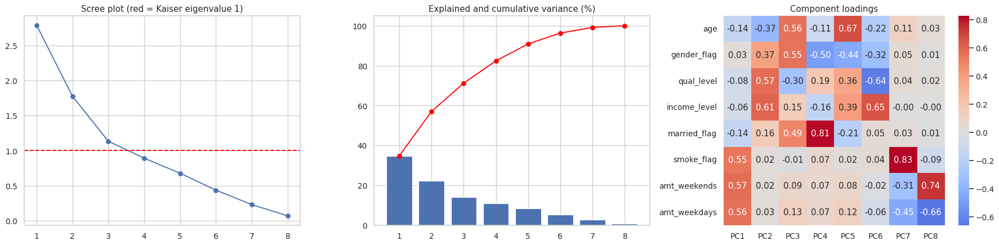

In [123]:
# Module 6.2 | PCA - scree plot, cumulative variance curve and loadings heatmap
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(range(1, 9), pca.explained_variance_, marker='o')
axes[0].axhline(1, color='red', linestyle='--')
axes[0].set_title('Scree plot (red = Kaiser eigenvalue 1)')
axes[1].bar(range(1, 9), 100 * pca.explained_variance_ratio_)
axes[1].plot(range(1, 9), 100 * np.cumsum(pca.explained_variance_ratio_), color='red', marker='o')
axes[1].set_title('Explained and cumulative variance (%)')
loadings = pd.DataFrame(pca.components_.T, index=feat_cols, columns=pc_names)
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[2])
axes[2].set_title('Component loadings')
plt.tight_layout()
plt.show()

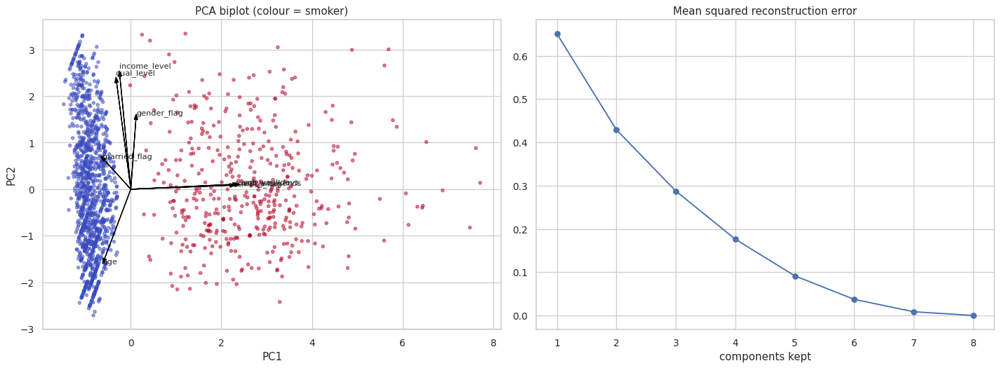

In [124]:
# Module 6.2 | PCA - projection onto the first two components with biplot arrows and reconstruction error versus number of components
scores = pca.transform(X)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(scores[:, 0], scores[:, 1], c=clean['smoke_flag'], cmap='coolwarm', s=12, alpha=0.5)
for i, f in enumerate(feat_cols):
    axes[0].arrow(0, 0, pca.components_[0, i] * 4, pca.components_[1, i] * 4, color='black', head_width=0.08)
    axes[0].text(pca.components_[0, i] * 4.3, pca.components_[1, i] * 4.3, f, fontsize=9)
axes[0].set_title('PCA biplot (colour = smoker)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
errors = []
for k in range(1, 9):
    Zk = scores[:, :k] @ pca.components_[:k] + pca.mean_
    errors.append(np.mean((X - Zk) ** 2))
axes[1].plot(range(1, 9), errors, marker='o')
axes[1].set_title('Mean squared reconstruction error')
axes[1].set_xlabel('components kept')
plt.tight_layout()
plt.show()

## 6.3 Singular Value Decomposition

In [125]:
# Module 6.3 | SVD - decompose the centred feature matrix with NumPy and relate singular values to PCA eigenvalues
Xc = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
eig_from_svd = S ** 2 / (len(X) - 1)
svd_check = pd.DataFrame({'singular value': S, 'eigenvalue from SVD': eig_from_svd, 'PCA eigenvalue': pca.explained_variance_}, index=pc_names)
display(svd_check.round(4))
print('Shapes U, S, Vt:', U.shape, S.shape, Vt.shape)
print('Eigenvalues match PCA:', np.allclose(eig_from_svd, pca.explained_variance_))
print('Right singular vectors match PCA components (up to sign):', np.allclose(np.abs(Vt), np.abs(pca.components_)))

,singular value,eigenvalue from SVD,PCA eigenvalue
PC1,68.2548,2.7913,2.7913
PC2,54.4549,1.7767,1.7767
PC3,43.5227,1.1349,1.1349
PC4,38.5734,0.8915,0.8915
PC5,33.6241,0.6774,0.6774
PC6,26.9676,0.4357,0.4357
PC7,19.5460,0.2289,0.2289
PC8,10.6745,0.0683,0.0683


Shapes U, S, Vt: (1670, 8) (8,) (8, 8)
Eigenvalues match PCA: True
Right singular vectors match PCA components (up to sign): True


,relative Frobenius error,energy captured %
rank,,
1,0.8070,34.8706
2,0.6552,57.0662
3,0.5362,71.2445
4,0.4197,82.3816
5,0.3026,90.8440
6,0.1927,96.2875
7,0.0924,99.1471
8,0.0000,100.0000


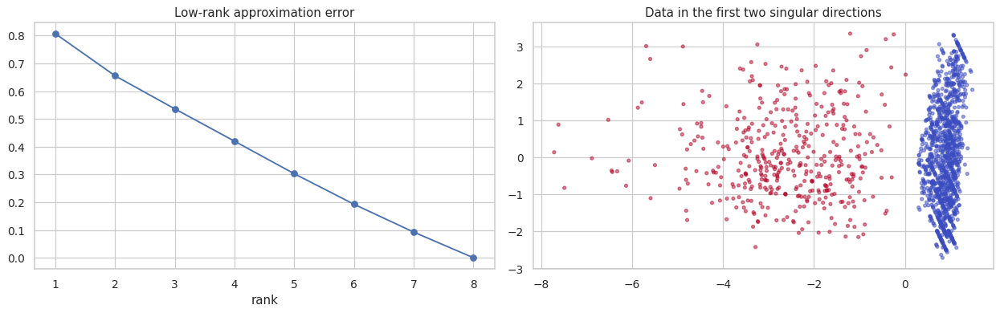

In [126]:
# Module 6.3 | SVD - low-rank approximation: relative reconstruction error and captured energy for each rank
rows = []
for r in range(1, 9):
    Xr = (U[:, :r] * S[:r]) @ Vt[:r]
    rows.append((r, np.linalg.norm(Xc - Xr) / np.linalg.norm(Xc), 100 * (S[:r] ** 2).sum() / (S ** 2).sum()))
svd_rank = pd.DataFrame(rows, columns=['rank', 'relative Frobenius error', 'energy captured %']).set_index('rank')
display(svd_rank.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
svd_rank['relative Frobenius error'].plot(marker='o', ax=axes[0], title='Low-rank approximation error')
axes[1].scatter(U[:, 0] * S[0], U[:, 1] * S[1], c=clean['smoke_flag'], cmap='coolwarm', s=10, alpha=0.5)
axes[1].set_title('Data in the first two singular directions')
plt.tight_layout()
plt.show()

## 6.4 Factor Analysis

In [127]:
# Module 6.4 | Factor analysis suitability - Bartlett's test of sphericity and the Kaiser-Meyer-Olkin measure
R = np.corrcoef(X, rowvar=False)
n_obs, p_var = X.shape
bart_chi2 = -(n_obs - 1 - (2 * p_var + 5) / 6) * np.log(np.linalg.det(R))
bart_df = p_var * (p_var - 1) / 2
bart_p = stats.chi2.sf(bart_chi2, bart_df)
inv_R = np.linalg.inv(R)
partial_r = -inv_R / np.sqrt(np.outer(np.diag(inv_R), np.diag(inv_R)))
off = ~np.eye(p_var, dtype=bool)
kmo_per_var = pd.Series([(R[i, off[i]] ** 2).sum() / ((R[i, off[i]] ** 2).sum() + (partial_r[i, off[i]] ** 2).sum()) for i in range(p_var)], index=feat_cols)
kmo_total = (R[off] ** 2).sum() / ((R[off] ** 2).sum() + (partial_r[off] ** 2).sum())
print(f'Bartlett chi2 = {bart_chi2:.2f}, df = {bart_df:.0f}, p = {bart_p:.3g}')
print(f'Overall KMO = {kmo_total:.3f} (above 0.6 is acceptable)')
kmo_per_var.round(3).to_frame('KMO')

Bartlett chi2 = 6280.09, df = 28, p = 0
Overall KMO = 0.687 (above 0.6 is acceptable)


,KMO
age,0.588
gender_flag,0.519
qual_level,0.541
income_level,0.554
married_flag,0.792
smoke_flag,0.878
amt_weekends,0.668
amt_weekdays,0.691


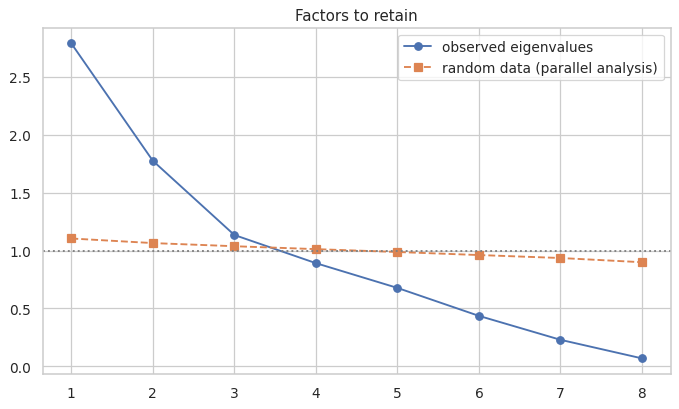

Kaiser factors: 3 | parallel analysis factors: 3


In [128]:
# Module 6.4 | Factor analysis - number of factors from the Kaiser criterion and parallel analysis against random data
real_eig = np.sort(np.linalg.eigvalsh(R))[::-1]
rng = np.random.default_rng(RANDOM_STATE)
sim_eig = np.mean([np.sort(np.linalg.eigvalsh(np.corrcoef(rng.normal(size=X.shape), rowvar=False)))[::-1] for _ in range(100)], axis=0)
n_factors = int((real_eig > sim_eig).sum())
plt.plot(range(1, 9), real_eig, marker='o', label='observed eigenvalues')
plt.plot(range(1, 9), sim_eig, marker='s', linestyle='--', label='random data (parallel analysis)')
plt.axhline(1, color='gray', linestyle=':')
plt.legend()
plt.title('Factors to retain')
plt.show()
print('Kaiser factors:', int((real_eig > 1).sum()), '| parallel analysis factors:', n_factors)

,Factor1,Factor2,Factor3,communality,uniqueness
age,-0.131,-0.106,0.815,0.692,0.309
gender_flag,0.074,0.386,0.051,0.157,0.843
qual_level,-0.102,0.474,-0.353,0.359,0.641
income_level,-0.035,0.910,-0.076,0.835,0.165
married_flag,-0.133,0.148,0.105,0.051,0.949
smoke_flag,0.830,-0.055,-0.138,0.710,0.289
amt_weekends,0.981,-0.021,-0.046,0.964,0.036
amt_weekdays,0.947,-0.003,0.004,0.896,0.104


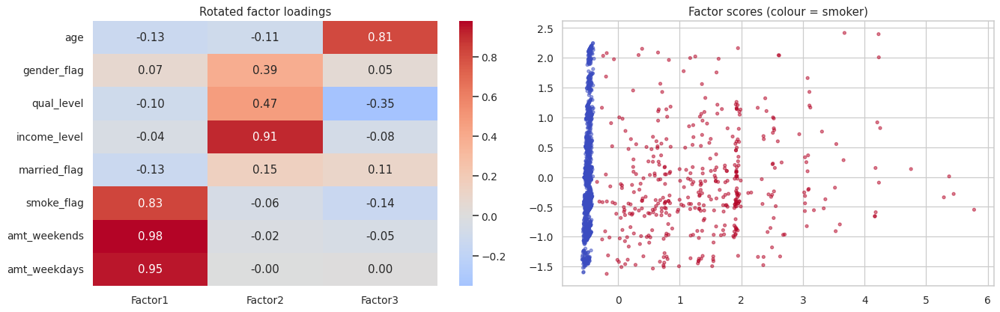

In [129]:
# Module 6.4 | Factor analysis - fit a varimax-rotated factor model, show loadings, communalities and uniquenesses
from sklearn.decomposition import FactorAnalysis
n_fa = max(n_factors, 2)
fa = FactorAnalysis(n_components=n_fa, rotation='varimax', random_state=RANDOM_STATE).fit(X)
fa_load = pd.DataFrame(fa.components_.T, index=feat_cols, columns=[f'Factor{i + 1}' for i in range(n_fa)])
fa_load['communality'] = (fa_load.iloc[:, :n_fa] ** 2).sum(axis=1)
fa_load['uniqueness'] = fa.noise_variance_
display(fa_load.round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(fa_load.iloc[:, :n_fa], annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Rotated factor loadings')
fs = fa.transform(X)
axes[1].scatter(fs[:, 0], fs[:, 1], c=clean['smoke_flag'], cmap='coolwarm', s=10, alpha=0.5)
axes[1].set_title('Factor scores (colour = smoker)')
plt.tight_layout()
plt.show()

## 6.5 Intrinsic dimensionality

In [130]:
# Module 6.5 | Intrinsic dimensionality - linear estimates from the PCA spectrum and participation ratio
cum = np.cumsum(pca.explained_variance_ratio_)
participation = pca.explained_variance_.sum() ** 2 / (pca.explained_variance_ ** 2).sum()
estimates = pd.Series({'components for 80% variance': np.searchsorted(cum, 0.8) + 1, 'components for 90% variance': np.searchsorted(cum, 0.9) + 1,
                       'components for 95% variance': np.searchsorted(cum, 0.95) + 1, 'Kaiser (eigenvalue > 1)': (pca.explained_variance_ > 1).sum(),
                       'participation ratio': participation}, name='estimate')
estimates.round(2).to_frame()

,estimate
components for 80% variance,4.00
components for 90% variance,5.00
components for 95% variance,6.00
Kaiser (eigenvalue > 1),3.00
participation ratio,4.66


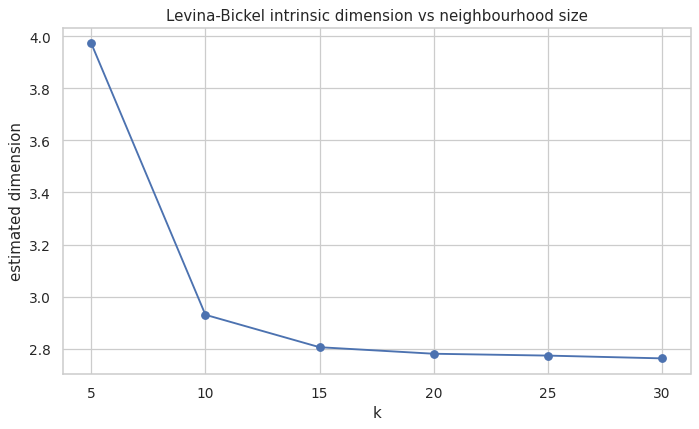

Average estimate: 3.0


In [131]:
# Module 6.5 | Intrinsic dimensionality - Levina-Bickel maximum likelihood nearest-neighbour estimator for a range of neighbourhood sizes
def mle_dimension(Z, k):
    dist = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)[0][:, 1:]
    return np.mean((k - 1) / np.log(dist[:, -1][:, None] / dist[:, :-1]).sum(axis=1))

Xj = X + np.random.default_rng(RANDOM_STATE).normal(0, 1e-3, X.shape)
mle_est = pd.Series({k: mle_dimension(Xj, k) for k in range(5, 31, 5)}, name='MLE dimension')
mle_est.plot(marker='o', title='Levina-Bickel intrinsic dimension vs neighbourhood size')
plt.xlabel('k')
plt.ylabel('estimated dimension')
plt.show()
print('Average estimate:', round(mle_est.mean(), 2))

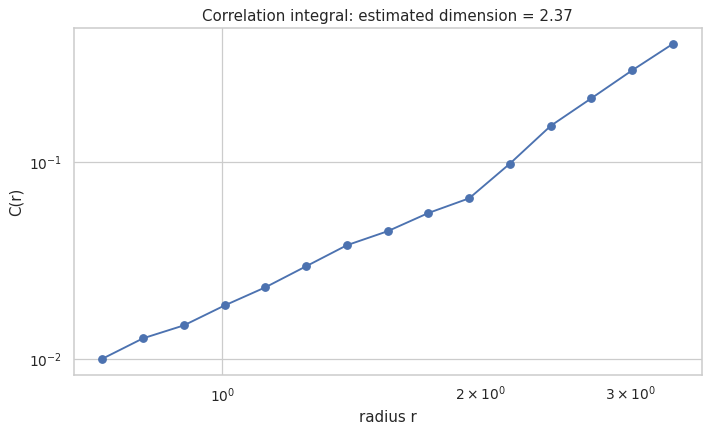

In [132]:
# Module 6.5 | Intrinsic dimensionality - correlation dimension (Grassberger-Procaccia): slope of log C(r) versus log r
sub = Xj[np.random.default_rng(RANDOM_STATE).choice(len(Xj), 800, replace=False)]
pd_all = pdist(sub)
radii = np.logspace(np.log10(np.percentile(pd_all, 1)), np.log10(np.percentile(pd_all, 40)), 15)
corr_int = np.array([(pd_all < r).mean() for r in radii])
slope = np.polyfit(np.log(radii), np.log(corr_int), 1)[0]
plt.loglog(radii, corr_int, marker='o')
plt.title(f'Correlation integral: estimated dimension = {slope:.2f}')
plt.xlabel('radius r')
plt.ylabel('C(r)')
plt.show()

## 6.6 Multidimensional scaling

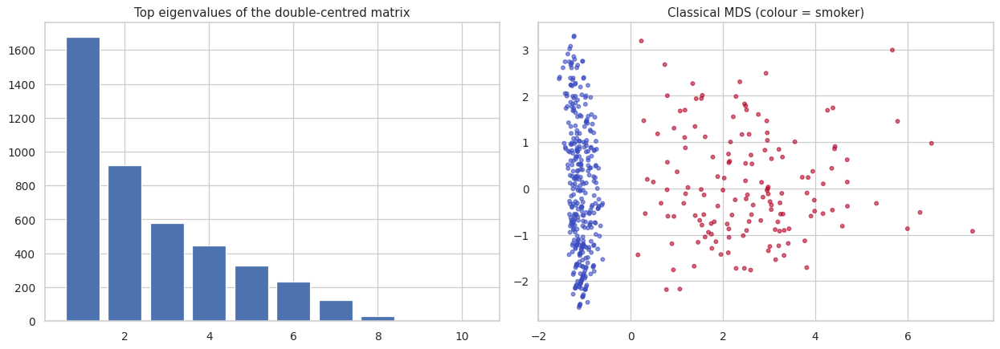

Max |classical MDS - PCA| distance difference check (should be ~0 for Euclidean): 0.0


In [133]:
# Module 6.6 | Multidimensional scaling - classical (Torgerson) MDS from scratch on a random subsample, with eigenvalue spectrum
idx = np.random.default_rng(RANDOM_STATE).choice(len(X), 500, replace=False)
Xs_sub = X[idx]
D_sub = squareform(pdist(Xs_sub))
J = np.eye(len(idx)) - np.ones((len(idx), len(idx))) / len(idx)
B = -0.5 * J @ (D_sub ** 2) @ J
ev, evec = np.linalg.eigh(B)
order_ev = np.argsort(ev)[::-1]
ev, evec = ev[order_ev], evec[:, order_ev]
classical = evec[:, :2] * np.sqrt(ev[:2])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, 11), ev[:10])
axes[0].set_title('Top eigenvalues of the double-centred matrix')
axes[1].scatter(classical[:, 0], classical[:, 1], c=clean['smoke_flag'].values[idx], cmap='coolwarm', s=14, alpha=0.6)
axes[1].set_title('Classical MDS (colour = smoker)')
plt.tight_layout()
plt.show()
print('Max |classical MDS - PCA| distance difference check (should be ~0 for Euclidean):',
      np.abs(np.abs(classical[:, 0]) - np.abs(PCA(2).fit_transform(Xs_sub)[:, 0])).max().round(6))

Metric MDS stress: 53016.76 | non-metric MDS stress: 0.1807


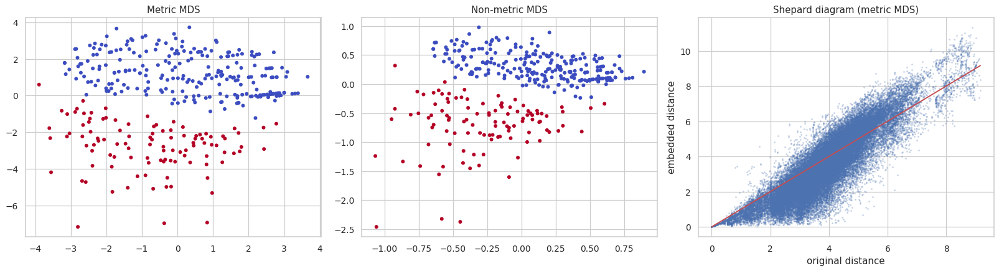

In [134]:
# Module 6.6 | Multidimensional scaling - metric and non-metric SMACOF MDS with stress values and Shepard diagram
from sklearn.manifold import MDS
idx2 = idx[:350]
Xm = X[idx2]
def make_mds(metric_flag):
    try:
        return MDS(n_components=2, metric_mds=metric_flag, n_init=1, max_iter=200, random_state=RANDOM_STATE, init='random')
    except TypeError:
        return MDS(n_components=2, metric=metric_flag, n_init=1, max_iter=200, random_state=RANDOM_STATE)
mds_m, mds_n = make_mds(True), make_mds(False)
emb_m, emb_n = mds_m.fit_transform(Xm), mds_n.fit_transform(Xm)
print('Metric MDS stress:', round(mds_m.stress_, 2), '| non-metric MDS stress:', round(mds_n.stress_, 4))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(emb_m[:, 0], emb_m[:, 1], c=clean['smoke_flag'].values[idx2], cmap='coolwarm', s=14)
axes[0].set_title('Metric MDS')
axes[1].scatter(emb_n[:, 0], emb_n[:, 1], c=clean['smoke_flag'].values[idx2], cmap='coolwarm', s=14)
axes[1].set_title('Non-metric MDS')
axes[2].scatter(pdist(Xm), pdist(emb_m), s=2, alpha=0.2)
axes[2].plot([0, pdist(Xm).max()], [0, pdist(Xm).max()], 'r')
axes[2].set_title('Shepard diagram (metric MDS)')
axes[2].set_xlabel('original distance')
axes[2].set_ylabel('embedded distance')
plt.tight_layout()
plt.show()

## 6.7 Manifold learning

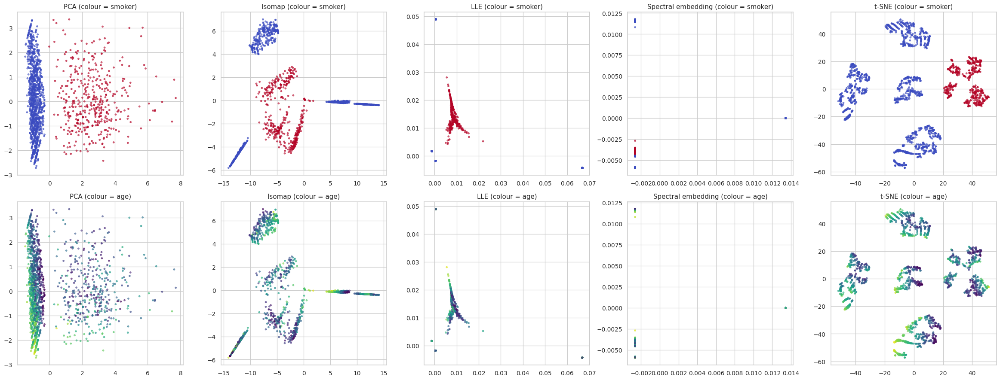

In [135]:
# Module 6.7 | Manifold learning - Isomap, Locally Linear Embedding, Spectral Embedding and t-SNE compared with PCA
from sklearn.manifold import Isomap, LocallyLinearEmbedding, SpectralEmbedding, TSNE
embeddings = {
    'PCA': pca2,
    'Isomap': Isomap(n_neighbors=15, n_components=2).fit_transform(X),
    'LLE': LocallyLinearEmbedding(n_neighbors=15, n_components=2, reg=1e-2, random_state=RANDOM_STATE).fit_transform(X),
    'Spectral embedding': SpectralEmbedding(n_components=2, n_neighbors=15, random_state=RANDOM_STATE).fit_transform(X),
    't-SNE': TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, init='pca').fit_transform(X)}
fig, axes = plt.subplots(2, 5, figsize=(26, 10))
for j, (name, E) in enumerate(embeddings.items()):
    axes[0, j].scatter(E[:, 0], E[:, 1], c=clean['smoke_flag'], cmap='coolwarm', s=8, alpha=0.6)
    axes[0, j].set_title(f'{name} (colour = smoker)')
    axes[1, j].scatter(E[:, 0], E[:, 1], c=clean['age'], cmap='viridis', s=8, alpha=0.6)
    axes[1, j].set_title(f'{name} (colour = age)')
plt.tight_layout()
plt.show()

In [136]:
# Module 6.7 | Manifold learning - quantitative comparison with trustworthiness and continuity of neighbourhoods
from sklearn.manifold import trustworthiness
sub_idx = np.random.default_rng(RANDOM_STATE).choice(len(X), 800, replace=False)
rows = []
for name, E in embeddings.items():
    rows.append((name, trustworthiness(X[sub_idx], E[sub_idx], n_neighbors=10), trustworthiness(E[sub_idx], X[sub_idx], n_neighbors=10)))
pd.DataFrame(rows, columns=['method', 'trustworthiness', 'continuity']).set_index('method').sort_values('trustworthiness', ascending=False).round(4)

,trustworthiness,continuity
method,,
t-SNE,0.9959,0.9929
Spectral embedding,0.9450,0.9659
LLE,0.9370,0.9276
Isomap,0.9249,0.9790
PCA,0.8720,0.9591


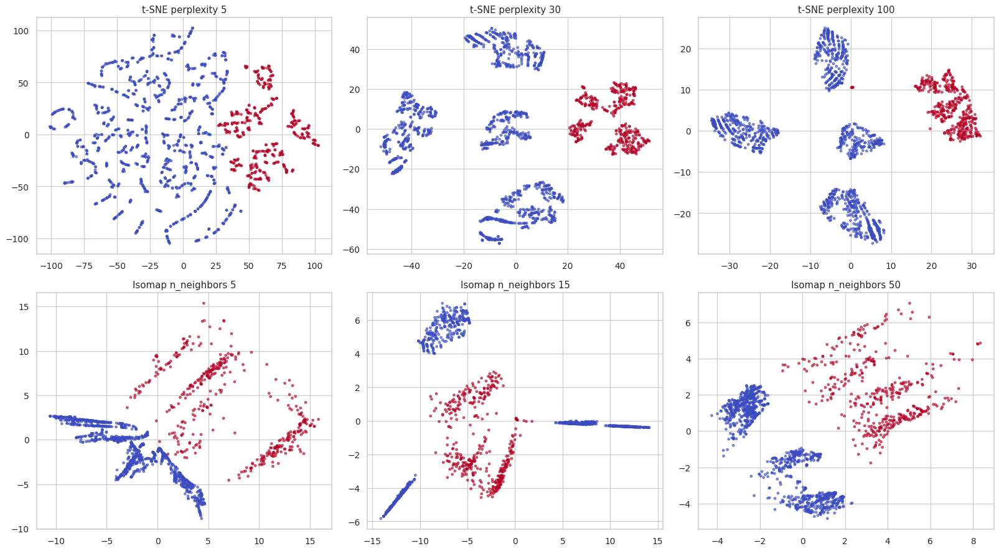

In [137]:
# Module 6.7 | Manifold learning - effect of the t-SNE perplexity and Isomap neighbourhood size on the embedding
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, perp in zip(axes[0], [5, 30, 100]):
    E = TSNE(n_components=2, perplexity=perp, random_state=RANDOM_STATE, init='pca').fit_transform(X)
    ax.scatter(E[:, 0], E[:, 1], c=clean['smoke_flag'], cmap='coolwarm', s=8, alpha=0.6)
    ax.set_title(f't-SNE perplexity {perp}')
for ax, nn in zip(axes[1], [5, 15, 50]):
    E = Isomap(n_neighbors=nn, n_components=2).fit_transform(X)
    ax.scatter(E[:, 0], E[:, 1], c=clean['smoke_flag'], cmap='coolwarm', s=8, alpha=0.6)
    ax.set_title(f'Isomap n_neighbors {nn}')
plt.tight_layout()
plt.show()

## 6.8 Self-Organizing Maps

In [138]:
# Module 6.8 | Self-Organizing Map - implement and train a 12 x 12 SOM from scratch with decaying learning rate and neighbourhood radius
def train_som(Z, rows=12, cols=12, n_iter=20000, lr0=0.5, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    d = Z.shape[1]
    weights = Z[rng.choice(len(Z), rows * cols)].reshape(rows, cols, d).copy()
    gy, gx = np.mgrid[0:rows, 0:cols]
    sigma0 = max(rows, cols) / 2
    for t in range(n_iter):
        frac = t / n_iter
        lr = lr0 * (0.01 / lr0) ** frac
        sigma = sigma0 * (1 / sigma0) ** frac + 0.3
        x = Z[rng.integers(len(Z))]
        dist = np.linalg.norm(weights - x, axis=2)
        by, bx = np.unravel_index(dist.argmin(), dist.shape)
        h = np.exp(-((gy - by) ** 2 + (gx - bx) ** 2) / (2 * sigma ** 2))
        weights += lr * h[:, :, None] * (x - weights)
    return weights

som = train_som(X)
def som_bmus(weights, Z):
    flat = weights.reshape(-1, weights.shape[2])
    d2 = ((Z[:, None, :] - flat[None, :, :]) ** 2).sum(axis=2)
    order_idx = np.argsort(d2, axis=1)[:, :2]
    return np.column_stack(np.unravel_index(order_idx[:, 0], weights.shape[:2])), np.column_stack(np.unravel_index(order_idx[:, 1], weights.shape[:2])), d2.min(axis=1)
bmu1, bmu2, d2min = som_bmus(som, X)
quant_err = np.sqrt(d2min).mean()
topo_err = np.mean(np.abs(bmu1 - bmu2).max(axis=1) > 1)
print(f'Quantization error: {quant_err:.4f} | Topographic error: {topo_err:.4f}')

Quantization error: 1.1370 | Topographic error: 0.0102


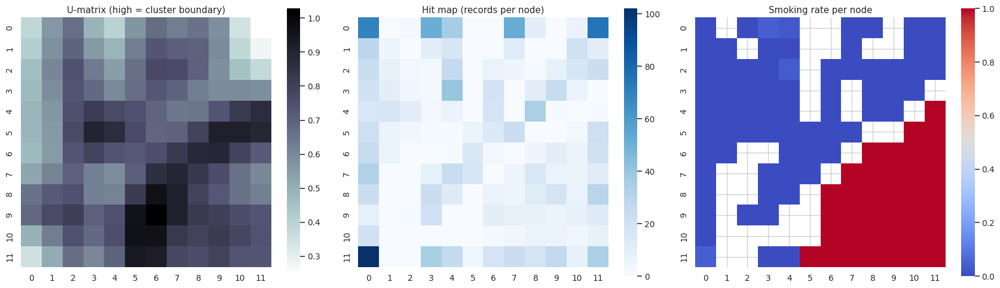

In [139]:
# Module 6.8 | Self-Organizing Map - U-matrix of neighbour distances, hit map and smoking-rate map
rows_, cols_ = som.shape[:2]
umat = np.zeros((rows_, cols_))
for i in range(rows_):
    for j in range(cols_):
        neigh = [(i + di, j + dj) for di in (-1, 0, 1) for dj in (-1, 0, 1) if (di or dj) and 0 <= i + di < rows_ and 0 <= j + dj < cols_]
        umat[i, j] = np.mean([np.linalg.norm(som[i, j] - som[a, b]) for a, b in neigh])
hits = np.zeros((rows_, cols_))
smoke_sum = np.zeros((rows_, cols_))
for (i, j), s in zip(bmu1, clean['smoke_flag']):
    hits[i, j] += 1
    smoke_sum[i, j] += s
smoke_map = np.divide(smoke_sum, hits, out=np.full_like(hits, np.nan), where=hits > 0)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, M, t, cm_ in zip(axes, [umat, hits, smoke_map], ['U-matrix (high = cluster boundary)', 'Hit map (records per node)', 'Smoking rate per node'], ['bone_r', 'Blues', 'coolwarm']):
    sns.heatmap(M, ax=ax, cmap=cm_, square=True, cbar=True)
    ax.set_title(t)
plt.tight_layout()
plt.show()

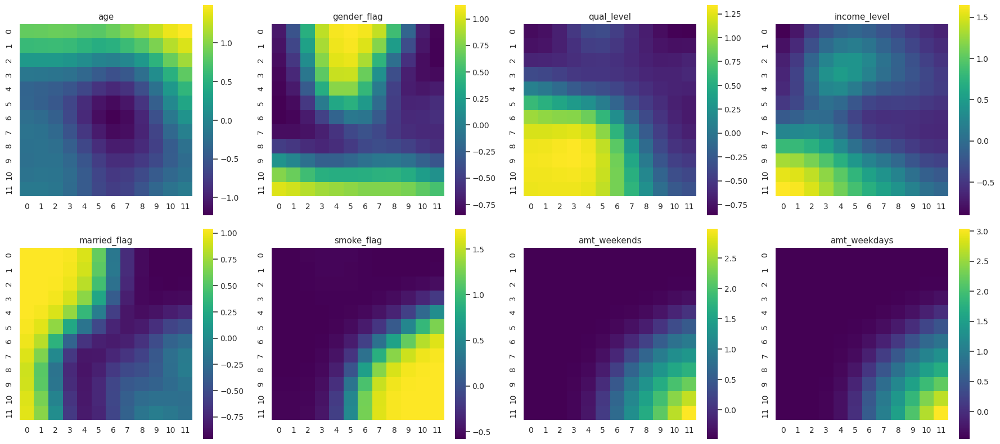

In [140]:
# Module 6.8 | Self-Organizing Map - component planes showing how each feature varies across the map
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for k, (ax, f) in enumerate(zip(axes.ravel(), feat_cols)):
    sns.heatmap(som[:, :, k], ax=ax, cmap='viridis', square=True, cbar=True)
    ax.set_title(f)
plt.tight_layout()
plt.show()

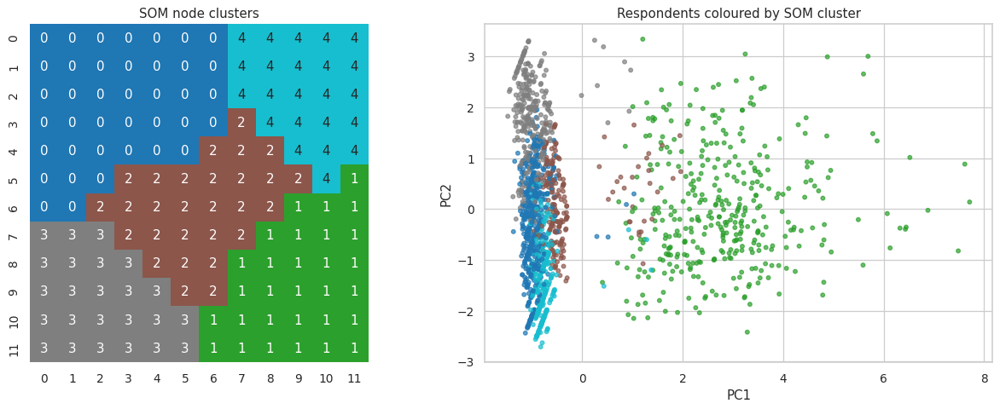

ARI SOM clusters vs k-means: 0.671


In [141]:
# Module 6.8 | Self-Organizing Map - cluster the SOM codebook vectors with k-means and map the clusters back to the respondents
node_clusters = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(som.reshape(-1, som.shape[2])).reshape(rows_, cols_)
labels['SOM + k-means'] = node_clusters[bmu1[:, 0], bmu1[:, 1]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(node_clusters, ax=axes[0], cmap='tab10', square=True, cbar=False, annot=True)
axes[0].set_title('SOM node clusters')
show_clusters(labels['SOM + k-means'], 'Respondents coloured by SOM cluster', axes[1])
plt.tight_layout()
plt.show()
print('ARI SOM clusters vs k-means:', round(adjusted_rand_score(labels['SOM + k-means'], labels['K-means']), 3))

# Module 7: Model Development and Evaluation

## 7.1 Constructing a linear regression model
Target: **weekday cigarettes per day (`amt_weekdays`) among smokers**.

In [142]:
# Module 7.1 | Linear regression data - assemble predictors for smokers (demographics, weekend consumption, cigarette type) and split into train and test
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.model_selection import cross_validate, KFold, cross_val_predict
import statsmodels.api as sm_api
reg_data = pd.concat([smokers[['age', 'gender_flag', 'qual_level', 'income_level', 'married_flag', 'amt_weekends']],
                      pd.get_dummies(smokers['type_simple'], drop_first=True, dtype=int)], axis=1)
reg_y = smokers['amt_weekdays']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(reg_data, reg_y, test_size=0.2, random_state=RANDOM_STATE)
print('Predictors:', list(reg_data.columns))
print('Train:', Xr_tr.shape, '| Test:', Xr_te.shape)

Predictors: ['age', 'gender_flag', 'qual_level', 'income_level', 'married_flag', 'amt_weekends', 'Packets']
Train: (336, 7) | Test: (85, 7)


amt_weekdays = 1.372 + 0.746 x amt_weekends
R2 on train: 0.618 | R2 on test: 0.7336


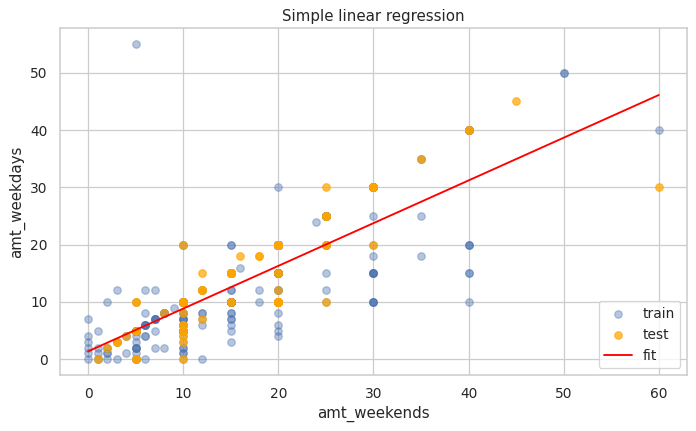

In [143]:
# Module 7.1 | Simple linear regression - weekday on weekend consumption with coefficients, equation and fitted line
slr = LinearRegression().fit(Xr_tr[['amt_weekends']], yr_tr)
print(f'amt_weekdays = {slr.intercept_:.3f} + {slr.coef_[0]:.3f} x amt_weekends')
print('R2 on train:', round(slr.score(Xr_tr[['amt_weekends']], yr_tr), 4), '| R2 on test:', round(slr.score(Xr_te[['amt_weekends']], yr_te), 4))
grid = np.linspace(0, reg_data['amt_weekends'].max(), 50).reshape(-1, 1)
plt.scatter(Xr_tr['amt_weekends'], yr_tr, alpha=0.4, label='train')
plt.scatter(Xr_te['amt_weekends'], yr_te, alpha=0.7, color='orange', label='test')
plt.plot(grid, slr.predict(pd.DataFrame(grid, columns=['amt_weekends'])), color='red', label='fit')
plt.xlabel('amt_weekends')
plt.ylabel('amt_weekdays')
plt.legend()
plt.title('Simple linear regression')
plt.show()

In [144]:
# Module 7.1 | Multiple linear regression - fit on the training set and display coefficients with the full statsmodels OLS summary
mlr = LinearRegression().fit(Xr_tr, yr_tr)
coef = pd.Series(mlr.coef_, index=reg_data.columns).rename('coefficient')
display(pd.concat([coef, pd.Series({'intercept': mlr.intercept_})]).to_frame('coefficient').round(4))
ols = sm_api.OLS(yr_tr, sm_api.add_constant(Xr_tr)).fit()
print(ols.summary())

,coefficient
age,0.0882
gender_flag,1.1605
qual_level,0.2182
income_level,0.0516
married_flag,0.3668
amt_weekends,0.7338
Packets,-0.3560
intercept,-3.2441


                            OLS Regression Results                            
Dep. Variable:           amt_weekdays   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.641
Method:                 Least Squares   F-statistic:                     86.47
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           1.20e-70
Time:                        08:36:50   Log-Likelihood:                -1051.7
No. Observations:                 336   AIC:                             2119.
Df Residuals:                     328   BIC:                             2150.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -3.2441      1.326     -2.447   

## 7.2 Evaluation of the regression model

In [145]:
# Module 7.2 | Regression evaluation - R-squared, adjusted R-squared, MAE, MSE, RMSE, median absolute error and explained variance on train and test
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, median_absolute_error, explained_variance_score
def reg_metrics(model, Xa, ya):
    pred = model.predict(Xa)
    n_, p_ = Xa.shape
    r2 = r2_score(ya, pred)
    return {'R2': r2, 'adjusted R2': 1 - (1 - r2) * (n_ - 1) / (n_ - p_ - 1), 'MAE': mean_absolute_error(ya, pred), 'MSE': mean_squared_error(ya, pred),
            'RMSE': np.sqrt(mean_squared_error(ya, pred)), 'median AE': median_absolute_error(ya, pred), 'explained variance': explained_variance_score(ya, pred)}
pd.DataFrame({'train': reg_metrics(mlr, Xr_tr, yr_tr), 'test': reg_metrics(mlr, Xr_te, yr_te)}).round(4)

,train,test
R2,0.6486,0.7556
adjusted R2,0.6411,0.7333
MAE,4.0671,3.7811
MSE,30.6418,21.9219
RMSE,5.5355,4.6821
median AE,3.3437,3.1733
explained variance,0.6486,0.7657


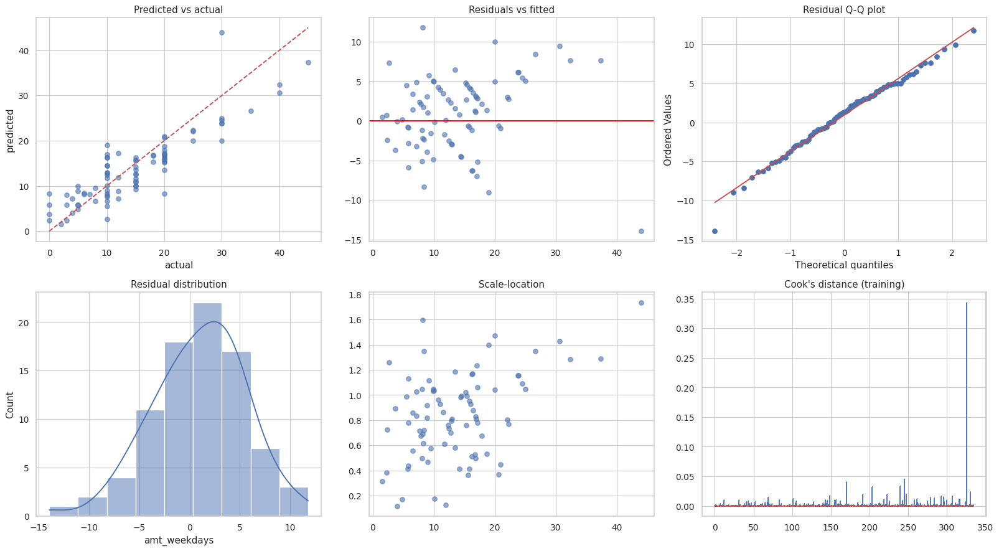

In [146]:
# Module 7.2 | Regression evaluation - predicted vs actual plot and residual diagnostics (residual vs fitted, Q-Q, histogram, scale-location)
pred_te = mlr.predict(Xr_te)
resid = yr_te - pred_te
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes[0, 0].scatter(yr_te, pred_te, alpha=0.6)
axes[0, 0].plot([0, yr_te.max()], [0, yr_te.max()], 'r--')
axes[0, 0].set_title('Predicted vs actual')
axes[0, 0].set_xlabel('actual')
axes[0, 0].set_ylabel('predicted')
axes[0, 1].scatter(pred_te, resid, alpha=0.6)
axes[0, 1].axhline(0, color='red')
axes[0, 1].set_title('Residuals vs fitted')
stats.probplot(resid, dist='norm', plot=axes[0, 2])
axes[0, 2].set_title('Residual Q-Q plot')
sns.histplot(resid, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Residual distribution')
axes[1, 1].scatter(pred_te, np.sqrt(np.abs(resid / resid.std())), alpha=0.6)
axes[1, 1].set_title('Scale-location')
infl = ols.get_influence()
axes[1, 2].stem(infl.cooks_distance[0], markerfmt=',')
axes[1, 2].set_title("Cook's distance (training)")
plt.tight_layout()
plt.show()

In [147]:
# Module 7.2 | Regression evaluation - assumption tests: normality of residuals, homoscedasticity, autocorrelation, multicollinearity
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
res_tr = ols.resid
bp = het_breuschpagan(res_tr, ols.model.exog)
print(f'Shapiro-Wilk p (residual normality): {stats.shapiro(res_tr)[1]:.4g}')
print(f'Breusch-Pagan p (constant variance): {bp[1]:.4g}')
print(f'Durbin-Watson (about 2 means no autocorrelation): {durbin_watson(res_tr):.3f}')
vif_tbl = pd.Series([variance_inflation_factor(sm_api.add_constant(Xr_tr).values, i + 1) for i in range(Xr_tr.shape[1])], index=Xr_tr.columns, name='VIF')
display(vif_tbl.round(3).to_frame())
print('Influential points (Cooks D > 4/n):', int((infl.cooks_distance[0] > 4 / len(Xr_tr)).sum()))

Shapiro-Wilk p (residual normality): 3.85e-14
Breusch-Pagan p (constant variance): 0.1788
Durbin-Watson (about 2 means no autocorrelation): 1.936


,VIF
age,1.107
gender_flag,1.206
qual_level,1.333
income_level,1.331
married_flag,1.050
amt_weekends,1.063
Packets,1.073


Influential points (Cooks D > 4/n): 18


,CV R2 mean,CV R2 std,CV RMSE,CV MAE,test R2
model,,,,,
Baseline (mean),-0.0309,0.0442,9.4228,7.3809,-0.0164
Linear regression,0.6511,0.1381,5.3981,4.0633,0.7556
Ridge (CV alpha),0.6510,0.1363,5.4012,4.0778,0.7539
Lasso (CV alpha),0.6507,0.1393,5.4004,4.0645,0.7543


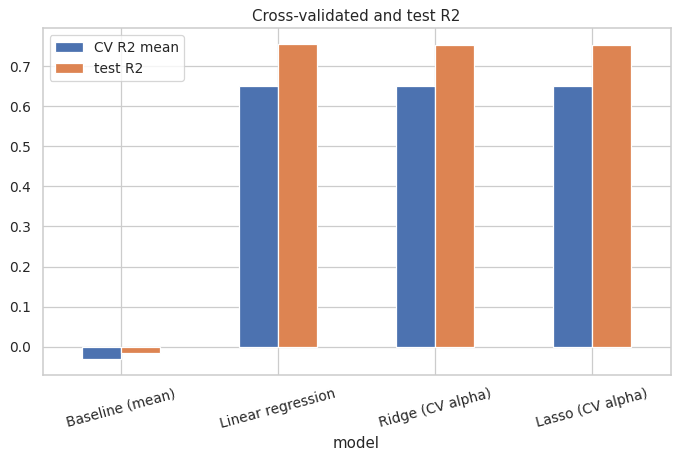

In [148]:
# Module 7.2 | Regression evaluation - 5-fold cross-validation and comparison with a mean-only baseline, Ridge and Lasso models
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {'Baseline (mean)': DummyRegressor(), 'Linear regression': LinearRegression(),
          'Ridge (CV alpha)': make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 30))),
          'Lasso (CV alpha)': make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=10000))}
rows = []
for name, mdl in models.items():
    cvres = cross_validate(mdl, reg_data, reg_y, cv=kf, scoring=['r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_error'])
    mdl.fit(Xr_tr, yr_tr)
    rows.append((name, cvres['test_r2'].mean(), cvres['test_r2'].std(), -cvres['test_neg_root_mean_squared_error'].mean(), -cvres['test_neg_mean_absolute_error'].mean(),
                 r2_score(yr_te, mdl.predict(Xr_te))))
cv_table = pd.DataFrame(rows, columns=['model', 'CV R2 mean', 'CV R2 std', 'CV RMSE', 'CV MAE', 'test R2']).set_index('model')
display(cv_table.round(4))
cv_table[['CV R2 mean', 'test R2']].plot(kind='bar', rot=15, title='Cross-validated and test R2')
plt.show()

## 7.3 Computing and understanding accuracy

In [149]:
# Module 7.3 | Understanding accuracy (regression) - percentage of predictions within a tolerance, and error relative to the spread of the target
within = pd.DataFrame({f'within +/-{t}': [(np.abs(resid) <= t).mean() * 100] for t in (1, 2, 3, 5, 10)}, index=['% of test predictions'])
display(within.round(1))
print('Baseline RMSE (always predict train mean):', round(np.sqrt(mean_squared_error(yr_te, np.full(len(yr_te), yr_tr.mean()))), 3))
print('Model RMSE                              :', round(np.sqrt(mean_squared_error(yr_te, pred_te)), 3))
print('Std of target on test set               :', round(yr_te.std(), 3))
print('RMSE as % of target mean                :', round(100 * np.sqrt(mean_squared_error(yr_te, pred_te)) / yr_te.mean(), 1))

,within +/-1,within +/-2,within +/-3,within +/-5,within +/-10
% of test predictions,15.3,28.2,45.9,72.9,97.6


Baseline RMSE (always predict train mean): 9.547
Model RMSE                              : 4.682
Std of target on test set               : 9.526
RMSE as % of target mean                : 31.8


In [150]:
# Module 7.3 | Computing accuracy (classification) - logistic regression predicting smoking status: accuracy against the majority-class baseline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve, classification_report
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xfs, yfs, test_size=0.25, stratify=yfs, random_state=RANDOM_STATE)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xc_tr, yc_tr)
pred_c = logit.predict(Xc_te)
proba_c = logit.predict_proba(Xc_te)[:, 1]
print('Accuracy                    :', round(accuracy_score(yc_te, pred_c), 4))
print('Majority-class baseline     :', round(max(yc_te.mean(), 1 - yc_te.mean()), 4))
print('Balanced accuracy           :', round(balanced_accuracy_score(yc_te, pred_c), 4))
print('Precision / Recall / F1     :', round(precision_score(yc_te, pred_c), 4), round(recall_score(yc_te, pred_c), 4), round(f1_score(yc_te, pred_c), 4))
print('ROC AUC                     :', round(roc_auc_score(yc_te, proba_c), 4))
print(classification_report(yc_te, pred_c, target_names=['Non-smoker', 'Smoker']))

Accuracy                    : 0.7249
Majority-class baseline     : 0.7488
Balanced accuracy           : 0.5188
Precision / Recall / F1     : 0.3438 0.1048 0.1606
ROC AUC                     : 0.6363
              precision    recall  f1-score   support

  Non-smoker       0.76      0.93      0.84       313
      Smoker       0.34      0.10      0.16       105

    accuracy                           0.72       418
   macro avg       0.55      0.52      0.50       418
weighted avg       0.65      0.72      0.67       418



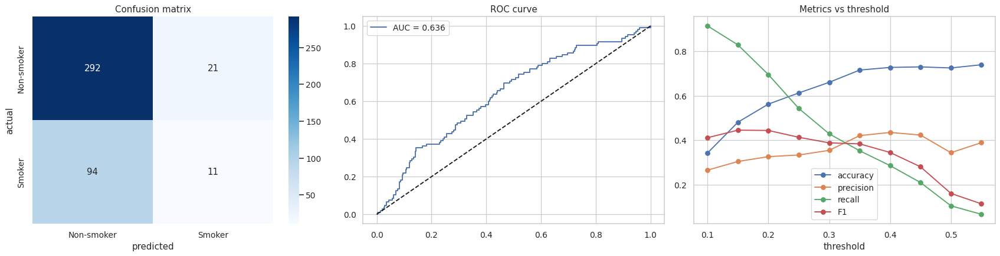

,accuracy,precision,recall,F1
threshold,,,,
0.10,0.342,0.265,0.914,0.411
0.15,0.481,0.304,0.829,0.445
0.20,0.562,0.326,0.695,0.444
0.25,0.612,0.333,0.543,0.413
0.30,0.660,0.354,0.429,0.388
0.35,0.715,0.420,0.352,0.383
0.40,0.727,0.435,0.286,0.345
0.45,0.730,0.423,0.210,0.280
0.50,0.725,0.344,0.105,0.161


In [151]:
# Module 7.3 | Understanding accuracy (classification) - confusion matrix, ROC curve and the effect of the decision threshold
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(confusion_matrix(yc_te, pred_c), annot=True, fmt='d', cmap='Blues', xticklabels=['Non-smoker', 'Smoker'], yticklabels=['Non-smoker', 'Smoker'], ax=axes[0])
axes[0].set_title('Confusion matrix')
axes[0].set_xlabel('predicted')
axes[0].set_ylabel('actual')
fpr, tpr, _ = roc_curve(yc_te, proba_c)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(yc_te, proba_c):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].legend()
axes[1].set_title('ROC curve')
thr_rows = []
for t in np.arange(0.1, 0.6, 0.05):
    pr = (proba_c >= t).astype(int)
    thr_rows.append((t, accuracy_score(yc_te, pr), precision_score(yc_te, pr, zero_division=0), recall_score(yc_te, pr), f1_score(yc_te, pr)))
thr_tbl = pd.DataFrame(thr_rows, columns=['threshold', 'accuracy', 'precision', 'recall', 'F1']).set_index('threshold')
thr_tbl.plot(ax=axes[2], marker='o', title='Metrics vs threshold')
plt.tight_layout()
plt.show()
display(thr_tbl.round(3))

In [152]:
# Module 7.3 | Understanding accuracy (classification) - stratified cross-validated accuracy, class-weighted model and why accuracy alone is misleading
from sklearn.model_selection import StratifiedKFold, cross_val_score
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
variants = {'Majority baseline': __import__('sklearn.dummy', fromlist=['DummyClassifier']).DummyClassifier(strategy='most_frequent'),
            'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
            'Logistic (balanced weights)': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
            'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)}
rows = []
for name, mdl in variants.items():
    acc = cross_val_score(mdl, Xfs, yfs, cv=skf, scoring='accuracy')
    bal = cross_val_score(mdl, Xfs, yfs, cv=skf, scoring='balanced_accuracy')
    rec = cross_val_score(mdl, Xfs, yfs, cv=skf, scoring='recall')
    rows.append((name, acc.mean(), bal.mean(), rec.mean()))
pd.DataFrame(rows, columns=['model', 'CV accuracy', 'CV balanced accuracy', 'CV recall (smokers)']).set_index('model').round(4)

,CV accuracy,CV balanced accuracy,CV recall (smokers)
model,,,
Majority baseline,0.7479,0.5000,0.0000
Logistic regression,0.7401,0.5420,0.1425
Logistic (balanced weights),0.6587,0.6538,0.6439
Random forest,0.7491,0.5322,0.0949


## 7.4 Reinforcement learning
| | Supervised learning | Reinforcement learning |
|---|---|---|
| Feedback | Correct label for every example | Scalar reward after an action, often delayed |
| Data | Fixed, labelled dataset | Generated by the agent's own interaction with an environment |
| Goal | Minimise prediction error | Maximise cumulative reward through a policy |
| Key issue | Generalisation | Exploration vs exploitation |
| Example here | Predicting smoker / non-smoker from demographics (7.3) | Learning which income group to target in a campaign (below) |

**Applications of reinforcement learning:** game playing (AlphaGo), robotics control, recommendation and ad placement, dynamic pricing, autonomous driving, resource scheduling, personalised health interventions.

**Experiment:** a public-health campaign must choose which of the 8 income bands to target. Each pull of an arm contacts a random respondent from that band; reward = 1 if the person smokes. The agent does not know the rates and must learn them (multi-armed bandit).

In [153]:
# Module 7.4 | Reinforcement learning environment - empirical smoking rate of each income band as the hidden reward probability of each arm
true_rates = clean.groupby('income_level')['smoke_flag'].mean().values
best_arm = int(true_rates.argmax())
arms = pd.DataFrame({'arm (income level)': range(len(true_rates)), 'income band': income_order, 'true smoking rate': true_rates.round(4)}).set_index('arm (income level)')
display(arms)
print('Optimal arm:', best_arm, '->', income_order[best_arm])

,income band,true smoking rate
arm (income level),,
0,"Under 2,600",0.2769
1,"2,600 to 5,200",0.2510
2,"5,200 to 10,400",0.2676
3,"10,400 to 15,600",0.2927
4,"15,600 to 20,800",0.2419
5,"20,800 to 28,600",0.2452
6,"28,600 to 36,400",0.1139
7,"Above 36,400",0.1667


Optimal arm: 3 -> 10,400 to 15,600


In [154]:
# Module 7.4 | Reinforcement learning agents - random, greedy, epsilon-greedy, UCB1 and Thompson sampling bandit policies
def run_bandit(policy, T=3000, runs=30, eps=0.1, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n_arms = len(true_rates)
    regret = np.zeros((runs, T))
    best_pulls = np.zeros((runs, T))
    final_q = np.zeros((runs, n_arms))
    for r in range(runs):
        counts = np.zeros(n_arms)
        wins = np.zeros(n_arms)
        for t in range(T):
            if policy == 'random':
                a = rng.integers(n_arms)
            elif t < n_arms:
                a = t
            elif policy == 'greedy':
                a = int(np.argmax(wins / counts))
            elif policy == 'epsilon-greedy':
                a = rng.integers(n_arms) if rng.random() < eps else int(np.argmax(wins / counts))
            elif policy == 'UCB1':
                a = int(np.argmax(wins / counts + np.sqrt(2 * np.log(t + 1) / counts)))
            else:
                a = int(np.argmax(rng.beta(1 + wins, 1 + counts - wins)))
            reward = float(rng.random() < true_rates[a])
            counts[a] += 1
            wins[a] += reward
            regret[r, t] = true_rates[best_arm] - true_rates[a]
            best_pulls[r, t] = a == best_arm
        final_q[r] = np.divide(wins, counts, out=np.zeros(n_arms), where=counts > 0)
    return regret.cumsum(axis=1).mean(axis=0), best_pulls.mean(axis=0), final_q.mean(axis=0)

policies = ['random', 'greedy', 'epsilon-greedy', 'UCB1', 'Thompson']
bandit_results = {p: run_bandit(p) for p in policies}
print('Simulated', len(policies), 'policies')

Simulated 5 policies


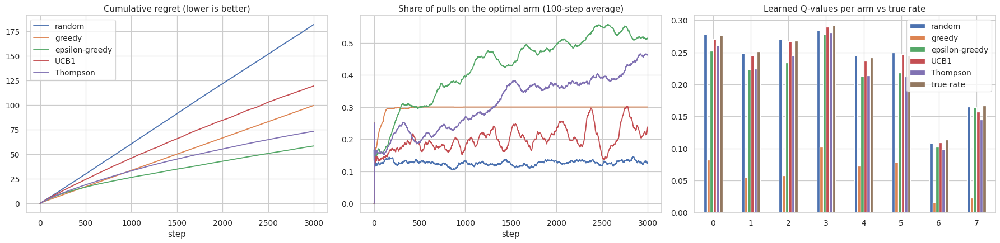

,final cumulative regret,optimal-arm share (last 500 steps)
random,181.861,0.129
greedy,99.593,0.300
epsilon-greedy,58.433,0.529
UCB1,119.395,0.234
Thompson,73.381,0.427


In [155]:
# Module 7.4 | Reinforcement learning results - cumulative regret, share of optimal-arm pulls and learned action values versus the true rates
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for p, (reg_curve, best_curve, q) in bandit_results.items():
    axes[0].plot(reg_curve, label=p)
    axes[1].plot(pd.Series(best_curve).rolling(100, min_periods=1).mean(), label=p)
axes[0].set_title('Cumulative regret (lower is better)')
axes[0].set_xlabel('step')
axes[0].legend()
axes[1].set_title('Share of pulls on the optimal arm (100-step average)')
axes[1].set_xlabel('step')
q_tbl = pd.DataFrame({p: v[2] for p, v in bandit_results.items()})
q_tbl['true rate'] = true_rates
q_tbl.plot(kind='bar', ax=axes[2], rot=0, title='Learned Q-values per arm vs true rate')
plt.tight_layout()
plt.show()
pd.DataFrame({p: {'final cumulative regret': v[0][-1], 'optimal-arm share (last 500 steps)': v[1][-500:].mean()} for p, v in bandit_results.items()}).T.round(3)